# Notes

# Setup

In [2]:
print('hello')

hello


In [3]:
%load_ext autoreload
%autoreload 2

import os
import re
from scipy import stats

import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
import numpy as np
import rasterio

import config
import hatfield_funcs as hf
import hatfield_funcs.helpers as hfh

from pathlib import Path
import sys

project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))

from my_extra_to_hatfield_funcs.io_funcs import (
    read_xlsx,
    read_df_from_csv,
    write_df_to_csv,
    read_geojson,
    write_geojson,
)

from biofilm_data.io import (
    load_full_station_dataset,
    load_calibration_curves,
)

from biofilm_data.plot import (
    plot_r_vs_s_comparison,
    plot_area_round_boxplots,
    internal_correlation_heatmap,
    external_correlation_heatmap,
)

from biofilm_data.calibration_curve import (
    fit_linear_calibration,
    plot_calibration_fit,
    mean_response_with_ci,
)

plt.style.use("default")
%config InlineBackend.figure_format = 'retina'

In [4]:
if os.getenv("GA_STORAGE_ACCOUNT_NAME") is None:
    raise RuntimeError(
        "This notebook is configured for Azure cloud storage. "
        "Set GA_STORAGE_ACCOUNT_NAME before running it."
    )

hf.config.configure_azure()
hf.config.configure_data_root_path(config.CONTAINER_NAME)

# Parameters

In [5]:
X_VARIABLE = "gt_ndvi_mean"

# Read Data

In [6]:
df_all_R = load_full_station_dataset(
    config.CONTAINER_FILE_PATHS["full_station_dataset_R_geojson"],
    r_only=True
)

display(df_all_R.head())

date  elevation             low_tide_time  \
site      round station_id                                                   
brunswick 1     B1         2026-05-03    3.46975 2026-05-03 13:10:00-07:00   
                B10        2026-05-01    3.37800 2026-05-01 12:11:00-07:00   
                B11        2026-05-01    3.20575 2026-05-01 12:11:00-07:00   
                B12        2026-05-01    3.04725 2026-05-01 12:11:00-07:00   
                B13        2026-05-01    2.85350 2026-05-01 12:11:00-07:00   

                            low_tide_level            emergence_time  \
site      round station_id                                             
brunswick 1     B1                   0.862 2026-05-03 07:28:43-07:00   
                B10                  1.053 2026-05-01 07:07:45-07:00   
                B11                  1.053 2026-05-01 07:28:48-07:00   
                B12                  1.053 2026-05-01 07:46:45-07:00   
                B13                  1.053 2026-05-01 08:07:33-07:00   

                                    submergence_time  exposure_duration_hours  \
site      round station_id                                                      
brunswick 1     B1         2026-05-03 18:23:52-07:00                10.919213   
                B10        2026-05-01 17:06:07-07:00                 9.972685   
                B11        2026-05-01 16:48:04-07:00                 9.321157   
                B12        2026-05-01 16:32:26-07:00                 8.761250   
                B13        2026-05-01 16:13:57-07:00                 8.106742   

                           status          acquisition_time  \
site      round station_id                                    
brunswick 1     B1             ok 2026-05-03 10:30:20-07:00   
                B10            ok 2026-05-01 14:05:55-07:00   
                B11            ok 2026-05-01 10:34:02-07:00   
                B12            ok 2026-05-01 13:26:58-07:00   
                B13            ok 2026-05-01 11:25:54-07:00   

                           emergence_acquisition_time_difference  ...  \
site      round station_id                                        ...   
brunswick 1     B1                         P0DT3H1M37.149275336S  ...   
                B10                        P0DT6H58M9.700157357S  ...   
                B11                        P0DT3H5M13.316590501S  ...   
                B12                       P0DT5H40M12.650216295S  ...   
                B13                       P0DT3H18M20.949336115S  ...   

                            imagery_ndvi_mean_DLS_res_full  \
site      round station_id                                   
brunswick 1     B1                                0.128217   
                B10                               0.129499   
                B11                               0.124070   
                B12                               0.083047   
                B13                               0.081480   

                            imagery_ndvi_mean_DLS_res_1m  \
site      round station_id                                 
brunswick 1     B1                              0.129182   
                B10                             0.126515   
                B11                             0.119498   
                B12                             0.080205   
                B13                             0.080520   

                            imagery_ndvi_mean_DLS_res_2m  \
site      round station_id                                 
brunswick 1     B1                              0.128699   
                B10                             0.118512   
                B11                             0.119826   
                B12                             0.080439   
                B13                             0.081106   

                            imagery_ndvi_mean_DLS_res_5m  \
site      round station_id                                 
brunswick 1     B1                              0.133224   
  

In [7]:
df_all = load_full_station_dataset(
    config.CONTAINER_FILE_PATHS["full_station_dataset_geojson"], r_only=False
)

display(df_all.head())


date  elevation  \
site      round station_id sample_type                         
brunswick 1     B1         R           2026-05-03    3.46975   
                B10        R           2026-05-01    3.37800   
                B11        R           2026-05-01    3.20575   
                B12        R           2026-05-01    3.04725   
                B13        R           2026-05-01    2.85350   

                                                   low_tide_time  \
site      round station_id sample_type                             
brunswick 1     B1         R           2026-05-03 13:10:00-07:00   
                B10        R           2026-05-01 12:11:00-07:00   
                B11        R           2026-05-01 12:11:00-07:00   
                B12        R           2026-05-01 12:11:00-07:00   
                B13        R           2026-05-01 12:11:00-07:00   

                                        low_tide_level  \
site      round station_id sample_type                   
brunswick 1     B1         R                     0.862   
                B10        R                     1.053   
                B11        R                     1.053   
                B12        R                     1.053   
                B13        R                     1.053   

                                                  emergence_time  \
site      round station_id sample_type                             
brunswick 1     B1         R           2026-05-03 07:28:43-07:00   
                B10        R           2026-05-01 07:07:45-07:00   
                B11        R           2026-05-01 07:28:48-07:00   
                B12        R           2026-05-01 07:46:45-07:00   
                B13        R           2026-05-01 08:07:33-07:00   

                                                submergence_time  \
site      round station_id sample_type                             
brunswick 1     B1         R           2026-05-03 18:23:52-07:00   
                B10        R           2026-05-01 17:06:07-07:00   
                B11        R           2026-05-01 16:48:04-07:00   
                B12        R           2026-05-01 16:32:26-07:00   
                B13        R           2026-05-01 16:13:57-07:00   

                                        exposure_duration_hours status  \
site      round station_id sample_type                                   
brunswick 1     B1         R                          10.919213     ok   
                B10        R                           9.972685     ok   
                B11        R                           9.321157     ok   
                B12        R                           8.761250     ok   
                B13        R                           8.106742     ok   

                                                acquisition_time  \
site      round station_id sample_type                             
brunswick 1     B1         R           2026-05-03 10:30:20-07:00   
                B10        R           2026-05-01 14:05:55-07:00   
                B11        R           2026-05-01 10:34:02-07:00   
                B12        R           2026-05-01 13:26:58-07:00   
                B13        R           2026-05-01 11:25:54-07:00   

                                       emergence_acquisition_time_difference  \
site      round station_id sample_type                                         
brunswick 1     B1         R                           P0DT3H1M37.149275336S   
                B10        R                           P0DT6H58M9.700157357S   
                B11        R                           P0DT3H5M13.316590501S   
                B12        R                          P0DT5H40M12.650216295S   
                B13        R                          P0DT3H18M20.949336115S   

                                        ...  imagery_ndvi_mean_DLS_res_full  \
site      round station_id sample_type  ...                                   
brunswick 1     B1         R            ...

# Station masking

In [8]:
pigment_mask = ~df_all_R.index.droplevel("site").isin(
    config.ROUNDS_STATIONS_TO_REMOVE_FOR_PIGMENTS_IN_LAB_EDA
)

nutritional_mask = ~df_all_R.index.droplevel("site").isin(
    config.ROUNDS_STATIONS_TO_REMOVE_FOR_NUTRITIONAL_IN_LAB_EDA
)

combined_mask_list = sorted(
    set(
        config.ROUNDS_STATIONS_TO_REMOVE_FOR_PIGMENTS_IN_LAB_EDA
        + config.ROUNDS_STATIONS_TO_REMOVE_FOR_NUTRITIONAL_IN_LAB_EDA
    )
)
combined_mask = ~df_all_R.index.droplevel("site").isin(combined_mask_list)

# Calibration Curves

In [9]:
calibration_records = []

for variable in config.VAR_TO_PREDICT_LABELS.keys():
    if variable not in df_all_R.columns:
        raise KeyError(f"{variable!r} is not a column of df_all_R.")

    if X_VARIABLE not in df_all_R.columns:
        raise KeyError(f"{X_VARIABLE!r} is not a column of df_all_R.")

    df_full_cal = df_all_R[[X_VARIABLE, variable]]
    if f'Keep {variable}' in df_all_R.columns:
        mask = df_all_R[f'Keep {variable}']
        list_df_cal = [df_full_cal, df_full_cal[mask]]
        list_df_cal_name = ['full', 'subset']
        # print(f"Variable: {variable}, n = {df_full_cal.shape[0]}, n_keep = {mask.sum()}, n_drop = {df_full_cal.shape[0] - mask.sum()}.")
    else:
        list_df_cal = [df_full_cal]
        list_df_cal_name = ['full']

    for df_cal, df_cal_name in zip(list_df_cal, list_df_cal_name):

        # Collect all subsets to calibrate.
        calibration_subsets = []

        # 1. Specific site and round
        for (site, round_), subset in df_cal.groupby(
            level=["site", "round"],
            sort=True,
        ):
            calibration_subsets.append(
                {
                    "calibration_scope": "specific site and round",
                    "site": site,
                    "round": round_,
                    "set": df_cal_name,
                    "data": subset,
                }
            )

        # 2. Specific site, all rounds
        for site, subset in df_cal.groupby(
            level="site",
            sort=True,
        ):
            calibration_subsets.append(
                {
                    "calibration_scope": "specific site, all rounds",
                    "site": site,
                    "round": "all",
                    "set": df_cal_name,
                    "data": subset,
                }
            )

        # 3. Specific round, all sites
        for round_, subset in df_cal.groupby(
            level="round",
            sort=True,
        ):
            calibration_subsets.append(
                {
                    "calibration_scope": "specific round, all sites",
                    "site": "all",
                    "round": round_,
                    "set": df_cal_name,
                    "data": subset,
                }
            )

        # 4. All sites, all rounds
        calibration_subsets.append(
            {
                "calibration_scope": "all sites, all rounds",
                "site": "all",
                "round": "all",
                "set": df_cal_name,
                "data": df_cal,
            }
        )

        # Fit each subset.
        for calibration in calibration_subsets:
            subset = calibration["data"]

            x = pd.to_numeric(
                subset[X_VARIABLE],
                errors="coerce",
            )
            y = pd.to_numeric(
                subset[variable],
                errors="coerce",
            )

            # Retain only finite x/y pairs.
            valid = x.notna() & y.notna() & np.isfinite(x) & np.isfinite(y)

            x_valid = x.loc[valid]
            y_valid = y.loc[valid]

            fit = fit_linear_calibration(
                x=x_valid,
                y=y_valid,
                confidence_level=config.CALIBRATION_CURVE_CONFIDENCE,
            )

            record = {
                "variable": variable,
                "calibration_scope": calibration["calibration_scope"],
                "site": calibration["site"],
                "round": calibration["round"],
                "set": calibration["set"],
                "n_input": len(subset),
                "n_valid": int(valid.sum()),
            }

            if fit is None:
                record.update(
                    {
                        "fit_status": "failed",
                        "fit_message": ("Insufficient data or no variation in x."),
                    }
                )
            else:
                record.update(
                    {
                        "fit_status": "success",
                        "fit_message": None,
                        **fit,
                    }
                )

            calibration_records.append(record)


scope_order = [
    "specific site and round",
    "specific site, all rounds",
    "specific round, all sites",
    "all sites, all rounds",
]

df_calibration_curves = (
    pd.DataFrame(calibration_records)
    .assign(
        calibration_scope=lambda df: pd.Categorical(
            df["calibration_scope"],
            categories=scope_order,
            ordered=True,
        )
    )
    .set_index(
        [
            "variable",
            "calibration_scope",
            "site",
            "round",
            "set",
        ]
    )
    .sort_index()
)

display(df_calibration_curves)

n_input  \
variable           calibration_scope         site      round set               
Caloric (kJ/m2)    specific site and round   brunswick 1     full         30   
                                                             subset       30   
                                                       2     full         30   
                                                             subset       30   
                                             westham   1     full         30   
...                                                                      ...   
Total PUFA (mg/m2) specific round, all sites all       1     subset       59   
                                                       2     full         60   
                                                             subset       53   
                   all sites, all rounds     all       all   full        120   
                                                             subset      112   

                                                                     n_valid  \
variable           calibration_scope         site      round set               
Caloric (kJ/m2)    specific site and round   brunswick 1     full         30   
                                                             subset       30   
                                                       2     full         30   
                                                             subset       30   
                                             westham   1     full         30   
...                                                                      ...   
Total PUFA (mg/m2) specific round, all sites all       1     subset       59   
                                                       2     full         60   
                                                             subset       53   
                   all sites, all rounds     all       all   full        120   
                                                             subset      112   

                                                                    fit_status  \
variable           calibration_scope         site      round set                 
Caloric (kJ/m2)    specific site and round   brunswick 1     full      success   
                                                             subset    success   
                                                       2     full      success   
                                                             subset    success   
                                             westham   1     full      success   
...                                                                        ...   
Total PUFA (mg/m2) specific round, all sites all       1     subset    success   
                                                       2     full      success   
                                                             subset    success   
                   all sites, all rounds     all       all   full      success   
                                                             subset    success   

                                                                    fit_message  \
variable           calibration_scope         site      round set                  
Caloric (kJ/m2)    specific site and round   brunswick 1     full          None   
                                                             subset        None   
                                                       2     full          None   
                                                             subset        None   
                                             westham   1     full          None   
...                                                                         ...   
Total PUFA (mg/m2) specific round, all sites all       1     subset        None   
                                                       2     full          None   
                                                             subset        None   
       

In [10]:
# Save calibration curves to CSV
write_df_to_csv(df_calibration_curves, config.CONTAINER_FILE_PATHS["calibration_curves_csv"], index=True)

# To load:
# load_calibration_curves(config.CONTAINER_FILE_PATHS["calibration_curves_csv"])

DataFrame saved to wesa-fup-restricted-027817p/data/processed/combined/calibration_curves.csv


In [11]:
# variable = list(config.VAR_TO_PREDICT_LABELS.keys())[0]
# site = "brunswick"
# round_ = 1

# # Observed x and y data.
# df_plot = df_all_R[[X_VARIABLE, variable]].xs(
#     (site, round_),
#     level=("site", "round"),
# )

# x = df_plot[X_VARIABLE]
# y = df_plot[variable]

# # Existing fit parameters.
# fit = df_calibration_curves.loc[
#     (
#         variable,
#         "specific site and round",
#         site,
#         round_,
#     )
# ]

# ax = plot_calibration_fit(
#     x=x,
#     y=y,
#     fit=fit,
#     confidence_level=0.95,
#     x_label=X_VARIABLE,
#     y_label=config.VAR_TO_PREDICT_LABELS[variable],
#     title=f"{site.capitalize()}, round {round_}",
# )

# plt.tight_layout()
# plt.show()


In [12]:
# site = "brunswick"

# df_plot = df_all_R[[X_VARIABLE, variable]].xs(
#     site,
#     level="site",
# )

# x = df_plot[X_VARIABLE]
# y = df_plot[variable]

# fit = df_calibration_curves.loc[
#     (
#         variable,
#         "specific site, all rounds",
#         site,
#         "all",
#     )
# ]

# ax = plot_calibration_fit(
#     x=x,
#     y=y,
#     fit=fit,
#     confidence_level=0.95,
#     x_label=X_VARIABLE,
#     y_label=config.VAR_TO_PREDICT_LABELS[variable],
#     title=f"{site.capitalize()}, all rounds",
# )

# plt.tight_layout()
# plt.show()


In [13]:
# variable = list(config.VAR_TO_PREDICT_LABELS.keys())[0]

# fit = df_calibration_curves.loc[
#     (
#         variable,
#         "specific site and round",
#         "brunswick",
#         1,
#     )
# ]

# x_inputs = [0.20, 0.30, 0.40, 0.50, 0.60]

# predictions = mean_response_with_ci(
#     x=x_inputs,
#     intercept=fit["intercept"],
#     slope=fit["slope"],
#     n=int(fit["n"]),
#     x_mean=fit["x_mean"],
#     sxx=fit["sxx"],
#     residual_std=fit["residual_std"],
#     degrees_freedom=int(fit["degrees_freedom"]),
#     confidence_level=0.95,
# )

# predictions


# QAQC

In [14]:
y_col = "Chla + allomers (mg/m2)"

index_RplusS = df_all.xs("R+S", level="sample_type").index

df_R_for_RplusS = df_all.xs("R", level="sample_type").loc[index_RplusS]
df_S_for_RplusS = df_all.xs("S", level="sample_type").loc[index_RplusS]
df_RplusS_for_RplusS = df_all.xs("R+S", level="sample_type").loc[index_RplusS]

x_R = df_R_for_RplusS[X_VARIABLE]
y_R = df_R_for_RplusS[y_col]

x_RplusS = df_RplusS_for_RplusS[X_VARIABLE]
y_RplusS = df_RplusS_for_RplusS[y_col]

x_S = df_S_for_RplusS[X_VARIABLE]
y_S = df_S_for_RplusS[y_col]


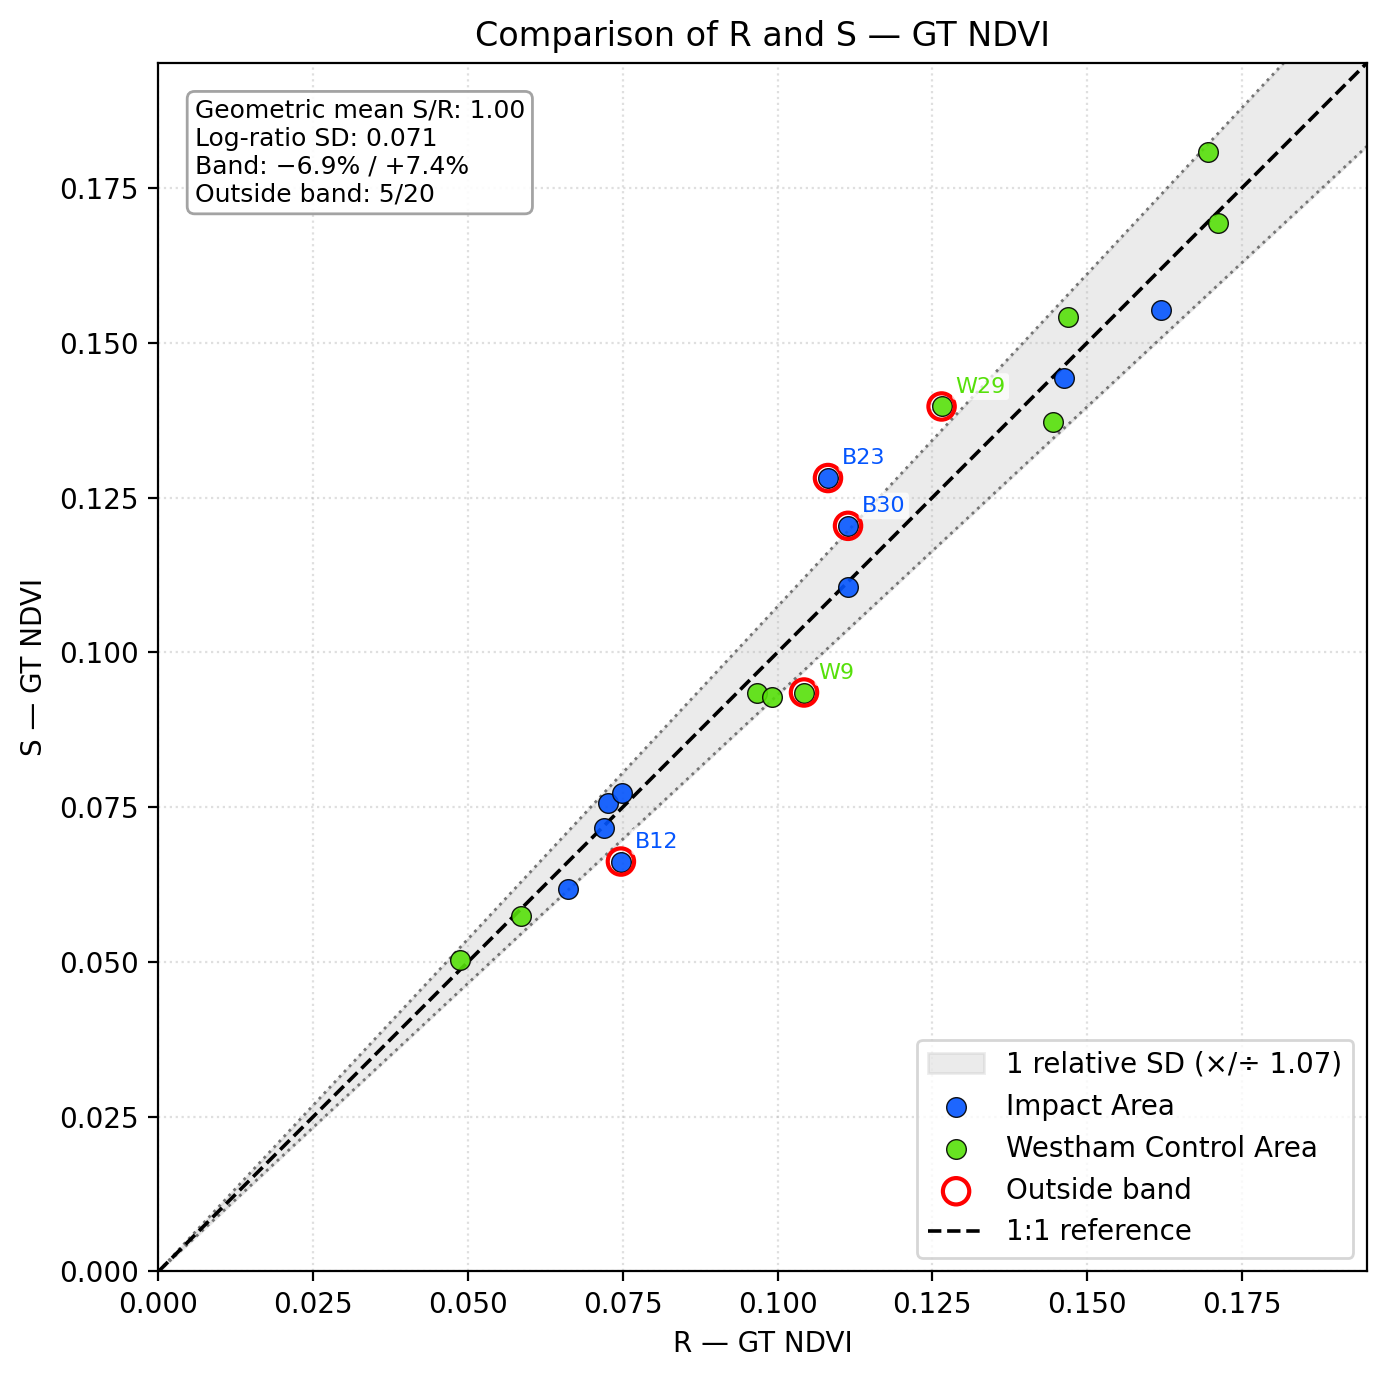

In [15]:
fig, ax, comparison = plot_r_vs_s_comparison(
    df_R=df_R_for_RplusS,
    df_S=df_S_for_RplusS,
    column=X_VARIABLE,
    site_colors=config.SITE_COLORS,
    site_labels=config.SITE_LABELS,
    band_type="relative",
    number_of_std=1,
    annotate="outside",
    column_label = 'GT NDVI',
)

plt.show()


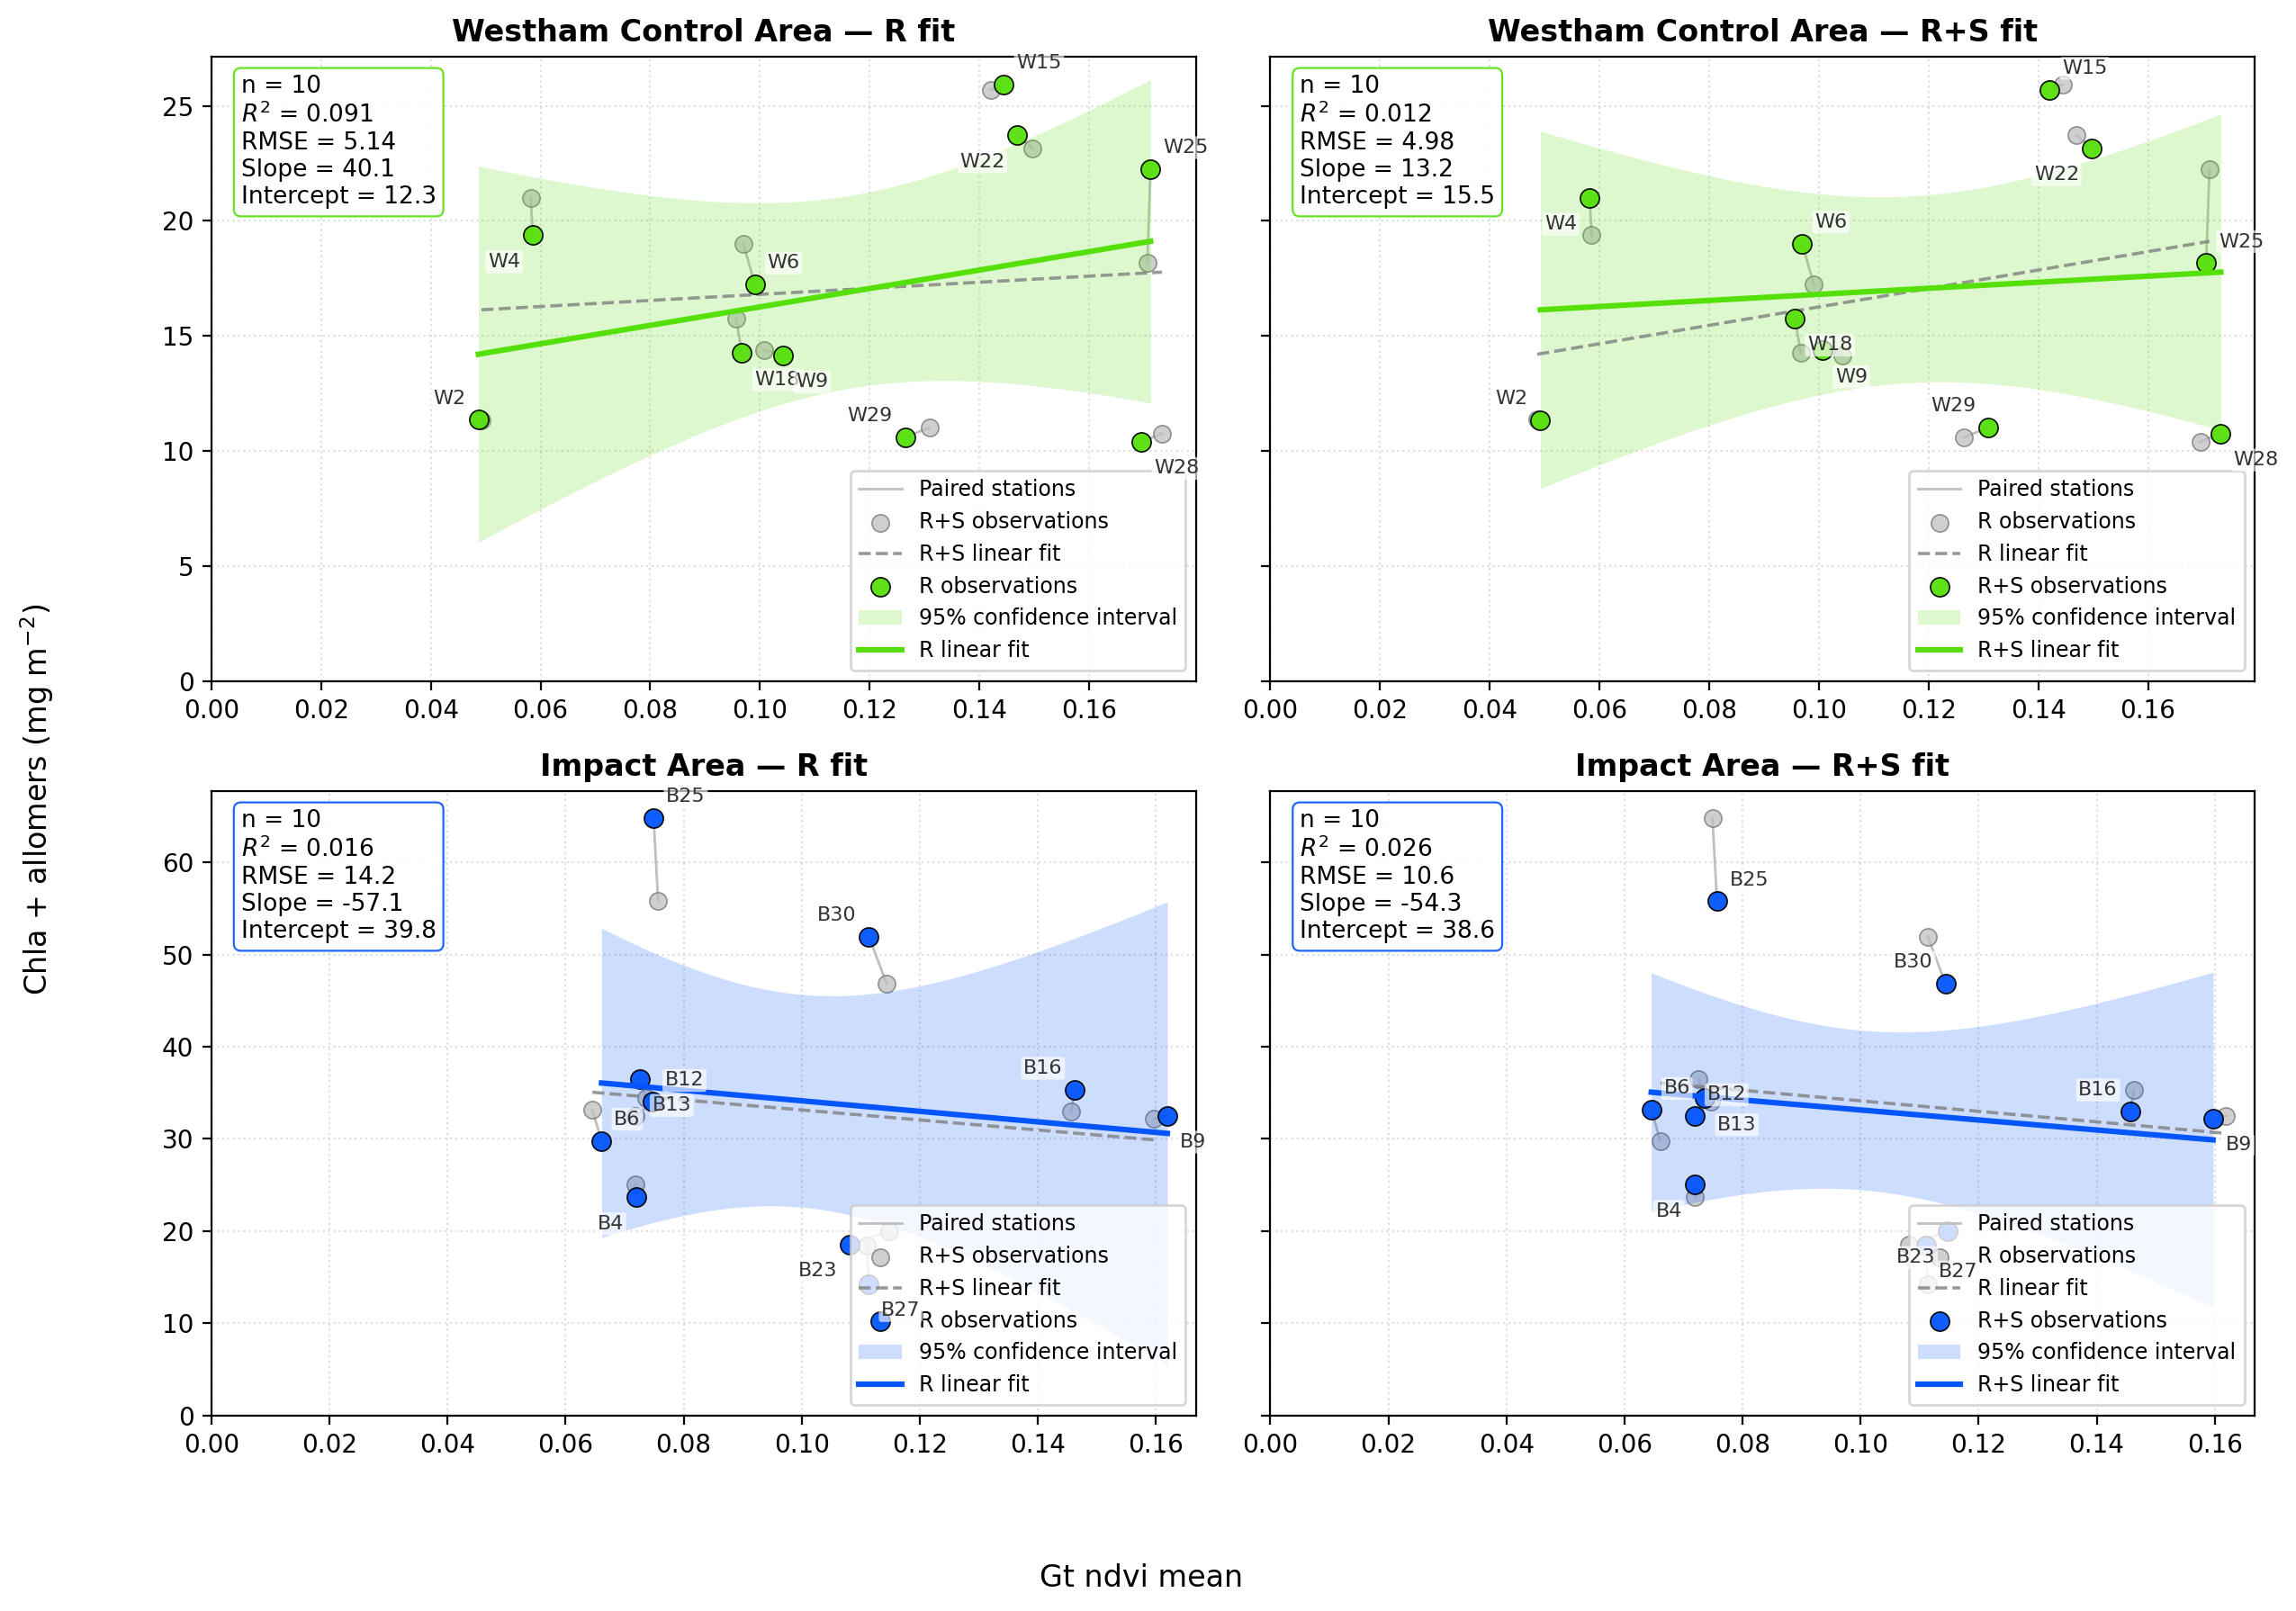

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t as student_t



# ==============================================================
# Configuration
# ==============================================================

y_col = "Chla + allomers (mg/m2)"

X_LABEL = X_VARIABLE.replace("_", " ").capitalize()
Y_LABEL = "Chla + allomers (mg m$^{-2}$)"

AREA_ORDER = [
    "westham",
    "brunswick",
]

FIT_CASES = [
    "R",
    "R+S",
]

CONFIDENCE_LEVEL = 0.95

ANNOTATE_STATIONS = True


# ==============================================================
# Helper functions
# ==============================================================


def prepare_case_data(dataframe, case_name):
    """Prepare x, y, and area columns for one sample case."""

    output = (
        dataframe[
            [
                X_VARIABLE,
                y_col,
            ]
        ]
        .reset_index()
        .rename(columns={"site": "area"})
        .copy()
    )

    output[X_VARIABLE] = pd.to_numeric(
        output[X_VARIABLE],
        errors="coerce",
    )

    output[y_col] = pd.to_numeric(
        output[y_col],
        errors="coerce",
    )

    output = output.dropna(
        subset=[
            "area",
            X_VARIABLE,
            y_col,
        ]
    )

    output["case"] = case_name

    return output


def fit_linear_regression_with_ci(
    x,
    y,
    *,
    confidence_level=0.95,
    number_of_grid_points=300,
):
    """
    Fit y = intercept + slope * x and calculate the confidence
    interval for the mean fitted response.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y)

    x = x[valid]
    y = y[valid]

    n = len(x)

    if n < 3:
        raise ValueError("At least three observations are required.")

    if np.unique(x).size < 2:
        raise ValueError("At least two distinct x values are required.")

    # Design matrix for y = intercept + slope * x
    design_matrix = np.column_stack(
        [
            np.ones(n),
            x,
        ]
    )

    coefficients, _, _, _ = np.linalg.lstsq(
        design_matrix,
        y,
        rcond=None,
    )

    intercept = coefficients[0]
    slope = coefficients[1]

    fitted_values = intercept + slope * x

    residuals = y - fitted_values

    residual_sum_squares = np.sum(residuals**2)

    total_sum_squares = np.sum((y - y.mean()) ** 2)

    r_squared = (
        1 - residual_sum_squares / total_sum_squares
        if total_sum_squares > 0
        else np.nan
    )

    rmse = np.sqrt(np.mean(residuals**2))

    degrees_of_freedom = n - 2

    residual_variance = residual_sum_squares / degrees_of_freedom

    covariance = residual_variance * np.linalg.inv(design_matrix.T @ design_matrix)

    x_grid = np.linspace(
        x.min(),
        x.max(),
        number_of_grid_points,
    )

    grid_design_matrix = np.column_stack(
        [
            np.ones(len(x_grid)),
            x_grid,
        ]
    )

    predicted = intercept + slope * x_grid

    prediction_variance = np.einsum(
        "ij,jk,ik->i",
        grid_design_matrix,
        covariance,
        grid_design_matrix,
    )

    prediction_standard_error = np.sqrt(
        np.maximum(
            prediction_variance,
            0,
        )
    )

    alpha = 1 - confidence_level

    critical_value = student_t.ppf(
        1 - alpha / 2,
        degrees_of_freedom,
    )

    confidence_lower = predicted - critical_value * prediction_standard_error

    confidence_upper = predicted + critical_value * prediction_standard_error

    return {
        "n": n,
        "slope": slope,
        "intercept": intercept,
        "r_squared": r_squared,
        "rmse": rmse,
        "x_grid": x_grid,
        "predicted": predicted,
        "confidence_lower": confidence_lower,
        "confidence_upper": confidence_upper,
    }


# ==============================================================
# Prepare R and R+S data
# ==============================================================

case_data = {
    "R": prepare_case_data(
        df_R_for_RplusS,
        "R",
    ),
    "R+S": prepare_case_data(
        df_RplusS_for_RplusS,
        "R+S",
    ),
}


# ==============================================================
# Create 2 × 2 figure
#
# Rows:    areas
# Columns: fitted sample cases
# ==============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13, 9),
    sharex="row",
    sharey="row",
)

for row_index, area in enumerate(AREA_ORDER):
    area_color = config.SITE_COLORS.get(
        area,
        "0.4",
    )

    area_label = config.SITE_LABELS.get(
        area,
        str(area),
    )

    for column_index, fit_case in enumerate(FIT_CASES):
        ax = axes[
            row_index,
            column_index,
        ]

        other_case = "R+S" if fit_case == "R" else "R"

        fit_subset = case_data[fit_case].loc[case_data[fit_case]["area"] == area]

        other_subset = case_data[other_case].loc[case_data[other_case]["area"] == area]

        # ----------------------------------------------------------
        # Connect corresponding stations between the two cases
        # ----------------------------------------------------------

        pair_columns = [
            column
            for column in [
                "area",
                "round",
                "station_id",
            ]
            if (column in fit_subset.columns and column in other_subset.columns)
        ]

        paired_data = fit_subset[
            pair_columns
            + [
                X_VARIABLE,
                y_col,
            ]
        ].merge(
            other_subset[
                pair_columns
                + [
                    X_VARIABLE,
                    y_col,
                ]
            ],
            on=pair_columns,
            how="inner",
            suffixes=(
                "_fit",
                "_other",
            ),
        )

        pair_label_added = False

        for _, pair in paired_data.iterrows():
            ax.plot(
                [
                    pair[f"{X_VARIABLE}_other"],
                    pair[f"{X_VARIABLE}_fit"],
                ],
                [
                    pair[f"{y_col}_other"],
                    pair[f"{y_col}_fit"],
                ],
                color="0.75",
                linestyle='-',
                linewidth=1,
                alpha=1,
                label=("Paired stations" if not pair_label_added else None),
                zorder=1,
            )

            pair_label_added = True

        # ----------------------------------------------------------
        # Other case observations in grey
        # ----------------------------------------------------------

        ax.scatter(
            other_subset[X_VARIABLE],
            other_subset[y_col],
            color="0.75",
            edgecolor="0.45",
            linewidth=0.6,
            s=48,
            alpha=0.75,
            label=f"{other_case} observations",
            zorder=2,
        )

        # ----------------------------------------------------------
        # Other case fit as a subtle solid grey line
        # ----------------------------------------------------------

        try:
            other_fit = fit_linear_regression_with_ci(
                other_subset[X_VARIABLE],
                other_subset[y_col],
                confidence_level=CONFIDENCE_LEVEL,
            )

        except ValueError:
            other_fit = None

        if other_fit is not None:
            ax.plot(
                other_fit["x_grid"],
                other_fit["predicted"],
                color="0.5",
                linestyle="--",
                linewidth=1.3,
                alpha=0.8,
                label=f"{other_case} linear fit",
                zorder=3,
            )

        # ----------------------------------------------------------
        # Current case observations in the area color
        # ----------------------------------------------------------

        ax.scatter(
            fit_subset[X_VARIABLE],
            fit_subset[y_col],
            color=area_color,
            edgecolor="black",
            linewidth=0.6,
            s=58,
            alpha=0.95,
            label=f"{fit_case} observations",
            zorder=4,
        )

        # ----------------------------------------------------------
        # Annotate the colored observations with station IDs
        # ----------------------------------------------------------

        if ANNOTATE_STATIONS:
            annotation_offsets = [
                (5, 5),
                (5, -7),
                (-5, 5),
                (-5, -7),
            ]

            for point_number, (_, point) in enumerate(fit_subset.iterrows()):
                x_offset, y_offset = annotation_offsets[
                    point_number % len(annotation_offsets)
                ]

                ax.annotate(
                    str(point["station_id"]),
                    xy=(
                        point[X_VARIABLE],
                        point[y_col],
                    ),
                    xytext=(
                        x_offset,
                        y_offset,
                    ),
                    textcoords="offset points",
                    ha=("left" if x_offset > 0 else "right"),
                    va=("bottom" if y_offset > 0 else "top"),
                    fontsize=8,
                    color="0.2",
                    bbox={
                        "boxstyle": "round,pad=0.12",
                        "facecolor": "white",
                        "edgecolor": "none",
                        "alpha": 0.65,
                    },
                    zorder=7,
                )

        # ----------------------------------------------------------
        # Current linear fit and 95% confidence interval
        # ----------------------------------------------------------

        try:
            fit_results = fit_linear_regression_with_ci(
                fit_subset[X_VARIABLE],
                fit_subset[y_col],
                confidence_level=CONFIDENCE_LEVEL,
            )

        except ValueError as error:
            ax.text(
                0.03,
                0.95,
                str(error),
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=10,
                color="red",
            )

        else:
            ax.fill_between(
                fit_results["x_grid"],
                fit_results["confidence_lower"],
                fit_results["confidence_upper"],
                color=area_color,
                alpha=0.2,
                linewidth=0,
                label="95% confidence interval",
                zorder=2,
            )

            ax.plot(
                fit_results["x_grid"],
                fit_results["predicted"],
                color=area_color,
                linestyle="-",
                linewidth=2.2,
                label=f"{fit_case} linear fit",
                zorder=5,
            )

            statistics_text = (
                f"n = {fit_results['n']}\n"
                f"$R^2$ = {fit_results['r_squared']:.3f}\n"
                f"RMSE = {fit_results['rmse']:.3g}\n"
                f"Slope = {fit_results['slope']:.3g}\n"
                f"Intercept = {fit_results['intercept']:.3g}"
            )

            ax.text(
                0.03,
                0.97,
                statistics_text,
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=9.5,
                bbox={
                    "boxstyle": "round,pad=0.3",
                    "facecolor": "white",
                    "edgecolor": area_color,
                    "linewidth": 0.8,
                    "alpha": 0.9,
                },
                zorder=6,
            )

        # ----------------------------------------------------------
        # Formatting
        # ----------------------------------------------------------

        ax.set_title(
            f"{area_label} — {fit_case} fit",
            fontsize=12,
            fontweight="bold",
        )

        ax.tick_params(
            axis="both",
            labelsize=10,
        )

        ax.tick_params(
            axis="x",
            labelbottom=True,
        )

        ax.grid(
            axis="both",
            linestyle=":",
            linewidth=0.8,
            alpha=0.4,
        )

        ax.legend(
            loc="lower right",
            frameon=True,
            fontsize=8.5,
        )

# ==============================================================
# Apply common limits within each area/row
# ==============================================================

for row_index in range(len(AREA_ORDER)):
    row_axes = axes[row_index, :]

    x_upper = max(ax.get_xlim()[1] for ax in row_axes)

    y_upper = max(ax.get_ylim()[1] for ax in row_axes)

    for ax in row_axes:
        ax.set_xlim(
            0,
            x_upper,
        )

        ax.set_ylim(
            0,
            y_upper,
        )

# Shared figure-level axis labels
fig.supxlabel(
    X_LABEL,
    fontsize=12,
)

fig.supylabel(
    Y_LABEL,
    fontsize=12,
)

fig.tight_layout(rect=(0.04, 0.04, 1, 1))

plt.show()

# EDA

## Correlations NDVI vs targeted variables

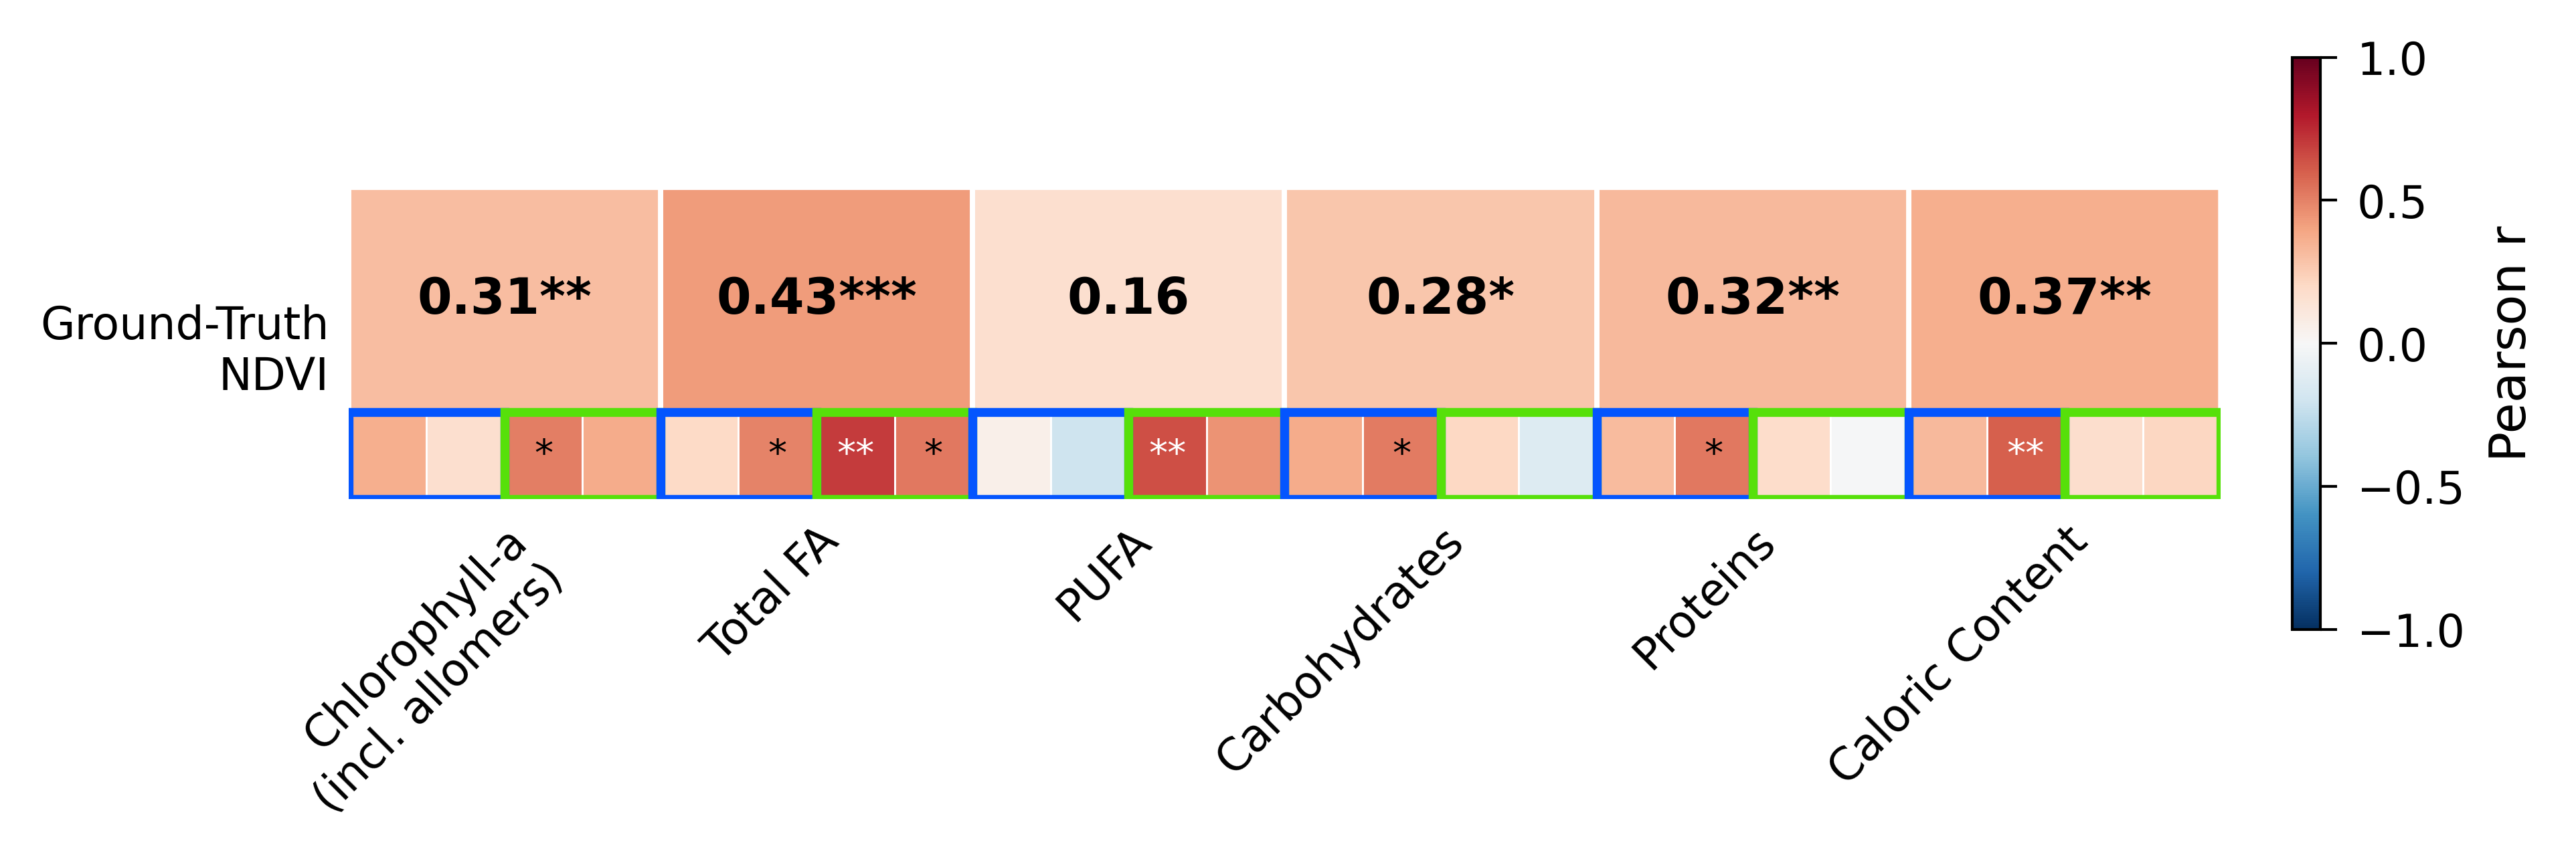

In [17]:
# VAR_TO_PREDICT_LABELS

fig, ax, correlation_df = external_correlation_heatmap(
    dataframe=df_all_R[combined_mask],

    # Variables displayed as rows
    columns_1=['gt_ndvi_mean'],
    # Variables displayed as columns
    columns_2=config.VAR_TO_PREDICT_LABELS.keys(),

    variable_labels_1={'gt_ndvi_mean': 'Ground-Truth\nNDVI'},

    variable_labels_2=config.VAR_TO_PREDICT_LABELS,

    area_order=[
        "brunswick",
        "westham",
    ],
    round_order=[
        1,
        2,
    ],
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    area_short_labels=config.SITE_SHORT_LABELS,

    method="pearson",
    test="analytic",
    pooled_inference="analytic",
    n_permutations=999,
    min_periods=10,
    p_adjust="fdr_bh",
    p_adjust_scope="global",

    annot=True,
    show_case_values=False,
    show_cell_key=False,
    area_outline_width=1.6,

    x_axis_label="",
    y_axis_label="",

    width_in=6.5,
    aspect_ratio=0.33,
    dpi=300,
    # output_path="outputs/external_correlation_heatmap.svg",

    title=None,
)

plt.show()

## Calibration curves

In [18]:

REPORT_STYLE = {
    "font.family": "DejaVu Sans",

    # General text
    "font.size": 9,

    # Axis text
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    # Legend
    "legend.fontsize": 8,
    "legend.title_fontsize": 8,

    # Axes and plotted elements
    "axes.linewidth": 0.5,
    "lines.linewidth": 1,
    "lines.markersize": 5,

    # Tick marks
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
}


In [19]:

# from collections.abc import Mapping, Sequence
# from pathlib import Path
# from typing import Any
# import warnings

# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# from matplotlib.lines import Line2D
# from scipy import stats

# try:
#     from adjustText import adjust_text
# except ImportError:  # Optional unless automatic annotation adjustment is used.
#     adjust_text = None



# def scatterplot_area_round_rows(
#     dataframe: pd.DataFrame,
#     x: Any,
#     y: Any,
#     *,
#     scope: str = "subset", # or full
#     site_level: str = "site",
#     round_level: str = "round",
#     station_level: str = "station_id",
#     area_order: Sequence[Any] = ("westham", "brunswick"),
#     round_order: Sequence[Any] = (1, 2),
#     area_colors: Mapping[Any, Any] | None = None,
#     area_labels: Mapping[Any, str] | None = None,
#     x_label: str | None = None,
#     y_label: str | None = None,
#     title: str | None = None,
#     comparison_scope: str = "site",
#     confidence_level: float = 0.95,
#     show_comparison_points: bool = True,
#     show_comparison_fit: bool = True,
#     show_comparison_ci: bool = True,
#     show_local_ci: bool = True,
#     show_statistics: bool = True,
#     annotate_stations: bool = False,
#     annotation_fontsize: float = 8,
#     adjust_text_kwargs: Mapping[str, Any] | None = None,
#     min_periods: int = 3,
#     point_size: float = 44,
#     point_alpha: float = 0.75,
#     comparison_point_size: float | None = None,
#     comparison_point_alpha: float = 0.5,
#     local_line_width: float = 2.0,
#     comparison_line_width: float = 1.8,
#     local_ci_alpha: float = 0.22,
#     comparison_ci_alpha: float = 0.22,
#     comparison_color: Any = "0.40",
#     comparison_line_style: str = "--",
#     extend_fits_to_xlim: bool = True,
#     xlim: Sequence[float] | None = None,
#     ylim: Sequence[float] | None = None,
#     share_y: bool = False,
#     x_padding_fraction: float = 0.05,
#     y_padding_fraction: float = 0.06,
#     grid: bool = True,
#     width_in: float = 6.5,
#     height_in: float | None = None,
#     subplot_height_in: float = 2.35,
#     legend_height_in: float = 0.55,
#     dpi: int = 300,
#     output_path: str | Path | None = None,
#     report_style: Mapping[str, Any] | None = None,
# ) -> tuple[plt.Figure, np.ndarray, pd.DataFrame]:
#     """
#     Plot one vertical subplot per area-round combination.

#     The ordering is area first and round second. For example, with two
#     areas and two rounds, the subplot order is:

#         Westham Round 1
#         Westham Round 2
#         Brunswick Round 1
#         Brunswick Round 2

#     When only one area is supplied, only its round panels are created.

#     Comparison scopes
#     -----------------
#     ``comparison_scope="all"``
#         All observations except those in the current area-round panel.

#     ``comparison_scope="round"``
#         Observations from the current round in other areas.

#     ``comparison_scope="site"``
#         Observations from the current area in other rounds. This is the
#         default.

#     All subplots share the same x-axis. Y-axes are independent by
#     default and can be shared with ``share_y=True``.

#     One common legend is placed at the top of the figure.

#     Returns
#     -------
#     fig, axes, fit_statistics
#         Figure, one-dimensional axes array, and local/comparison
#         regression statistics.
#     """

#     # ------------------------------------------------------------------
#     # Helpers
#     # ------------------------------------------------------------------

#     def display_column_name(column: Any) -> str:
#         return (
#             str(column[-1])
#             if isinstance(column, tuple)
#             else str(column)
#         )

#     def calculate_fit(
#         data: pd.DataFrame,
#         *,
#         scope: str,
#         label: str,
#         panel_area: Any,
#         panel_round: Any,
#         fit_xlim: tuple[float, float] | None,
#     ) -> tuple[dict[str, Any], dict[str, np.ndarray] | None]:
#         pair = data.loc[:, ["_x", "_y"]].copy()
#         pair = pair.apply(pd.to_numeric, errors="coerce").dropna()

#         n = len(pair)

#         result: dict[str, Any] = {
#             "scope": scope,
#             "comparison_scope": (
#                 comparison_scope
#                 if scope == "comparison"
#                 else None
#             ),
#             "area": panel_area,
#             "round": panel_round,
#             "label": label,
#             "n": n,
#             "slope": np.nan,
#             "intercept": np.nan,
#             "r": np.nan,
#             "r_squared": np.nan,
#             "p_value": np.nan,
#             "slope_standard_error": np.nan,
#             "rmse": np.nan,
#             "residual_standard_error": np.nan,
#             "confidence_level": confidence_level,
#             "observed_x_min": np.nan,
#             "observed_x_max": np.nan,
#             "fit_x_min": np.nan,
#             "fit_x_max": np.nan,
#         }

#         if (
#             n < min_periods
#             or pair["_x"].nunique() < 2
#             or pair["_y"].nunique() < 2
#         ):
#             return result, None

#         x_values = pair["_x"].to_numpy(dtype=float)
#         y_values = pair["_y"].to_numpy(dtype=float)

#         regression = stats.linregress(x_values, y_values)

#         slope = float(regression.slope)
#         intercept = float(regression.intercept)
#         r_value = float(regression.rvalue)
#         p_value = float(regression.pvalue)
#         slope_standard_error = float(regression.stderr)

#         fitted_observations = intercept + slope * x_values
#         residuals = y_values - fitted_observations

#         rmse = float(np.sqrt(np.mean(residuals**2)))

#         degrees_of_freedom = n - 2

#         residual_standard_error = (
#             float(
#                 np.sqrt(
#                     np.sum(residuals**2)
#                     / degrees_of_freedom
#                 )
#             )
#             if degrees_of_freedom > 0
#             else np.nan
#         )

#         observed_x_min = float(np.min(x_values))
#         observed_x_max = float(np.max(x_values))

#         if fit_xlim is None:
#             fit_x_min = observed_x_min
#             fit_x_max = observed_x_max
#         else:
#             fit_x_min, fit_x_max = map(float, fit_xlim)

#         x_grid = np.linspace(fit_x_min, fit_x_max, 250)
#         fitted_grid = intercept + slope * x_grid

#         x_mean = np.mean(x_values)
#         sxx = np.sum((x_values - x_mean) ** 2)

#         if (
#             degrees_of_freedom > 0
#             and sxx > 0
#             and np.isfinite(residual_standard_error)
#         ):
#             alpha = 1 - confidence_level

#             t_critical = stats.t.ppf(
#                 1 - alpha / 2,
#                 degrees_of_freedom,
#             )

#             mean_fit_standard_error = (
#                 residual_standard_error
#                 * np.sqrt(
#                     1 / n
#                     + (x_grid - x_mean) ** 2 / sxx
#                 )
#             )

#             ci_lower = (
#                 fitted_grid
#                 - t_critical * mean_fit_standard_error
#             )
#             ci_upper = (
#                 fitted_grid
#                 + t_critical * mean_fit_standard_error
#             )

#         else:
#             ci_lower = np.full_like(x_grid, np.nan)
#             ci_upper = np.full_like(x_grid, np.nan)

#         result.update(
#             {
#                 "slope": slope,
#                 "intercept": intercept,
#                 "r": r_value,
#                 "r_squared": r_value**2,
#                 "p_value": p_value,
#                 "slope_standard_error": slope_standard_error,
#                 "rmse": rmse,
#                 "residual_standard_error": residual_standard_error,
#                 "observed_x_min": observed_x_min,
#                 "observed_x_max": observed_x_max,
#                 "fit_x_min": fit_x_min,
#                 "fit_x_max": fit_x_max,
#             }
#         )

#         plot_values = {
#             "x_grid": x_grid,
#             "fitted": fitted_grid,
#             "ci_lower": ci_lower,
#             "ci_upper": ci_upper,
#         }

#         return result, plot_values

#     def compact_statistics_text(
#         local_result: Mapping[str, Any],
#         comparison_result: Mapping[str, Any],
#         local_label: str,
#         comparison_label: str,
#     ) -> str:
#         def format_p_value(value):
#             if not np.isfinite(value):
#                 return "p=NA"

#             if value < 0.001:
#                 return "p<0.001"

#             return f"p={value:.3f}"

#         def one_line(
#             label: str,
#             result: Mapping[str, Any],
#         ) -> str:
#             if not np.isfinite(result["r_squared"]):
#                 return (
#                     f"{label}: insufficient data "
#                     f"(n={result['n']})"
#                 )

#             return (
#                 f"{label}: "
#                 f"$R^2$={result['r_squared']:.3f}, "
#                 f"{format_p_value(result['p_value'])}, "
#                 f"RMSE={result['rmse']:.3g}"#, "
#                 # f"n={result['n']}"
#             )


#         return (
#             one_line(local_label, local_result)
#             + "\n"
#             + one_line(comparison_label, comparison_result)
#         )

#     # ------------------------------------------------------------------
#     # Validation
#     # ------------------------------------------------------------------

#     if not isinstance(dataframe, pd.DataFrame):
#         raise TypeError("dataframe must be a pandas DataFrame.")

#     if x not in dataframe.columns:
#         raise KeyError(f"x variable {x!r} was not found.")

#     if y not in dataframe.columns:
#         raise KeyError(f"y variable {y!r} was not found.")

#     if not isinstance(dataframe.index, pd.MultiIndex):
#         raise TypeError(
#             "dataframe.index must be a pandas MultiIndex."
#         )

#     required_levels = {
#         site_level,
#         round_level,
#         station_level,
#     }
#     missing_levels = required_levels - set(dataframe.index.names)

#     if missing_levels:
#         raise KeyError(
#             f"Missing index levels: {sorted(missing_levels)}"
#         )

#     valid_scopes = {"all", "round", "site"}

#     if comparison_scope not in valid_scopes:
#         raise ValueError(
#             "comparison_scope must be 'all', 'round', or 'site'."
#         )

#     if not 0 < confidence_level < 1:
#         raise ValueError(
#             "confidence_level must be between zero and one."
#         )

#     if min_periods < 3:
#         raise ValueError("min_periods must be at least three.")

#     if x_padding_fraction < 0 or y_padding_fraction < 0:
#         raise ValueError(
#             "Axis padding fractions cannot be negative."
#         )

#     if not 0 <= point_alpha <= 1:
#         raise ValueError(
#             "point_alpha must be between zero and one."
#         )

#     if not 0 <= comparison_point_alpha <= 1:
#         raise ValueError(
#             "comparison_point_alpha must be between zero and one."
#         )

#     width_in = float(width_in)
#     subplot_height_in = float(subplot_height_in)
#     legend_height_in = float(legend_height_in)

#     if width_in <= 0:
#         raise ValueError("width_in must be greater than zero.")

#     if subplot_height_in <= 0:
#         raise ValueError(
#             "subplot_height_in must be greater than zero."
#         )

#     if legend_height_in < 0:
#         raise ValueError(
#             "legend_height_in cannot be negative."
#         )

#     if not isinstance(dpi, int) or dpi <= 0:
#         raise ValueError("dpi must be a positive integer.")

#     if comparison_point_size is None:
#         comparison_point_size = 0.70 * point_size

#     if isinstance(area_order, (str, bytes)):
#         area_order = [area_order]
#     else:
#         area_order = list(area_order)

#     if isinstance(round_order, (str, bytes)):
#         round_order = [round_order]
#     else:
#         round_order = list(round_order)

#     if not area_order:
#         raise ValueError("At least one area must be provided.")

#     if not round_order:
#         raise ValueError("At least one round must be provided.")

#     available_areas = set(
#         dataframe.index.get_level_values(site_level)
#     )
#     available_rounds = set(
#         dataframe.index.get_level_values(round_level)
#     )

#     missing_areas = [
#         area for area in area_order if area not in available_areas
#     ]
#     missing_rounds = [
#         round_value
#         for round_value in round_order
#         if round_value not in available_rounds
#     ]

#     if missing_areas:
#         raise KeyError(f"Area(s) not found: {missing_areas}")

#     if missing_rounds:
#         raise KeyError(f"Round(s) not found: {missing_rounds}")

#     # ------------------------------------------------------------------
#     # Prepare pairwise-complete data
#     # ------------------------------------------------------------------

#     working = dataframe.loc[:, [x, y]].copy()

#     if f"Keep {y}" in dataframe.columns:
#         mask = dataframe[f'Keep {y}']
#         working = working[mask]

#     working.columns = ["_x", "_y"]
#     working = working.apply(pd.to_numeric, errors="coerce")

#     metadata = working.index.to_frame(index=False)

#     working = working.reset_index(drop=True)
#     working[site_level] = metadata[site_level].to_numpy()
#     working[round_level] = metadata[round_level].to_numpy()
#     working[station_level] = metadata[
#         station_level
#     ].astype(str).to_numpy()

#     valid_overall = working.dropna(subset=["_x", "_y"])

#     if valid_overall.empty:
#         raise ValueError(
#             "No pairwise-complete observations were found."
#         )

#     # Only create panels for observed requested combinations.
#     observed_cases = set(
#         valid_overall[
#             [site_level, round_level]
#         ].itertuples(index=False, name=None)
#     )

#     panel_cases = [
#         (area, round_value)
#         for area in area_order
#         for round_value in round_order
#         if (area, round_value) in observed_cases
#     ]

#     if not panel_cases:
#         raise ValueError(
#             "No requested area-round combinations contain valid data."
#         )

#     # ------------------------------------------------------------------
#     # Area colors, labels, and round markers
#     # ------------------------------------------------------------------

#     if area_colors is None:
#         palette = plt.get_cmap("tab10")
#         area_color_map = {
#             area: palette(index % 10)
#             for index, area in enumerate(area_order)
#         }
#     else:
#         area_color_map = dict(area_colors)

#     missing_area_colors = [
#         area for area in area_order if area not in area_color_map
#     ]

#     if missing_area_colors:
#         raise KeyError(
#             "No color was provided for area(s): "
#             f"{missing_area_colors}"
#         )

#     if area_labels is None:
#         area_label_map = {
#             area: str(area)
#             for area in area_order
#         }
#     else:
#         area_label_map = {
#             area: str(area_labels.get(area, area))
#             for area in area_order
#         }

#     available_markers = [
#         "o",
#         "s",
#         "^",
#         "D",
#         "P",
#         "v",
#         "X",
#         "<",
#         ">",
#     ]

#     round_markers = {
#         round_value: available_markers[
#             index % len(available_markers)
#         ]
#         for index, round_value in enumerate(round_order)
#     }

#     # ------------------------------------------------------------------
#     # Common x limits and optional shared y limits
#     # ------------------------------------------------------------------

#     if xlim is not None:
#         if len(xlim) != 2 or xlim[0] >= xlim[1]:
#             raise ValueError(
#                 "xlim must be an increasing two-element sequence."
#             )

#         display_xlim = tuple(map(float, xlim))

#     else:
#         overall_x_min = float(valid_overall["_x"].min())
#         overall_x_max = float(valid_overall["_x"].max())
#         x_range = overall_x_max - overall_x_min

#         x_padding = (
#             x_padding_fraction * x_range
#             if x_range > 0
#             else 1.0
#         )

#         display_xlim = (
#             overall_x_min - x_padding,
#             overall_x_max + x_padding,
#         )

#     fit_xlim = display_xlim if extend_fits_to_xlim else None

#     if ylim is not None:
#         if len(ylim) != 2 or ylim[0] >= ylim[1]:
#             raise ValueError(
#                 "ylim must be an increasing two-element sequence."
#             )

#         explicit_ylim = tuple(map(float, ylim))
#     else:
#         explicit_ylim = None

#     if share_y and explicit_ylim is None:
#         overall_y_min = float(valid_overall["_y"].min())
#         overall_y_max = float(valid_overall["_y"].max())
#         y_range = overall_y_max - overall_y_min

#         y_padding = (
#             y_padding_fraction * y_range
#             if y_range > 0
#             else 1.0
#         )

#         shared_ylim = (
#             overall_y_min - y_padding,
#             overall_y_max + y_padding,
#         )
#     else:
#         shared_ylim = explicit_ylim

#     # ------------------------------------------------------------------
#     # Comparison subset helpers
#     # ------------------------------------------------------------------

#     def comparison_base_mask(
#         area: Any,
#         round_value: Any,
#     ) -> pd.Series:
#         """Data used to calculate the combined grey fit."""

#         if comparison_scope == "all":
#             return pd.Series(True, index=working.index)

#         if comparison_scope == "round":
#             return working[round_level] == round_value

#         return working[site_level] == area

#     def comparison_point_mask(
#         area: Any,
#         round_value: Any,
#     ) -> pd.Series:
#         """Other observations shown as grey points."""

#         current_panel_mask = (
#             (working[site_level] == area)
#             & (working[round_level] == round_value)
#         )

#         return (
#             comparison_base_mask(area, round_value)
#             & ~current_panel_mask
#         )

#     def comparison_observation_label(
#         area: Any,
#         round_value: Any,
#     ) -> str:
#         if comparison_scope == "all":
#             return "Other observations"

#         if comparison_scope == "round":
#             return "Other area observations"

#         return "Other round observations"

#     def comparison_fit_label(
#         area: Any,
#         round_value: Any,
#     ) -> str:
#         if comparison_scope == "all":
#             return "All observations"

#         if comparison_scope == "round":
#             return (
#                 f"Round {round_value}, "
#                 "both areas"
#             )

#         # return (
#         #     f"{area_label_map[area]}, "
#         #     "both rounds fit"
#         # )
#         return (
#             "Both rounds"
#         )

#     def comparison_cache_key(
#         area: Any,
#         round_value: Any,
#     ) -> tuple[Any, ...]:
#         if comparison_scope == "all":
#             return ("all",)

#         if comparison_scope == "round":
#             return ("round", round_value)

#         return ("site", area)


#     # ------------------------------------------------------------------
#     # Figure setup
#     # ------------------------------------------------------------------

#     number_of_panels = len(panel_cases)

#     if height_in is None:
#         resolved_height_in = (
#             number_of_panels * subplot_height_in
#             + legend_height_in
#         )
#     else:
#         resolved_height_in = float(height_in)

#         if resolved_height_in <= 0:
#             raise ValueError(
#                 "height_in must be greater than zero."
#             )

#     effective_style = dict(REPORT_STYLE)

#     if report_style is not None:
#         effective_style.update(dict(report_style))

#     fit_records: list[dict[str, Any]] = []
#     comparison_fit_cache: dict[
#         tuple[Any, ...],
#         tuple[
#             dict[str, Any],
#             dict[str, np.ndarray] | None,
#             str,
#         ],
#     ] = {}
#     annotation_groups = []

#     with plt.rc_context(effective_style):
#         fig, axes = plt.subplots(
#             nrows=number_of_panels,
#             ncols=1,
#             figsize=(width_in, resolved_height_in),
#             dpi=dpi,
#             sharex=True,
#             sharey=share_y,
#             squeeze=False,
#         )

#         axes = axes[:, 0]

#         for panel_index, (
#             axis,
#             (area, round_value),
#         ) in enumerate(zip(axes, panel_cases)):
#             panel_mask = (
#                 (working[site_level] == area)
#                 & (working[round_level] == round_value)
#             )

#             panel_working = (
#                 working.loc[panel_mask]
#                 .dropna(subset=["_x", "_y"])
#             )

#             # Grey points include only the other observations.
#             comparison_points_working = (
#                 working.loc[
#                     comparison_point_mask(
#                         area,
#                         round_value,
#                     )
#                 ]
#                 .dropna(subset=["_x", "_y"])
#             )

#             local_label = (
#                 f"{area_label_map[area]}, Round {round_value}"
#             )

#             (
#                 local_result,
#                 local_plot_values,
#             ) = calculate_fit(
#                 panel_working,
#                 scope="area-round",
#                 label=local_label,
#                 panel_area=area,
#                 panel_round=round_value,
#                 fit_xlim=fit_xlim,
#             )

#             fit_records.append(local_result)

#             # The grey fit uses the complete selected scope, including
#             # the currently highlighted observations. Fits are cached so
#             # the same site-level fit appears in both round panels, the
#             # same round-level fit appears in both area panels, or one
#             # all-data fit appears everywhere.
#             cache_key = comparison_cache_key(
#                 area,
#                 round_value,
#             )

#             if cache_key not in comparison_fit_cache:
#                 comparison_fit_working = (
#                     working.loc[
#                         comparison_base_mask(
#                             area,
#                             round_value,
#                         )
#                     ]
#                     .dropna(subset=["_x", "_y"])
#                 )

#                 current_comparison_fit_label = (
#                     comparison_fit_label(
#                         area,
#                         round_value,
#                     )
#                 )

#                 (
#                     comparison_result,
#                     comparison_plot_values,
#                 ) = calculate_fit(
#                     comparison_fit_working,
#                     scope="comparison",
#                     label=current_comparison_fit_label,
#                     panel_area=(
#                         area
#                         if comparison_scope == "site"
#                         else None
#                     ),
#                     panel_round=(
#                         round_value
#                         if comparison_scope == "round"
#                         else None
#                     ),
#                     fit_xlim=fit_xlim,
#                 )

#                 comparison_fit_cache[cache_key] = (
#                     comparison_result,
#                     comparison_plot_values,
#                     current_comparison_fit_label,
#                 )

#                 fit_records.append(comparison_result)

#             (
#                 comparison_result,
#                 comparison_plot_values,
#                 current_comparison_fit_label,
#             ) = comparison_fit_cache[cache_key]

#             current_comparison_observation_label = (
#                 comparison_observation_label(
#                     area,
#                     round_value,
#                 )
#             )

#             color = area_color_map[area]

#             # ------------------------------------------------------
#             # Grey comparison observations
#             # ------------------------------------------------------

#             if show_comparison_points:
#                 for comparison_round in round_order:
#                     comparison_round_data = (
#                         comparison_points_working.loc[
#                             comparison_points_working[round_level]
#                             == comparison_round
#                         ]
#                     )

#                     if comparison_round_data.empty:
#                         continue

#                     axis.scatter(
#                         comparison_round_data["_x"],
#                         comparison_round_data["_y"],
#                         s=comparison_point_size,
#                         alpha=comparison_point_alpha,
#                         color=comparison_color,
#                         marker=round_markers[comparison_round],
#                         edgecolor="none",
#                         linewidth=0,
#                         zorder=0,
#                     )

#             # ------------------------------------------------------
#             # Grey comparison fit and interval
#             # ------------------------------------------------------

#             if comparison_plot_values is not None:
#                 if show_comparison_fit and show_comparison_ci:
#                     axis.fill_between(
#                         comparison_plot_values["x_grid"],
#                         comparison_plot_values["ci_lower"],
#                         comparison_plot_values["ci_upper"],
#                         color=comparison_color,
#                         alpha=comparison_ci_alpha,
#                         linewidth=0,
#                         zorder=1,
#                     )

#                 if show_comparison_fit:
#                     axis.plot(
#                         comparison_plot_values["x_grid"],
#                         comparison_plot_values["fitted"],
#                         color=comparison_color,
#                         linestyle=comparison_line_style,
#                         linewidth=comparison_line_width,
#                         zorder=2,
#                     )

#             # ------------------------------------------------------
#             # Highlighted local observations and fit
#             # ------------------------------------------------------

#             axis.scatter(
#                 panel_working["_x"],
#                 panel_working["_y"],
#                 s=point_size,
#                 alpha=point_alpha,
#                 color=color,
#                 marker=round_markers[round_value],
#                 edgecolor="black",
#                 linewidth=0.5,
#                 zorder=4,
#             )

#             if local_plot_values is not None:
#                 if show_local_ci:
#                     axis.fill_between(
#                         local_plot_values["x_grid"],
#                         local_plot_values["ci_lower"],
#                         local_plot_values["ci_upper"],
#                         color=color,
#                         alpha=local_ci_alpha,
#                         linewidth=0,
#                         zorder=3,
#                     )

#                 axis.plot(
#                     local_plot_values["x_grid"],
#                     local_plot_values["fitted"],
#                     color=color,
#                     linestyle="-",
#                     linewidth=local_line_width,
#                     zorder=5,
#                 )

#             # ------------------------------------------------------
#             # Optional station annotations
#             # ------------------------------------------------------

#             panel_texts = []
#             panel_x = []
#             panel_y = []

#             if annotate_stations:
#                 for _, point in panel_working.iterrows():
#                     text = axis.text(
#                         point["_x"],
#                         point["_y"],
#                         str(point[station_level]),
#                         ha="center",
#                         va="bottom",
#                         fontsize=annotation_fontsize,
#                         color="0.2",
#                         zorder=7,
#                     )

#                     panel_texts.append(text)
#                     panel_x.append(float(point["_x"]))
#                     panel_y.append(float(point["_y"]))

#             annotation_groups.append(
#                 {
#                     "axis": axis,
#                     "texts": panel_texts,
#                     "x": panel_x,
#                     "y": panel_y,
#                 }
#             )

#             # ------------------------------------------------------
#             # Optional statistics box
#             # ------------------------------------------------------

#             if show_statistics:
#                 statistics_text = compact_statistics_text(
#                     local_result,
#                     comparison_result,
#                     f"Round {round_value}",
#                     current_comparison_fit_label,
#                 )

#                 axis.text(
#                     0.03,
#                     0.97,
#                     statistics_text,
#                     transform=axis.transAxes,
#                     ha="left",
#                     va="top",
#                     fontsize=8,
#                     bbox={
#                         "boxstyle": "round,pad=0.25",
#                         "facecolor": "white",
#                         "edgecolor": "none",
#                         "linewidth": 0,
#                         "alpha": 0.90,
#                     },
#                     zorder=8,
#                 )

#             # ------------------------------------------------------
#             # Panel formatting
#             # ------------------------------------------------------

#             axis.set_title(
#                 local_label,
#                 # fontweight="bold",
#                 pad=3,
#             )

#             axis.set_xlim(display_xlim)

#             if shared_ylim is not None:
#                 axis.set_ylim(shared_ylim)

#             elif explicit_ylim is not None:
#                 axis.set_ylim(explicit_ylim)

#             else:
#                 panel_y_values = pd.concat(
#                     [
#                         panel_working["_y"],
#                         comparison_points_working["_y"],
#                     ],
#                     ignore_index=True,
#                 ).dropna()

#                 if not panel_y_values.empty:
#                     panel_y_min = float(panel_y_values.min())
#                     panel_y_max = float(panel_y_values.max())
#                     panel_y_range = panel_y_max - panel_y_min

#                     panel_y_padding = (
#                         y_padding_fraction * panel_y_range
#                         if panel_y_range > 0
#                         else 1.0
#                     )

#                     axis.set_ylim(
#                         panel_y_min - panel_y_padding,
#                         panel_y_max + panel_y_padding,
#                     )

#             if grid:
#                 axis.grid(
#                     visible=True,
#                     axis="both",
#                     linestyle=":",
#                     linewidth=0.7,
#                     color="0.72",
#                     alpha=0.6,
#                 )
#                 axis.set_axisbelow(True)

#             # Only the bottom panel displays x tick labels.
#             axis.tick_params(
#                 axis="x",
#                 labelbottom=(
#                     panel_index
#                     == number_of_panels - 1
#                 ),
#             )

#         # ------------------------------------------------------------------
#         # One common figure-level legend
#         # ------------------------------------------------------------------

#         legend_handles = []

#         for area, round_value in panel_cases:
#             color = area_color_map[area]

#             legend_handles.append(
#                 Line2D(
#                     [0],
#                     [0],
#                     color=color,
#                     marker=round_markers[round_value],
#                     markerfacecolor=color,
#                     markeredgecolor="black",
#                     markeredgewidth=0.5,
#                     linestyle="-",
#                     linewidth=local_line_width,
#                     markersize=7,
#                     label=(
#                         f"{area_label_map[area]} — "
#                         f"Round {round_value}"
#                     ),
#                 )
#             )

#         if show_comparison_points:
#             if comparison_scope == "site":
#                 grey_point_label = "Other round observations"
#             elif comparison_scope == "round":
#                 grey_point_label = "Other area observations"
#             else:
#                 grey_point_label = "Other observations"

#             legend_handles.append(
#                 Line2D(
#                     [0],
#                     [0],
#                     color=comparison_color,
#                     marker="o",
#                     markerfacecolor=comparison_color,
#                     markeredgecolor="none",
#                     linestyle="None",
#                     markersize=6,
#                     alpha=comparison_point_alpha,
#                     label=grey_point_label,
#                 )
#             )

#         if show_comparison_fit:
#             # Add one grey fit entry for each unique cached fit.
#             for (
#                 comparison_result,
#                 comparison_plot_values,
#                 comparison_label_text,
#             ) in comparison_fit_cache.values():
#                 if comparison_plot_values is None:
#                     continue

#                 legend_handles.append(
#                     Line2D(
#                         [0],
#                         [0],
#                         color=comparison_color,
#                         linestyle=comparison_line_style,
#                         linewidth=comparison_line_width,
#                         label=comparison_label_text,
#                     )
#                 )

#         # Remove duplicate handles while preserving order.
#         unique_legend_handles = {}

#         for handle in legend_handles:
#             label = handle.get_label()

#             if label not in unique_legend_handles:
#                 unique_legend_handles[label] = handle

#         fig.legend(
#             handles=list(unique_legend_handles.values()),
#             labels=list(unique_legend_handles.keys()),
#             loc="upper center",
#             bbox_to_anchor=(0.5, 0.985),
#             ncol=min(
#                 2,
#                 len(unique_legend_handles),
#             ),
#             frameon=True,
#             framealpha=0.95,
#             borderpad=0.35,
#             labelspacing=0.35,
#             handlelength=1.8,
#             handletextpad=0.5,
#             columnspacing=1.0,
#         )


#         if x_label is None:
#             x_label = display_column_name(x)

#         if y_label is None:
#             y_label = display_column_name(y)

#         if title is not None:
#             fig.suptitle(
#                 title,
#                 fontweight="bold",
#                 y=0.998,
#             )

#         fig.supxlabel(x_label, y=0.05)
#         fig.supylabel(y_label, x=0.05)

#         # Reserve room for the common legend and optional title.
#         top_limit = 0.935 if title is None else 0.905

#         fig.tight_layout(
#             rect=(0.035, 0.035, 1, top_limit)
#         )

#         fig.canvas.draw()

#         # ------------------------------------------------------------------
#         # Adjust station annotations after final layout
#         # ------------------------------------------------------------------

#         if annotate_stations and adjust_text is None:
#             warnings.warn(
#                 "adjustText is not installed; station labels were "
#                 "drawn but could not be automatically repositioned.",
#                 RuntimeWarning,
#                 stacklevel=2,
#             )

#         if annotate_stations and adjust_text is not None:
#             default_adjust_text_kwargs: dict[str, Any] = {
#                 "expand": (1.15, 1.25),
#                 "force_text": (0.2, 0.3),
#                 "force_static": (0.1, 0.2),
#                 "force_pull": (0.01, 0.02),
#                 "force_explode": (0.1, 0.3),
#                 "max_move": (8, 18),
#                 "ensure_inside_axes": True,
#                 "prevent_crossings": True,
#                 "min_arrow_len": 4,
#                 "arrowprops": {
#                     "arrowstyle": "-",
#                     "color": "0.35",
#                     "linewidth": 0.6,
#                     "alpha": 0.75,
#                 },
#             }

#             if adjust_text_kwargs is not None:
#                 default_adjust_text_kwargs.update(
#                     dict(adjust_text_kwargs)
#                 )

#             for annotation_group in annotation_groups:
#                 if not annotation_group["texts"]:
#                     continue

#                 adjust_text(
#                     annotation_group["texts"],
#                     x=annotation_group["x"],
#                     y=annotation_group["y"],
#                     target_x=annotation_group["x"],
#                     target_y=annotation_group["y"],
#                     ax=annotation_group["axis"],
#                     **default_adjust_text_kwargs,
#                 )

#             fig.canvas.draw()

#         # Save after all annotation positions are final.
#         if output_path is not None:
#             resolved_output_path = Path(output_path)

#             if resolved_output_path.suffix == "":
#                 resolved_output_path = (
#                     resolved_output_path.with_suffix(".png")
#                 )

#             resolved_output_path.parent.mkdir(
#                 parents=True,
#                 exist_ok=True,
#             )

#             fig.savefig(
#                 resolved_output_path,
#                 dpi=dpi,
#                 facecolor="white",
#             )

#     fit_statistics = pd.DataFrame.from_records(fit_records)

#     fit_statistics = fit_statistics[
#         [
#             "scope",
#             "comparison_scope",
#             "area",
#             "round",
#             "label",
#             "n",
#             "slope",
#             "intercept",
#             "r",
#             "r_squared",
#             "p_value",
#             "slope_standard_error",
#             "rmse",
#             "residual_standard_error",
#             "confidence_level",
#             "observed_x_min",
#             "observed_x_max",
#             "fit_x_min",
#             "fit_x_max",
#         ]
#     ]

#     return fig, axes, fit_statistics


In [20]:
"""Two-area, two-round, and combined-round regression grid."""

from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from matplotlib.ticker import MultipleLocator
try:
    from adjustText import adjust_text
except ImportError:  # Optional unless annotation adjustment is requested.
    adjust_text = None



# REPORT_STYLE: dict[str, Any] = {
#     "font.family": "DejaVu Sans",
#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "axes.titleweight": "bold",
#     "figure.labelsize": 10,
#     "figure.labelweight": "normal",
#     "figure.titlesize": 11,
#     "figure.titleweight": "bold",
#     "xtick.labelsize": 8,
#     "ytick.labelsize": 8,
#     "legend.fontsize": 9,
#     "legend.title_fontsize": 9,
#     "axes.linewidth": 0.8,
#     "lines.linewidth": 1.3,
#     "lines.markersize": 5,
#     "xtick.major.width": 0.8,
#     "ytick.major.width": 0.8,
#     "xtick.major.size": 3,
#     "ytick.major.size": 3,
# }

fs = 7
REPORT_STYLE = {
    "font.family": "DejaVu Sans",
    # General text
    "font.size": fs,
    # Axis text
    "axes.labelsize": fs,
    "xtick.labelsize": fs - 1,
    "ytick.labelsize": fs - 1,
    # Legend
    "legend.fontsize": fs - 1,
    "legend.title_fontsize": fs - 1,
    # Axes and plotted elements
    "axes.linewidth": 0.5,
    "lines.linewidth": 1,
    "lines.markersize": 5,
    # Tick marks
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
}


def scatterplot_area_round_combined_grid(
    dataframe: pd.DataFrame,
    x: Any,
    y: Any,
    *,
    site_level: str = "site",
    round_level: str = "round",
    station_level: str = "station_id",
    area_order: Sequence[Any] = ("brunswick", "westham"),
    round_order: Sequence[Any] = (1, 2),
    area_colors: Mapping[Any, Any] | None = None,
    area_labels: Mapping[Any, str] | None = None,
    x_label: str | None = None,
    y_label: str | None = None,
    title: str | None = None,
    keep_column: Any | None = None,
    confidence_level: float = 0.95,
    min_periods: int = 3,
    point_size: float = 30,
    point_alpha: float = 0.80,
    fit_line_width: float = 2.0,
    fit_color: Any = "black",
    ci_color: Any | None = None,
    ci_line_width: float = 1.1,
    ci_line_alpha: float = 0.75,
    ci_line_style: str = "--",
    annotate_stations: bool = False,
    annotation_fontsize: float = 8,
    annotation_include_round_in_combined: bool = True,
    adjust_text_kwargs: Mapping[str, Any] | None = None,
    extend_fits_to_xlim: bool = True,
    x_limits: Sequence[float] | None = None,
    y_limits: Sequence[float] | Mapping[Any, Sequence[float]] | None = None,
    share_y_across_areas: bool = False,
    x_padding_fraction: float = 0.05,
    y_padding_fraction: float = 0.06,
    grid: bool = True,
    show_legend: bool = True,
    use_common_y_label: bool = False,
    show_area_row_labels: bool = True,
    width_in: float = 6.5,
    height_in: float | None = None,
    aspect_ratio: float = 0.72,
    dpi: int = 300,
    output_path: str | Path | None = None,
    report_style: Mapping[str, Any] | None = None,
    legend_ncols: int | None = None,
) -> tuple[plt.Figure, np.ndarray, pd.DataFrame]:
    """
    Plot Round 1, Round 2, and combined-round fits for each area.

    The layout is two rows by three columns by default:

    =================  ==============  ==============  ==================
    Area               Round 1         Round 2         Rounds 1 + 2
    =================  ==============  ==============  ==================
    Brunswick          local fit       local fit       combined fit
    Westham             local fit       local fit       combined fit
    =================  ==============  ==============  ==================

    In the combined column, observations retain their original round
    markers so round-level differences remain visible.

    Every subplot contains:

    * area-colored observations;
    * one solid least-squares fit;
    * dashed lower and upper confidence-boundary curves.

    All subplots share one global x-axis range. Y-axis ranges are
    shared within each area row, but may differ between areas.

    No statistics are written on the figure. Complete fit statistics
    are returned as a DataFrame.

    Parameters
    ----------
    dataframe
        DataFrame indexed by area, round, and station.

    x, y
        Columns used as predictor and response variables.

    area_order
        Area row order. The default is Brunswick followed by Westham.

    round_order
        Exactly two rounds, displayed in the first two columns.

    keep_column
        Optional boolean column used to filter observations before
        plotting and fitting.

    x_limits
        Optional global two-element x-axis limits applied to every
        subplot.

    y_limits
        Optional y-axis limits. Supply either one two-element sequence
        for all rows or a mapping from area identifier to limits.

    show_legend
        Display the common figure-level legend.

    use_common_y_label
        Display the resolved y-variable label once along the left side
        of the complete figure using ``fig.supylabel``.

    show_area_row_labels
        Display the area name on the y-axis of the first subplot in
        each row.

    Returns
    -------
    fig, axes, fit_statistics
        Figure, 2D axes array, and one statistics row per subplot.
    """

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------

    def display_column_name(column: Any) -> str:
        return (
            str(column[-1])
            if isinstance(column, tuple)
            else str(column)
        )

    def resolve_area_limits(
        limits: Sequence[float] | Mapping[Any, Sequence[float]] | None,
        area: Any,
        argument_name: str,
    ) -> tuple[float, float] | None:
        if limits is None:
            return None

        if isinstance(limits, Mapping):
            area_limits = limits.get(area)

            if area_limits is None:
                return None
        else:
            area_limits = limits

        if (
            len(area_limits) != 2
            or area_limits[0] >= area_limits[1]
        ):
            raise ValueError(
                f"{argument_name} for area {area!r} must be an "
                "increasing two-element sequence."
            )

        return tuple(map(float, area_limits))

    def calculate_fit(
        data: pd.DataFrame,
        *,
        area: Any,
        panel_type: str,
        round_value: Any,
        fit_xlim: tuple[float, float] | None,
    ) -> tuple[dict[str, Any], dict[str, np.ndarray] | None]:
        pair = data.loc[:, ["_x", "_y"]].copy()
        pair = pair.apply(pd.to_numeric, errors="coerce").dropna()

        n = len(pair)

        result: dict[str, Any] = {
            "area": area,
            "panel_type": panel_type,
            "round": round_value,
            "n": n,
            "slope": np.nan,
            "intercept": np.nan,
            "r": np.nan,
            "r_squared": np.nan,
            "p_value": np.nan,
            "slope_standard_error": np.nan,
            "rmse": np.nan,
            "residual_standard_error": np.nan,
            "confidence_level": confidence_level,
            "observed_x_min": np.nan,
            "observed_x_max": np.nan,
            "fit_x_min": np.nan,
            "fit_x_max": np.nan,
        }

        if (
            n < min_periods
            or pair["_x"].nunique() < 2
            or pair["_y"].nunique() < 2
        ):
            return result, None

        x_values = pair["_x"].to_numpy(dtype=float)
        y_values = pair["_y"].to_numpy(dtype=float)

        regression = stats.linregress(x_values, y_values)

        slope = float(regression.slope)
        intercept = float(regression.intercept)
        r_value = float(regression.rvalue)
        p_value = float(regression.pvalue)
        slope_standard_error = float(regression.stderr)

        fitted_observations = intercept + slope * x_values
        residuals = y_values - fitted_observations

        rmse = float(np.sqrt(np.mean(residuals**2)))
        degrees_of_freedom = n - 2

        residual_standard_error = (
            float(
                np.sqrt(
                    np.sum(residuals**2)
                    / degrees_of_freedom
                )
            )
            if degrees_of_freedom > 0
            else np.nan
        )

        observed_x_min = float(np.min(x_values))
        observed_x_max = float(np.max(x_values))

        if fit_xlim is None:
            fit_x_min = observed_x_min
            fit_x_max = observed_x_max
        else:
            fit_x_min, fit_x_max = map(float, fit_xlim)

        x_grid = np.linspace(fit_x_min, fit_x_max, 250)
        fitted_grid = intercept + slope * x_grid

        x_mean = np.mean(x_values)
        sxx = np.sum((x_values - x_mean) ** 2)

        if (
            degrees_of_freedom > 0
            and sxx > 0
            and np.isfinite(residual_standard_error)
        ):
            alpha = 1 - confidence_level

            t_critical = stats.t.ppf(
                1 - alpha / 2,
                degrees_of_freedom,
            )

            mean_fit_standard_error = (
                residual_standard_error
                * np.sqrt(
                    1 / n
                    + (x_grid - x_mean) ** 2 / sxx
                )
            )

            ci_lower = (
                fitted_grid
                - t_critical * mean_fit_standard_error
            )
            ci_upper = (
                fitted_grid
                + t_critical * mean_fit_standard_error
            )

        else:
            ci_lower = np.full_like(x_grid, np.nan)
            ci_upper = np.full_like(x_grid, np.nan)

        result.update(
            {
                "slope": slope,
                "intercept": intercept,
                "r": r_value,
                "r_squared": r_value**2,
                "p_value": p_value,
                "slope_standard_error": slope_standard_error,
                "rmse": rmse,
                "residual_standard_error": residual_standard_error,
                "observed_x_min": observed_x_min,
                "observed_x_max": observed_x_max,
                "fit_x_min": fit_x_min,
                "fit_x_max": fit_x_max,
            }
        )

        plot_values = {
            "x_grid": x_grid,
            "fitted": fitted_grid,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
        }

        return result, plot_values

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError("dataframe must be a pandas DataFrame.")

    if x not in dataframe.columns:
        raise KeyError(f"x variable {x!r} was not found.")

    if y not in dataframe.columns:
        raise KeyError(f"y variable {y!r} was not found.")

    if keep_column is not None and keep_column not in dataframe.columns:
        raise KeyError(
            f"keep_column {keep_column!r} was not found."
        )

    if not isinstance(dataframe.index, pd.MultiIndex):
        raise TypeError(
            "dataframe.index must be a pandas MultiIndex."
        )

    required_levels = {
        site_level,
        round_level,
        station_level,
    }
    missing_levels = required_levels - set(dataframe.index.names)

    if missing_levels:
        raise KeyError(
            f"Missing index levels: {sorted(missing_levels)}"
        )

    if isinstance(area_order, (str, bytes)):
        area_order = [area_order]
    else:
        area_order = list(area_order)

    if isinstance(round_order, (str, bytes)):
        round_order = [round_order]
    else:
        round_order = list(round_order)

    if not area_order:
        raise ValueError("At least one area must be provided.")

    if len(round_order) != 2:
        raise ValueError(
            "round_order must contain exactly two rounds."
        )

    if not 0 < confidence_level < 1:
        raise ValueError(
            "confidence_level must be between zero and one."
        )

    if min_periods < 3:
        raise ValueError("min_periods must be at least three.")

    if x_padding_fraction < 0 or y_padding_fraction < 0:
        raise ValueError(
            "Axis padding fractions cannot be negative."
        )

    if not 0 <= point_alpha <= 1:
        raise ValueError(
            "point_alpha must be between zero and one."
        )

    if ci_color is None:
        ci_color = fit_color

    width_in = float(width_in)
    aspect_ratio = float(aspect_ratio)

    if width_in <= 0:
        raise ValueError("width_in must be greater than zero.")

    if aspect_ratio <= 0:
        raise ValueError(
            "aspect_ratio must be greater than zero."
        )

    if not isinstance(dpi, int) or dpi <= 0:
        raise ValueError("dpi must be a positive integer.")

    available_areas = set(
        dataframe.index.get_level_values(site_level)
    )
    available_rounds = set(
        dataframe.index.get_level_values(round_level)
    )

    missing_areas = [
        area for area in area_order if area not in available_areas
    ]
    missing_rounds = [
        round_value
        for round_value in round_order
        if round_value not in available_rounds
    ]

    if missing_areas:
        raise KeyError(f"Area(s) not found: {missing_areas}")

    if missing_rounds:
        raise KeyError(f"Round(s) not found: {missing_rounds}")

    # ------------------------------------------------------------------
    # Prepare pairwise-complete data
    # ------------------------------------------------------------------

    selected_columns = [x, y]

    if keep_column is not None:
        selected_columns.append(keep_column)

    working = dataframe.loc[:, selected_columns].copy()

    if keep_column is not None:
        keep_mask = (
            working[keep_column]
            .fillna(False)
            .astype(bool)
        )
        working = working.loc[keep_mask]

    working = working.loc[:, [x, y]]
    working.columns = ["_x", "_y"]
    working = working.apply(pd.to_numeric, errors="coerce")

    metadata = working.index.to_frame(index=False)

    working = working.reset_index(drop=True)
    working[site_level] = metadata[site_level].to_numpy()
    working[round_level] = metadata[round_level].to_numpy()
    working[station_level] = metadata[
        station_level
    ].astype(str).to_numpy()

    valid_overall = working.dropna(subset=["_x", "_y"])

    if valid_overall.empty:
        raise ValueError(
            "No pairwise-complete observations were found."
        )

    # --------------------------------------------------------------
    # Optional global y-axis range
    # --------------------------------------------------------------

    global_y_limits = None

    if share_y_across_areas:
        if y_limits is not None:
            if isinstance(y_limits, Mapping):
                raise ValueError(
                    "When share_y_across_areas=True, y_limits must "
                    "be one common two-element sequence, not a mapping."
                )

            if len(y_limits) != 2 or y_limits[0] >= y_limits[1]:
                raise ValueError("y_limits must be an increasing two-element sequence.")

            global_y_limits = tuple(map(float, y_limits))

        else:
            global_y_min = float(valid_overall["_y"].min())

            global_y_max = float(valid_overall["_y"].max())

            global_y_range = global_y_max - global_y_min

            global_y_padding = (
                y_padding_fraction * global_y_range if global_y_range > 0 else 1.0
            )

            global_y_limits = (
                global_y_min - global_y_padding,
                global_y_max + global_y_padding,
            )

    # ------------------------------------------------------------------
    # One global x-axis range for every subplot
    # ------------------------------------------------------------------

    if x_limits is not None:
        if len(x_limits) != 2 or x_limits[0] >= x_limits[1]:
            raise ValueError(
                "x_limits must be an increasing two-element sequence."
            )

        global_x_limits = tuple(map(float, x_limits))

    else:
        global_x_min = float(valid_overall["_x"].min())
        global_x_max = float(valid_overall["_x"].max())
        global_x_range = global_x_max - global_x_min

        global_x_padding = (
            x_padding_fraction * global_x_range
            if global_x_range > 0
            else 1.0
        )

        global_x_limits = (
            global_x_min - global_x_padding,
            global_x_max + global_x_padding,
        )

    global_fit_xlim = (
        global_x_limits
        if extend_fits_to_xlim
        else None
    )

    # ------------------------------------------------------------------
    # Area colors, labels, and round markers
    # ------------------------------------------------------------------

    if area_colors is None:
        palette = plt.get_cmap("tab10")
        area_color_map = {
            area: palette(index % 10)
            for index, area in enumerate(area_order)
        }
    else:
        area_color_map = dict(area_colors)

    missing_area_colors = [
        area for area in area_order if area not in area_color_map
    ]

    if missing_area_colors:
        raise KeyError(
            "No color was provided for area(s): "
            f"{missing_area_colors}"
        )

    if area_labels is None:
        area_label_map = {
            area: str(area)
            for area in area_order
        }
    else:
        area_label_map = {
            area: str(area_labels.get(area, area))
            for area in area_order
        }

    available_markers = [
        "o",
        "s",
        "^",
        "D",
        "P",
        "v",
        "X",
        "<",
        ">",
    ]

    round_markers = {
        round_value: available_markers[
            index % len(available_markers)
        ]
        for index, round_value in enumerate(round_order)
    }

    round_1, round_2 = round_order

    column_definitions = [
        {
            "panel_type": "round",
            "round": round_1,
            "title": f"Round {round_1}",
        },
        {
            "panel_type": "round",
            "round": round_2,
            "title": f"Round {round_2}",
        },
        {
            "panel_type": "combined",
            "round": None,
            "title": f"Both Rounds",# {round_1} & {round_2}",
        },
    ]

    # ------------------------------------------------------------------
    # Figure dimensions and style
    # ------------------------------------------------------------------

    if height_in is None:
        resolved_height_in = width_in * aspect_ratio
    else:
        resolved_height_in = float(height_in)

        if resolved_height_in <= 0:
            raise ValueError("height_in must be greater than zero.")

    effective_style = dict(REPORT_STYLE)

    if report_style is not None:
        effective_style.update(dict(report_style))

    fit_records = []
    annotation_groups = []

    with plt.rc_context(effective_style):
        fig, axes = plt.subplots(
            nrows=len(area_order),
            ncols=3,
            figsize=(width_in, resolved_height_in),
            dpi=dpi,
            sharex=True,
            sharey=(True if share_y_across_areas else "row"),
            squeeze=False,
        )

        for row_index, area in enumerate(area_order):
            area_working = (
                valid_overall.loc[
                    valid_overall[site_level] == area
                ]
            )

            if area_working.empty:
                raise ValueError(
                    f"No valid observations found for area {area!r}."
                )

            if share_y_across_areas:
                area_y_limits = global_y_limits

            else:
                area_y_limits = resolve_area_limits(
                    y_limits,
                    area,
                    "y_limits",
                )

                if area_y_limits is None:
                    area_y_min = float(
                        area_working["_y"].min()
                    )

                    area_y_max = float(
                        area_working["_y"].max()
                    )

                    area_y_range = (
                        area_y_max - area_y_min
                    )

                    area_y_padding = (
                        y_padding_fraction * area_y_range
                        if area_y_range > 0
                        else 1.0
                    )

                    area_y_limits = (
                        area_y_min - area_y_padding,
                        area_y_max + area_y_padding,
                    )

            if area_y_limits is None:
                area_y_min = float(area_working["_y"].min())
                area_y_max = float(area_working["_y"].max())
                area_y_range = area_y_max - area_y_min

                area_y_padding = (
                    y_padding_fraction * area_y_range
                    if area_y_range > 0
                    else 1.0
                )

                area_y_limits = (
                    area_y_min - area_y_padding,
                    area_y_max + area_y_padding,
                )

            fit_xlim = global_fit_xlim

            color = area_color_map[area]

            for column_index, definition in enumerate(
                column_definitions
            ):
                axis = axes[row_index, column_index]

                if definition["panel_type"] == "combined":
                    panel_working = area_working.copy()
                    panel_round = f"{round_1}+{round_2}"
                else:
                    panel_round_value = definition["round"]

                    panel_working = area_working.loc[
                        area_working[round_level]
                        == panel_round_value
                    ]

                    panel_round = panel_round_value

                (
                    fit_result,
                    fit_plot_values,
                ) = calculate_fit(
                    panel_working,
                    area=area,
                    panel_type=definition["panel_type"],
                    round_value=panel_round,
                    fit_xlim=fit_xlim,
                )

                fit_records.append(fit_result)

                # --------------------------------------------------
                # Observations retain round-specific markers
                # --------------------------------------------------

                for round_value in round_order:
                    round_points = panel_working.loc[
                        panel_working[round_level]
                        == round_value
                    ]

                    if round_points.empty:
                        continue

                    axis.scatter(
                        round_points["_x"],
                        round_points["_y"],
                        s=point_size,
                        alpha=point_alpha,
                        color=color,
                        marker=round_markers[round_value],
                        edgecolor="black", #"none", #"black",
                        linewidth=0.2,
                        zorder=3,
                    )

                # --------------------------------------------------
                # Solid fit and dashed confidence boundaries
                # --------------------------------------------------

                if fit_plot_values is not None:
                    axis.plot(
                        fit_plot_values["x_grid"],
                        fit_plot_values["fitted"],
                        color=fit_color,
                        linestyle="-",
                        linewidth=fit_line_width,
                        zorder=5,
                    )

                    axis.plot(
                        fit_plot_values["x_grid"],
                        fit_plot_values["ci_lower"],
                        color=ci_color,
                        linestyle=ci_line_style,
                        linewidth=ci_line_width,
                        alpha=ci_line_alpha,
                        zorder=4,
                    )

                    axis.plot(
                        fit_plot_values["x_grid"],
                        fit_plot_values["ci_upper"],
                        color=ci_color,
                        linestyle=ci_line_style,
                        linewidth=ci_line_width,
                        alpha=ci_line_alpha,
                        zorder=4,
                    )

                # --------------------------------------------------
                # Optional station annotations
                # --------------------------------------------------

                panel_texts = []
                panel_x = []
                panel_y = []

                if annotate_stations:
                    for _, point in panel_working.iterrows():
                        station_text = str(point[station_level])

                        if (
                            definition["panel_type"] == "combined"
                            and annotation_include_round_in_combined
                        ):
                            station_text = (
                                f"{station_text} "
                                f"R{point[round_level]}"
                            )

                        text = axis.text(
                            point["_x"],
                            point["_y"],
                            station_text,
                            ha="center",
                            va="bottom",
                            fontsize=annotation_fontsize,
                            color="0.2",
                            zorder=7,
                        )

                        panel_texts.append(text)
                        panel_x.append(float(point["_x"]))
                        panel_y.append(float(point["_y"]))

                annotation_groups.append(
                    {
                        "axis": axis,
                        "texts": panel_texts,
                        "x": panel_x,
                        "y": panel_y,
                    }
                )

                # --------------------------------------------------
                # Panel formatting
                # --------------------------------------------------

                axis.set_xlim(global_x_limits)

                axis.xaxis.set_major_locator(MultipleLocator(0.05))

                axis.set_ylim(area_y_limits)

                if row_index == 0:
                    axis.set_title(
                        definition["title"],
                        pad=4,
                    )

                if column_index == 0:
                    row_label_parts = []

                    if show_area_row_labels:
                        row_label_parts.append(
                            area_label_map[area]
                        )

                    if not use_common_y_label:
                        row_label_parts.append(
                            y_label
                            or display_column_name(y)
                        )

                    axis.set_ylabel(
                        "\n".join(row_label_parts)
                    )

                else:
                    axis.set_ylabel("")

                if grid:
                    axis.grid(
                        visible=True,
                        axis="both",
                        linestyle=":",
                        linewidth=0.7,
                        color="0.72",
                        alpha=0.6,
                    )
                    axis.set_axisbelow(True)

                axis.tick_params(
                    axis="y",
                    labelleft=(column_index == 0),
                )

                axis.tick_params(
                    axis="x",
                    labelbottom=(
                        row_index
                        == len(area_order) - 1
                    ),
                )

        # ------------------------------------------------------------------
        # Common legend
        # ------------------------------------------------------------------

        if show_legend:
            legend_handles = []

            for area in area_order:
                legend_handles.append(
                    Patch(
                        facecolor=area_color_map[area],
                        edgecolor="black",
                        linewidth=0.5,
                        label=area_label_map[area],
                    )
                )

            for round_value in round_order:
                legend_handles.append(
                    Line2D(
                        [0],
                        [0],
                        marker=round_markers[round_value],
                        markerfacecolor="lightgrey", #"0.35",
                        markeredgecolor="black",
                        markeredgewidth=0.2,
                        linestyle="none",
                        markersize=5,
                        label=f"Round {round_value}",
                    )
                )

            legend_handles.extend(
                [
                    Line2D(
                        [0],
                        [0],
                        color=fit_color,
                        linestyle="-",
                        linewidth=fit_line_width,
                        label="Linear fit",
                    ),
                    Line2D(
                        [0],
                        [0],
                        color=ci_color,
                        linestyle=ci_line_style,
                        linewidth=ci_line_width,
                        label=(
                            f"{confidence_level:.0%} "
                            "confidence bounds"
                        ),
                    ),
                ]
            )

            if legend_ncols is None:
                resolved_legend_ncols = min(
                    4,
                    len(legend_handles),
                )
            else:
                resolved_legend_ncols = int(legend_ncols)

                if resolved_legend_ncols < 1:
                    raise ValueError(
                        "legend_ncols must be a positive integer."
                    )

            fig.legend(
                handles=legend_handles,
                loc="upper center",
                bbox_to_anchor=(0.5, 0.99),
                ncol=resolved_legend_ncols,
                frameon=True,
                framealpha=0.95,
                borderpad=0.4,
                labelspacing=0.4,
                handlelength=1.6,
                handletextpad=0.5,
                columnspacing=1.0,
            )

        resolved_x_label = (
            x_label
            if x_label is not None
            else display_column_name(x)
        )

        fig.supxlabel(
            resolved_x_label,
            y=0.035,
        )

        resolved_y_label = (
            y_label
            if y_label is not None
            else display_column_name(y)
        )

        if use_common_y_label:
            fig.supylabel(
                resolved_y_label,
                x=0.035,
            )

        if title is not None:
            fig.suptitle(
                title,
                y=0.998,
            )

        if show_legend and title is not None:
            top_limit = 0.84
        elif show_legend:
            top_limit = 0.90
        elif title is not None:
            top_limit = 0.92
        else:
            top_limit = 0.97

        left_limit = (
            0.035
            if use_common_y_label
            else 0.02
        )

        fig.tight_layout(
            rect=(
                left_limit,
                0.01,
                1,
                top_limit,
            )
        )

        fig.canvas.draw()

        # ------------------------------------------------------------------
        # Adjust annotations after layout
        # ------------------------------------------------------------------

        if annotate_stations and adjust_text is None:
            warnings.warn(
                "adjustText is not installed; station labels were "
                "drawn but could not be automatically repositioned.",
                RuntimeWarning,
                stacklevel=2,
            )

        if annotate_stations and adjust_text is not None:
            default_adjust_text_kwargs: dict[str, Any] = {
                "expand": (1.15, 1.25),
                "force_text": (0.2, 0.3),
                "force_static": (0.1, 0.2),
                "force_pull": (0.01, 0.02),
                "force_explode": (0.1, 0.3),
                "max_move": (8, 18),
                "ensure_inside_axes": True,
                "prevent_crossings": True,
                "min_arrow_len": 4,
                "arrowprops": {
                    "arrowstyle": "-",
                    "color": "0.35",
                    "linewidth": 0.6,
                    "alpha": 0.75,
                },
            }

            if adjust_text_kwargs is not None:
                default_adjust_text_kwargs.update(
                    dict(adjust_text_kwargs)
                )

            for annotation_group in annotation_groups:
                if not annotation_group["texts"]:
                    continue

                adjust_text(
                    annotation_group["texts"],
                    x=annotation_group["x"],
                    y=annotation_group["y"],
                    target_x=annotation_group["x"],
                    target_y=annotation_group["y"],
                    ax=annotation_group["axis"],
                    **default_adjust_text_kwargs,
                )

            fig.canvas.draw()

        if output_path is not None:
            resolved_output_path = Path(output_path)

            if resolved_output_path.suffix == "":
                resolved_output_path = (
                    resolved_output_path.with_suffix(".png")
                )

            resolved_output_path.parent.mkdir(
                parents=True,
                exist_ok=True,
            )

            fig.savefig(
                resolved_output_path,
                dpi=dpi,
                facecolor="white",
            )

    fit_statistics = pd.DataFrame.from_records(fit_records)

    fit_statistics = fit_statistics[
        [
            "area",
            "panel_type",
            "round",
            "n",
            "slope",
            "intercept",
            "r",
            "r_squared",
            "p_value",
            "slope_standard_error",
            "rmse",
            "residual_standard_error",
            "confidence_level",
            "observed_x_min",
            "observed_x_max",
            "fit_x_min",
            "fit_x_max",
        ]
    ]

    return fig, axes, fit_statistics


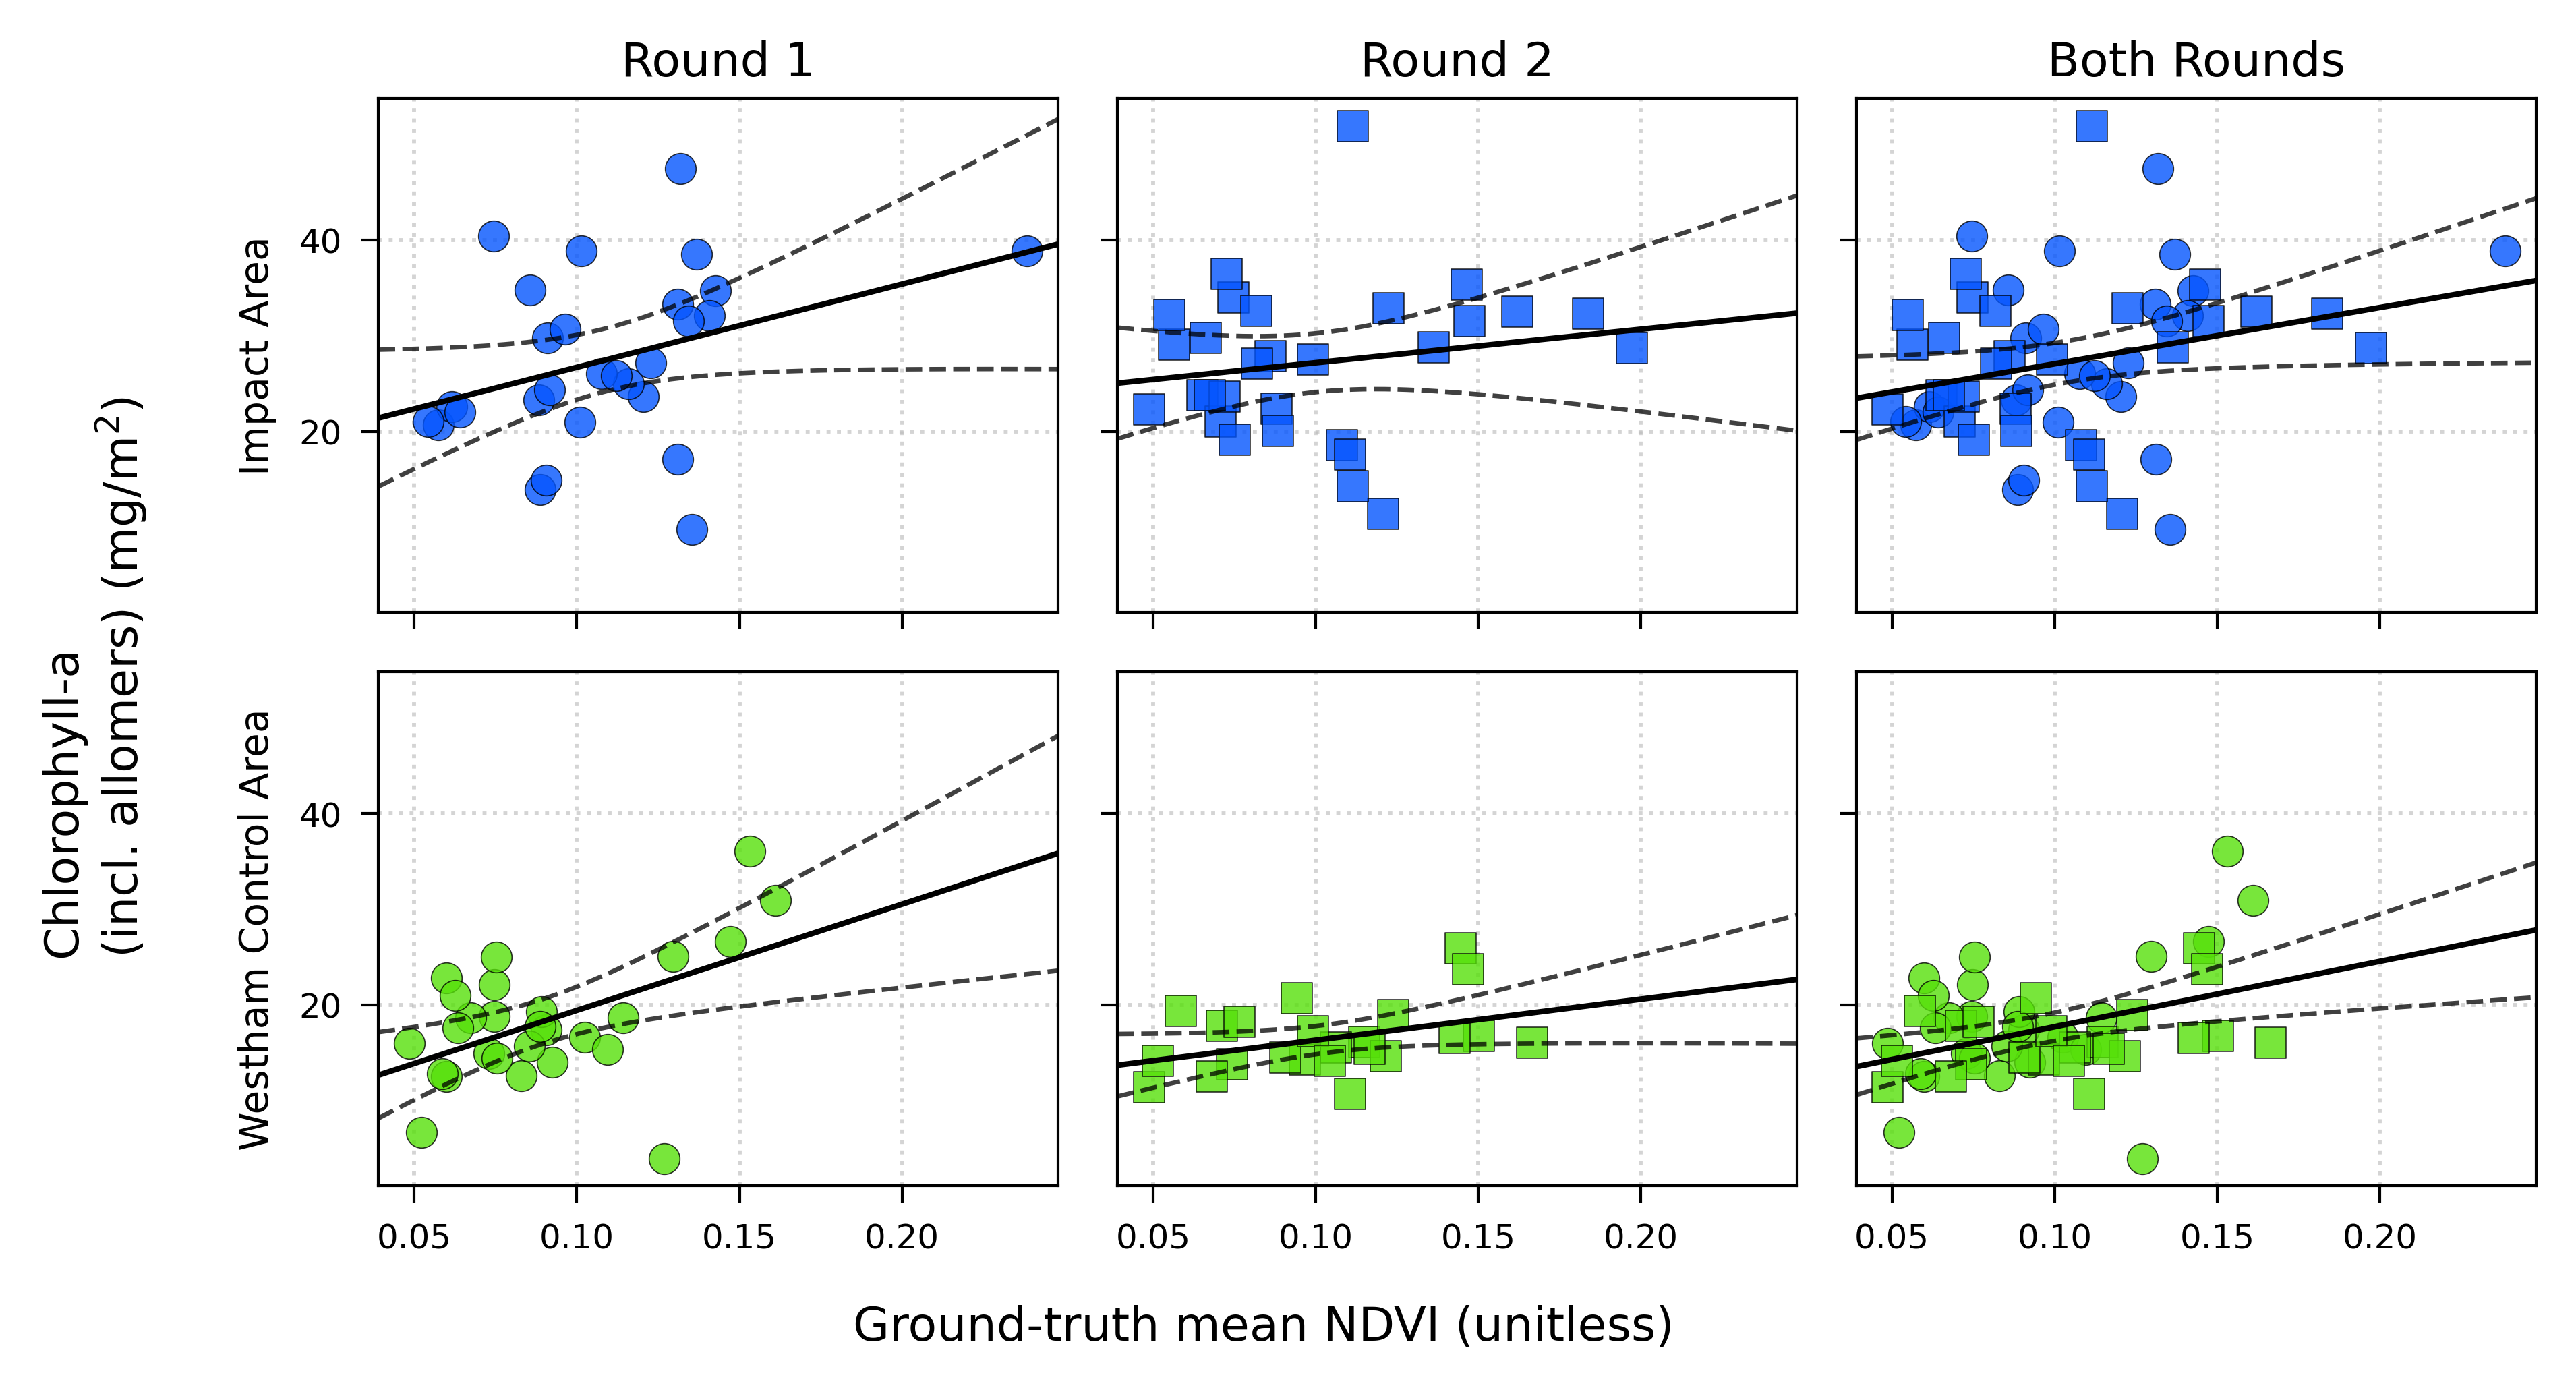

,area,panel_type,round,n,slope,intercept,r,r_squared,p_value,slope_standard_error,rmse,residual_standard_error,confidence_level,observed_x_min,observed_x_max,fit_x_min,fit_x_max
0,brunswick,round,1,28,87.085821,17.995165,0.360049,0.129635,0.059834,44.253727,8.163025,8.471171,0.95,0.054207,0.238462,0.03901,0.24796
1,brunswick,round,2,29,35.073845,23.672089,0.169233,0.028640,0.380153,39.310328,7.789250,8.072588,0.95,0.048689,0.197274,0.03901,0.24796
2,brunswick,combined,1+2,57,58.909577,21.174592,0.264696,0.070064,0.046614,28.938960,8.033953,8.178721,0.95,0.048689,0.238462,0.03901,0.24796
3,westham,round,1,27,111.090407,8.314718,0.515115,0.265343,0.005967,36.969580,5.687036,5.910141,0.95,0.048508,0.161012,0.03901,0.24796
4,westham,round,2,23,42.931597,12.016927,0.394680,0.155772,0.062358,21.809844,3.245844,3.396894,0.95,0.048669,0.166436,0.03901,0.24796
5,westham,combined,1+2,50,68.417148,10.869862,0.401351,0.161082,0.003868,22.536174,5.044026,5.148037,0.95,0.048508,0.166436,0.03901,0.24796


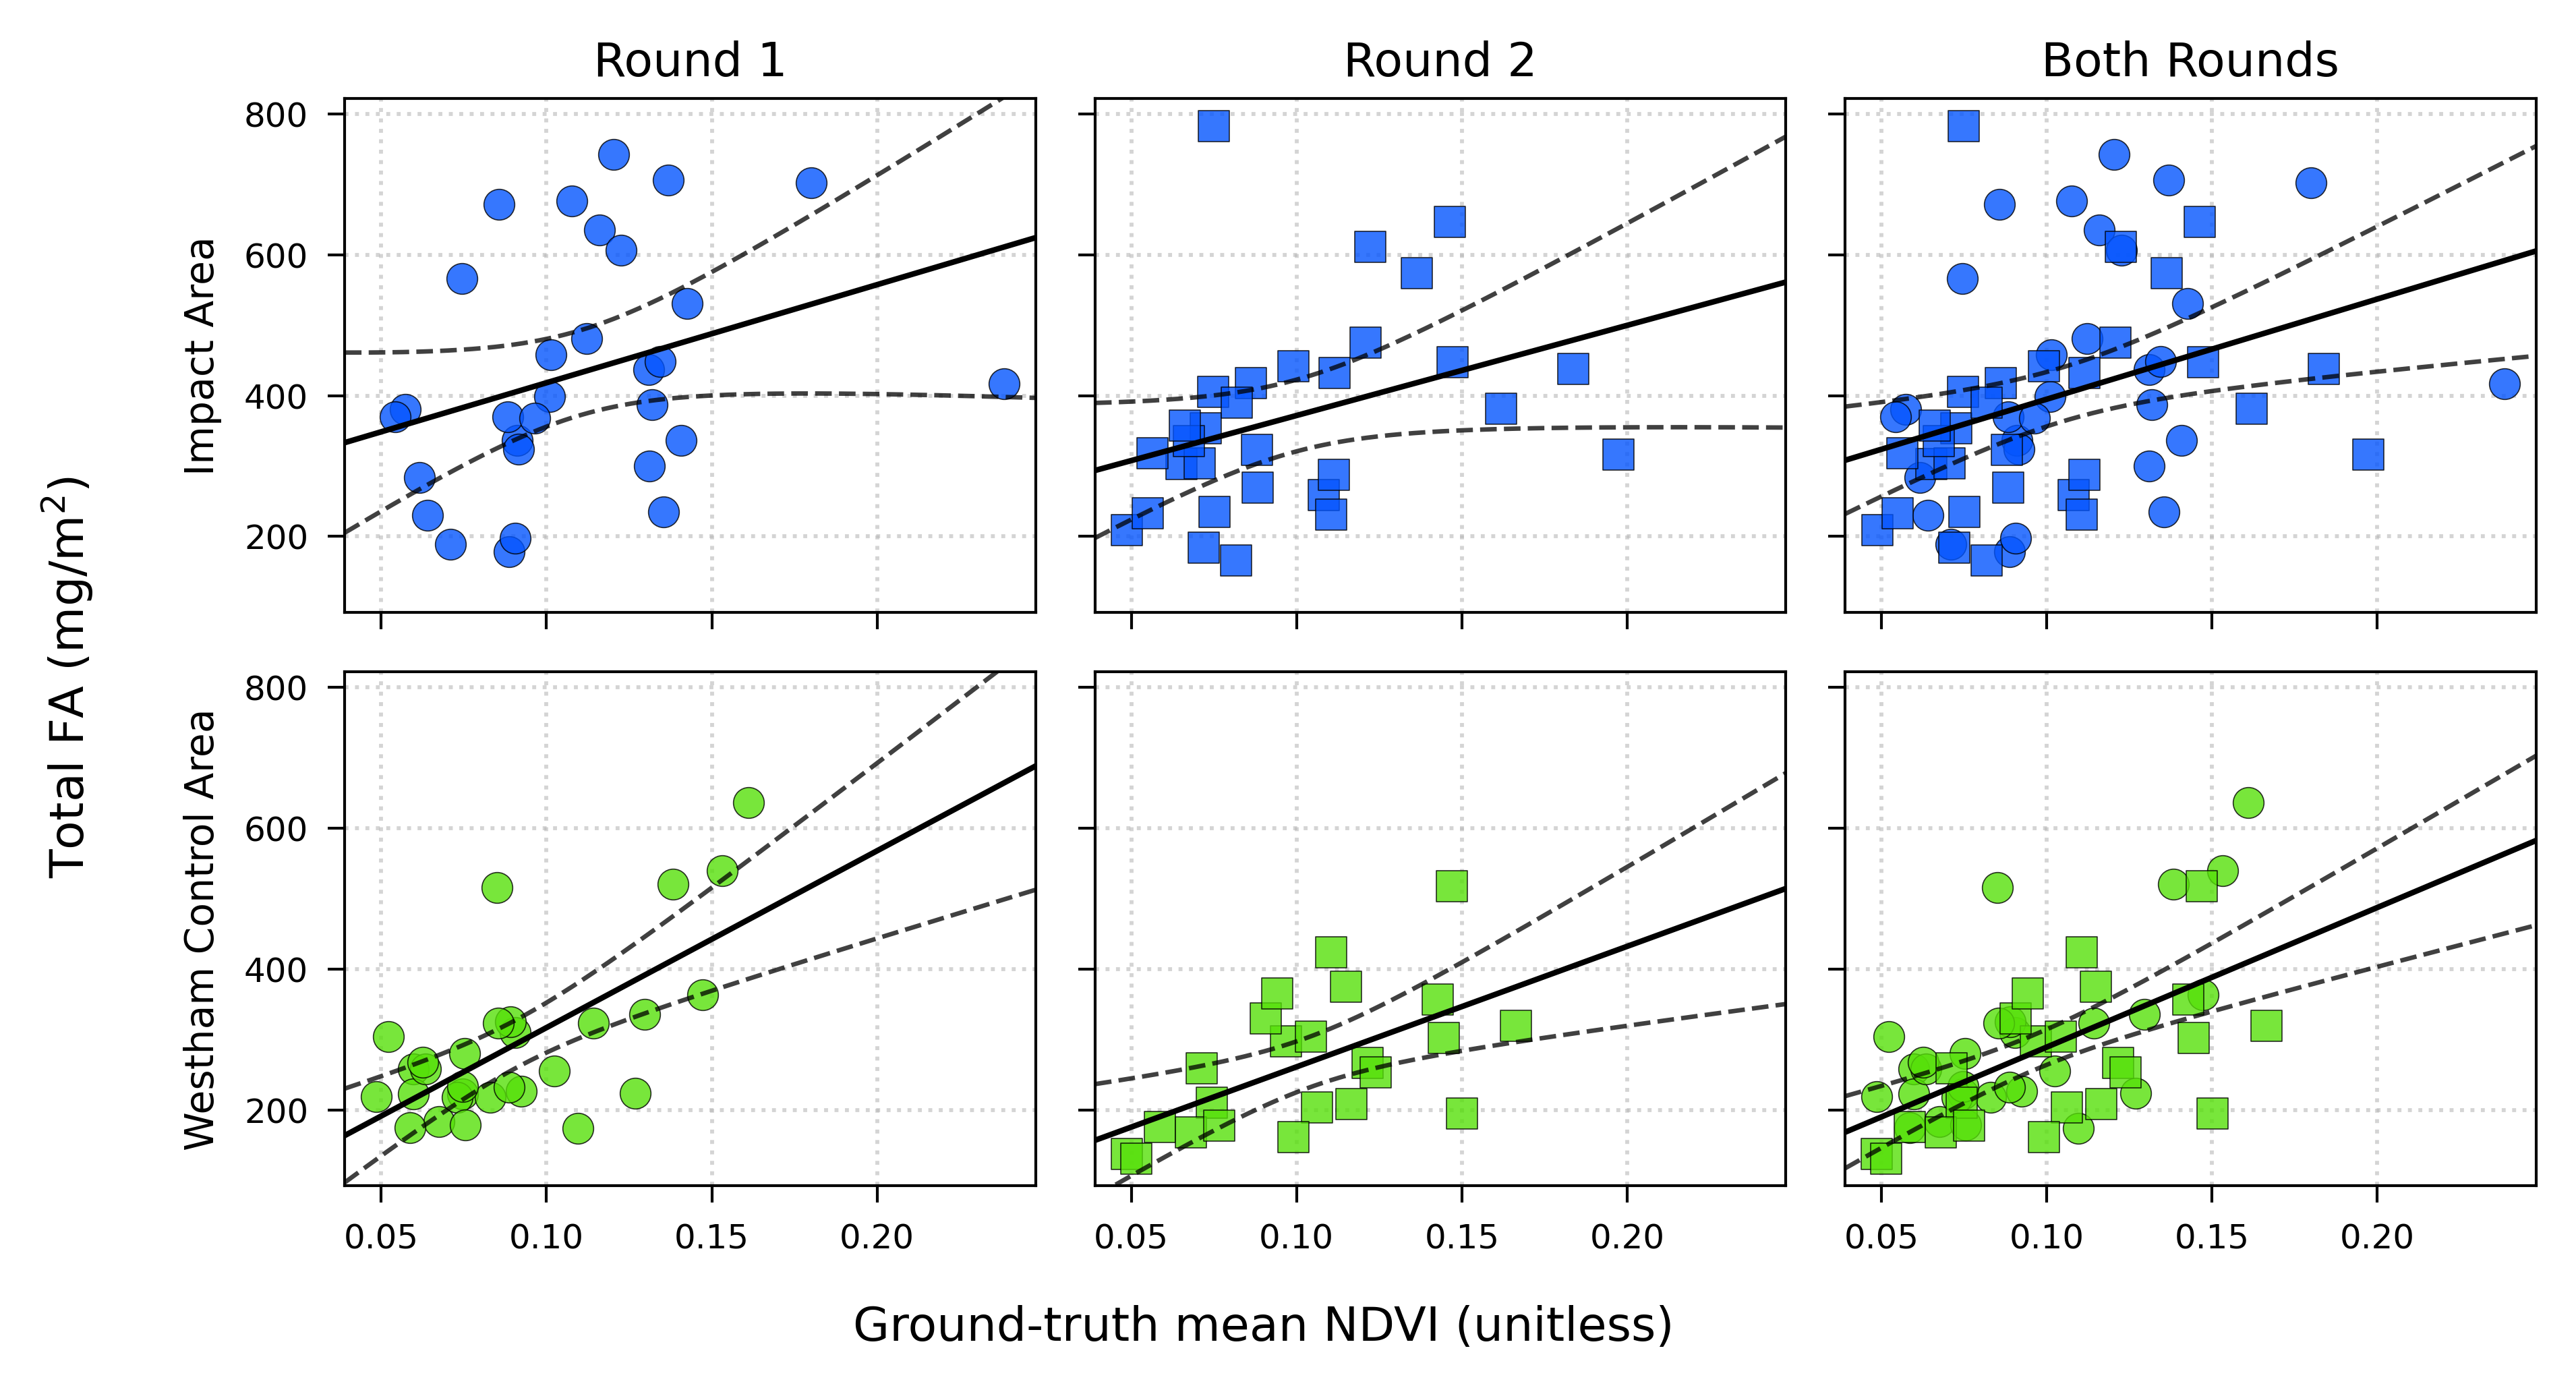

,area,panel_type,round,n,slope,intercept,r,r_squared,p_value,slope_standard_error,rmse,residual_standard_error,confidence_level,observed_x_min,observed_x_max,fit_x_min,fit_x_max
0,brunswick,round,1,30,1393.056428,278.853467,0.321186,0.103160,0.083515,776.229971,155.686453,161.150789,0.95,0.054207,0.238462,0.03901,0.24796
1,brunswick,round,2,30,1280.408580,243.654186,0.345255,0.119201,0.061677,657.759967,131.448058,136.061667,0.95,0.048689,0.197274,0.03901,0.24796
2,brunswick,combined,1+2,60,1422.105457,252.617303,0.348838,0.121688,0.006302,501.669872,145.959956,148.455179,0.95,0.048689,0.238462,0.03901,0.24796
3,westham,round,1,29,2511.286428,65.703256,0.669831,0.448673,0.000071,535.739998,86.319529,89.459441,0.95,0.048508,0.161012,0.03901,0.24796
4,westham,round,2,23,1711.099894,90.048803,0.574357,0.329886,0.004154,532.179261,79.201438,82.887175,0.95,0.048669,0.166436,0.03901,0.24796
5,westham,combined,1+2,52,1982.266617,90.948644,0.586867,0.344412,0.000005,386.770166,88.194155,89.940744,0.95,0.048508,0.166436,0.03901,0.24796


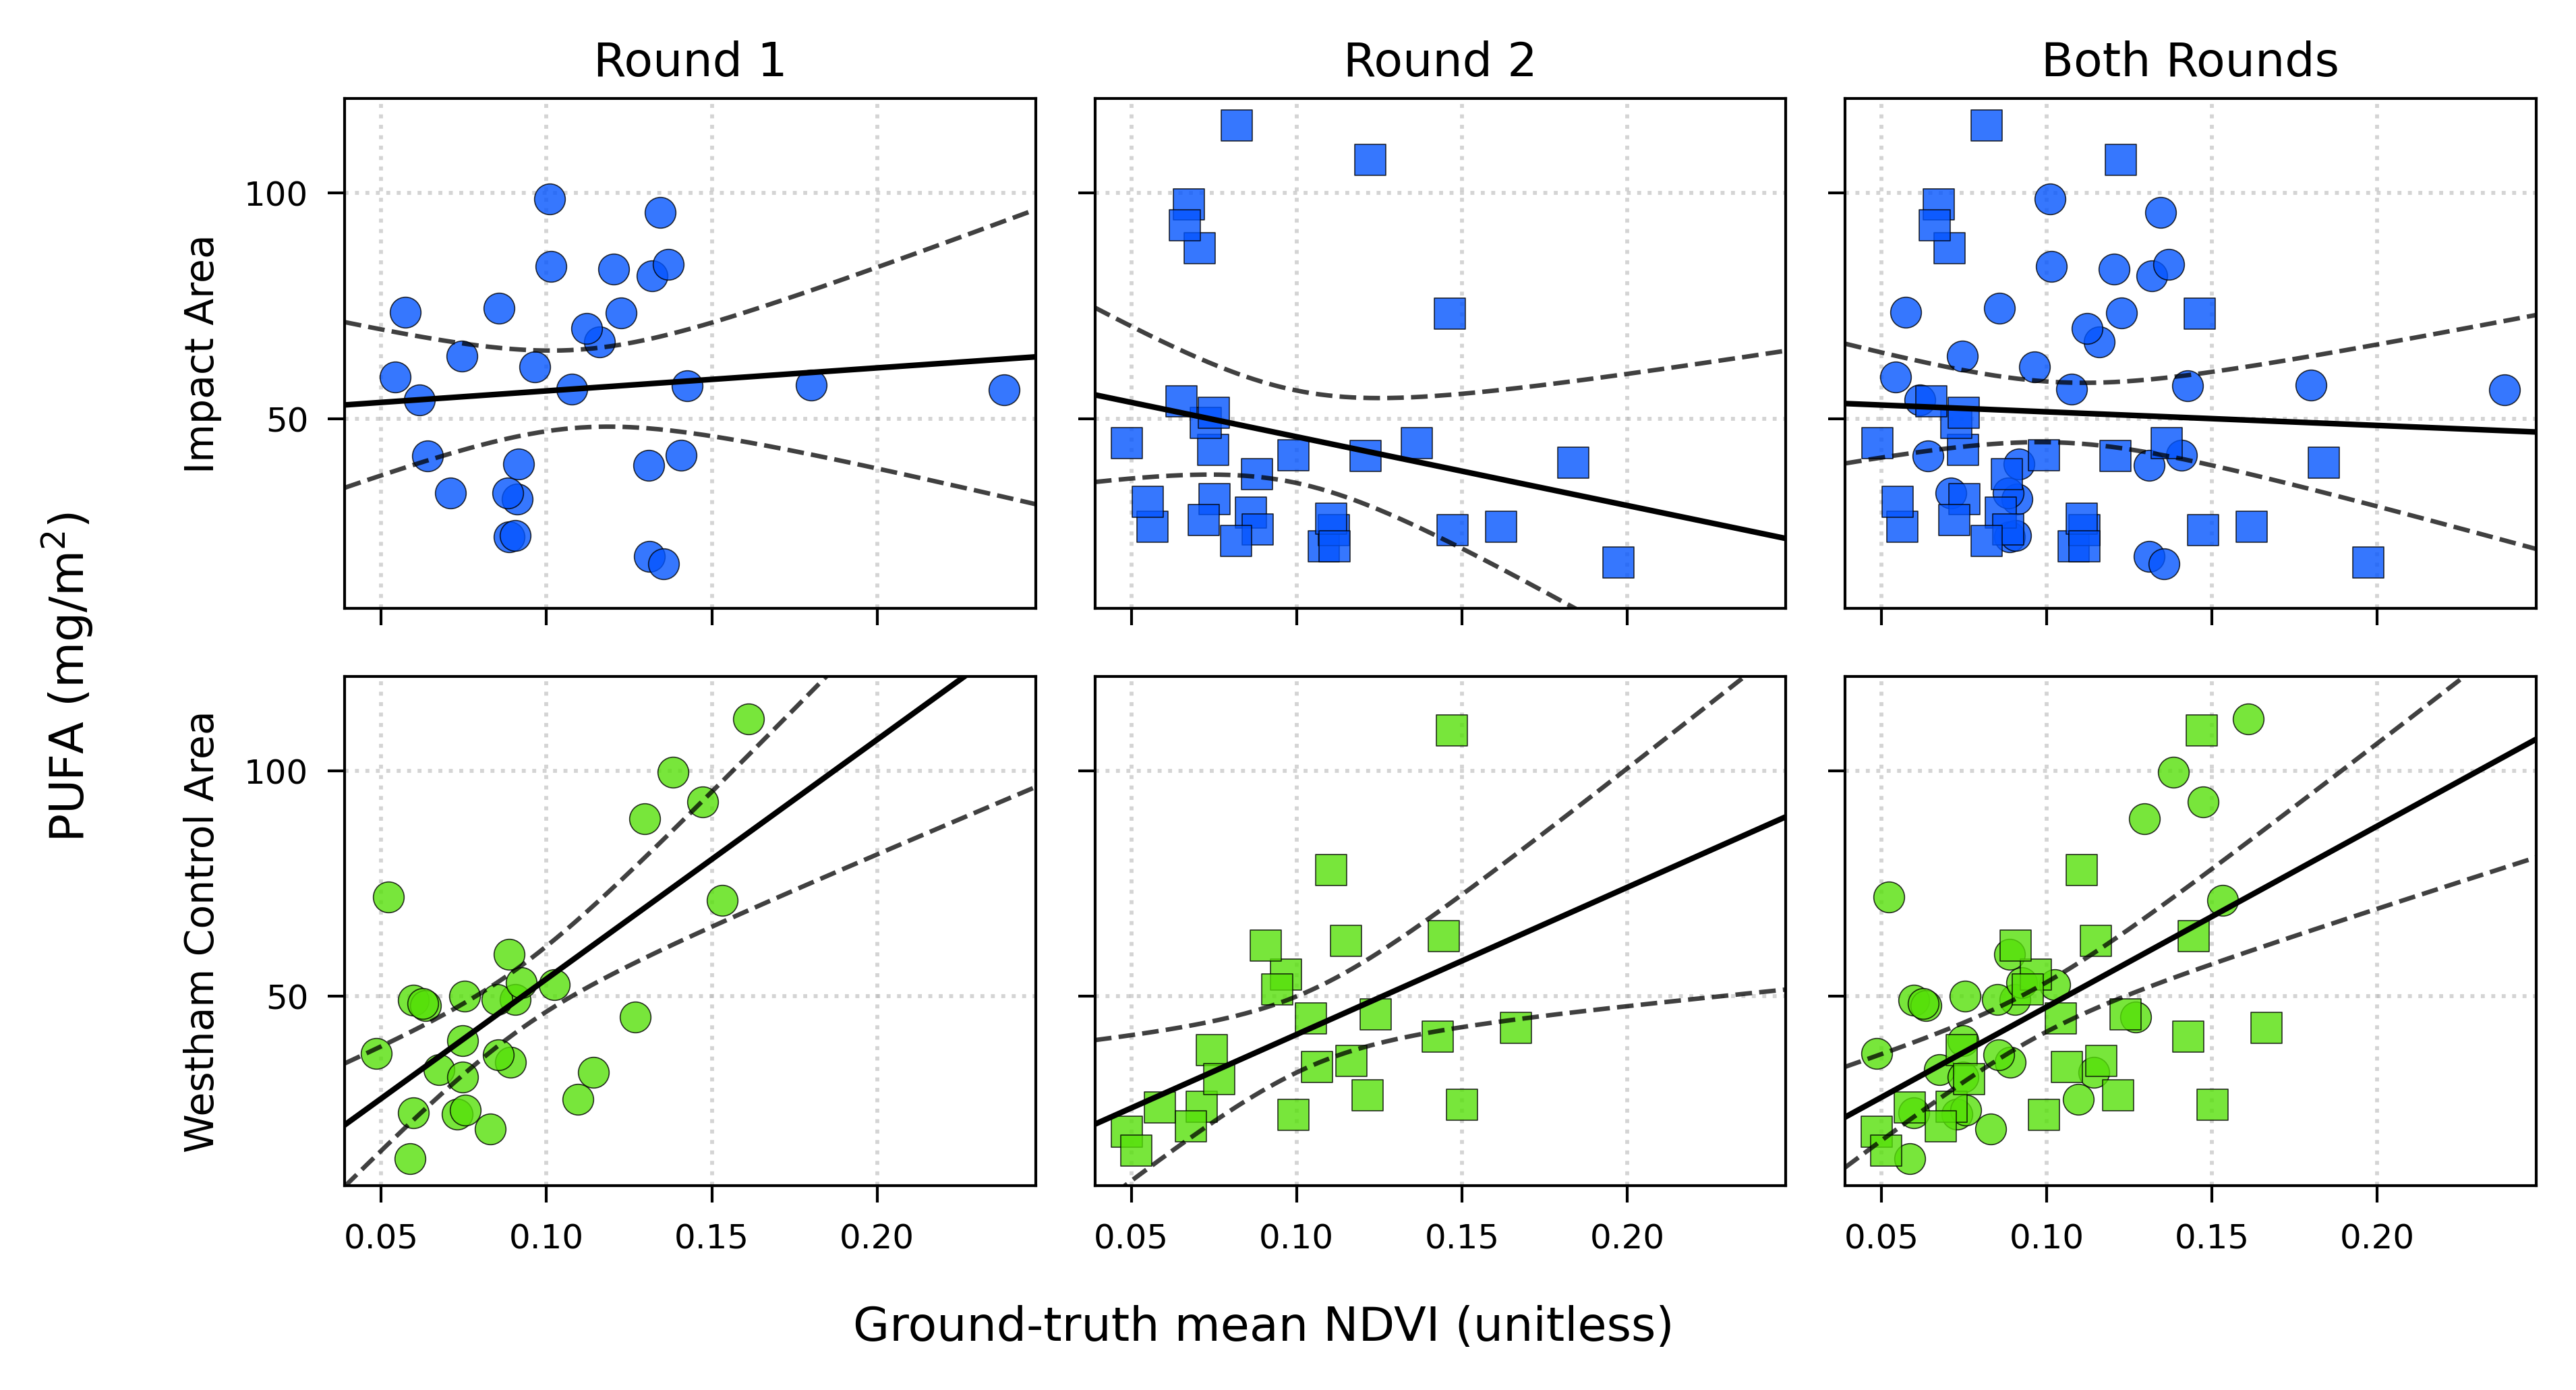

,area,panel_type,round,n,slope,intercept,r,r_squared,p_value,slope_standard_error,rmse,residual_standard_error,confidence_level,observed_x_min,observed_x_max,fit_x_min,fit_x_max
0,brunswick,round,1,30,50.953054,51.019291,0.086205,0.007431,0.650586,111.285029,22.320153,23.103553,0.95,0.054207,0.238462,0.03901,0.24796
1,brunswick,round,2,30,-152.204134,61.177316,-0.212389,0.045109,0.259833,132.340350,26.447158,27.375410,0.95,0.048689,0.197274,0.03901,0.24796
2,brunswick,combined,1+2,60,-30.138792,54.491765,-0.045332,0.002055,0.730898,87.208544,25.373170,25.806931,0.95,0.048689,0.238462,0.03901,0.24796
3,westham,round,1,29,529.800424,0.890910,0.681756,0.464791,0.000047,109.411479,17.628602,18.269851,0.95,0.048508,0.161012,0.03901,0.24796
4,westham,round,2,23,325.735609,8.996124,0.496863,0.246873,0.015870,124.151786,18.476857,19.336700,0.95,0.048669,0.166436,0.03901,0.24796
5,westham,combined,1+2,52,400.414083,7.634565,0.558418,0.311831,0.000017,84.122598,19.182249,19.562132,0.95,0.048508,0.166436,0.03901,0.24796


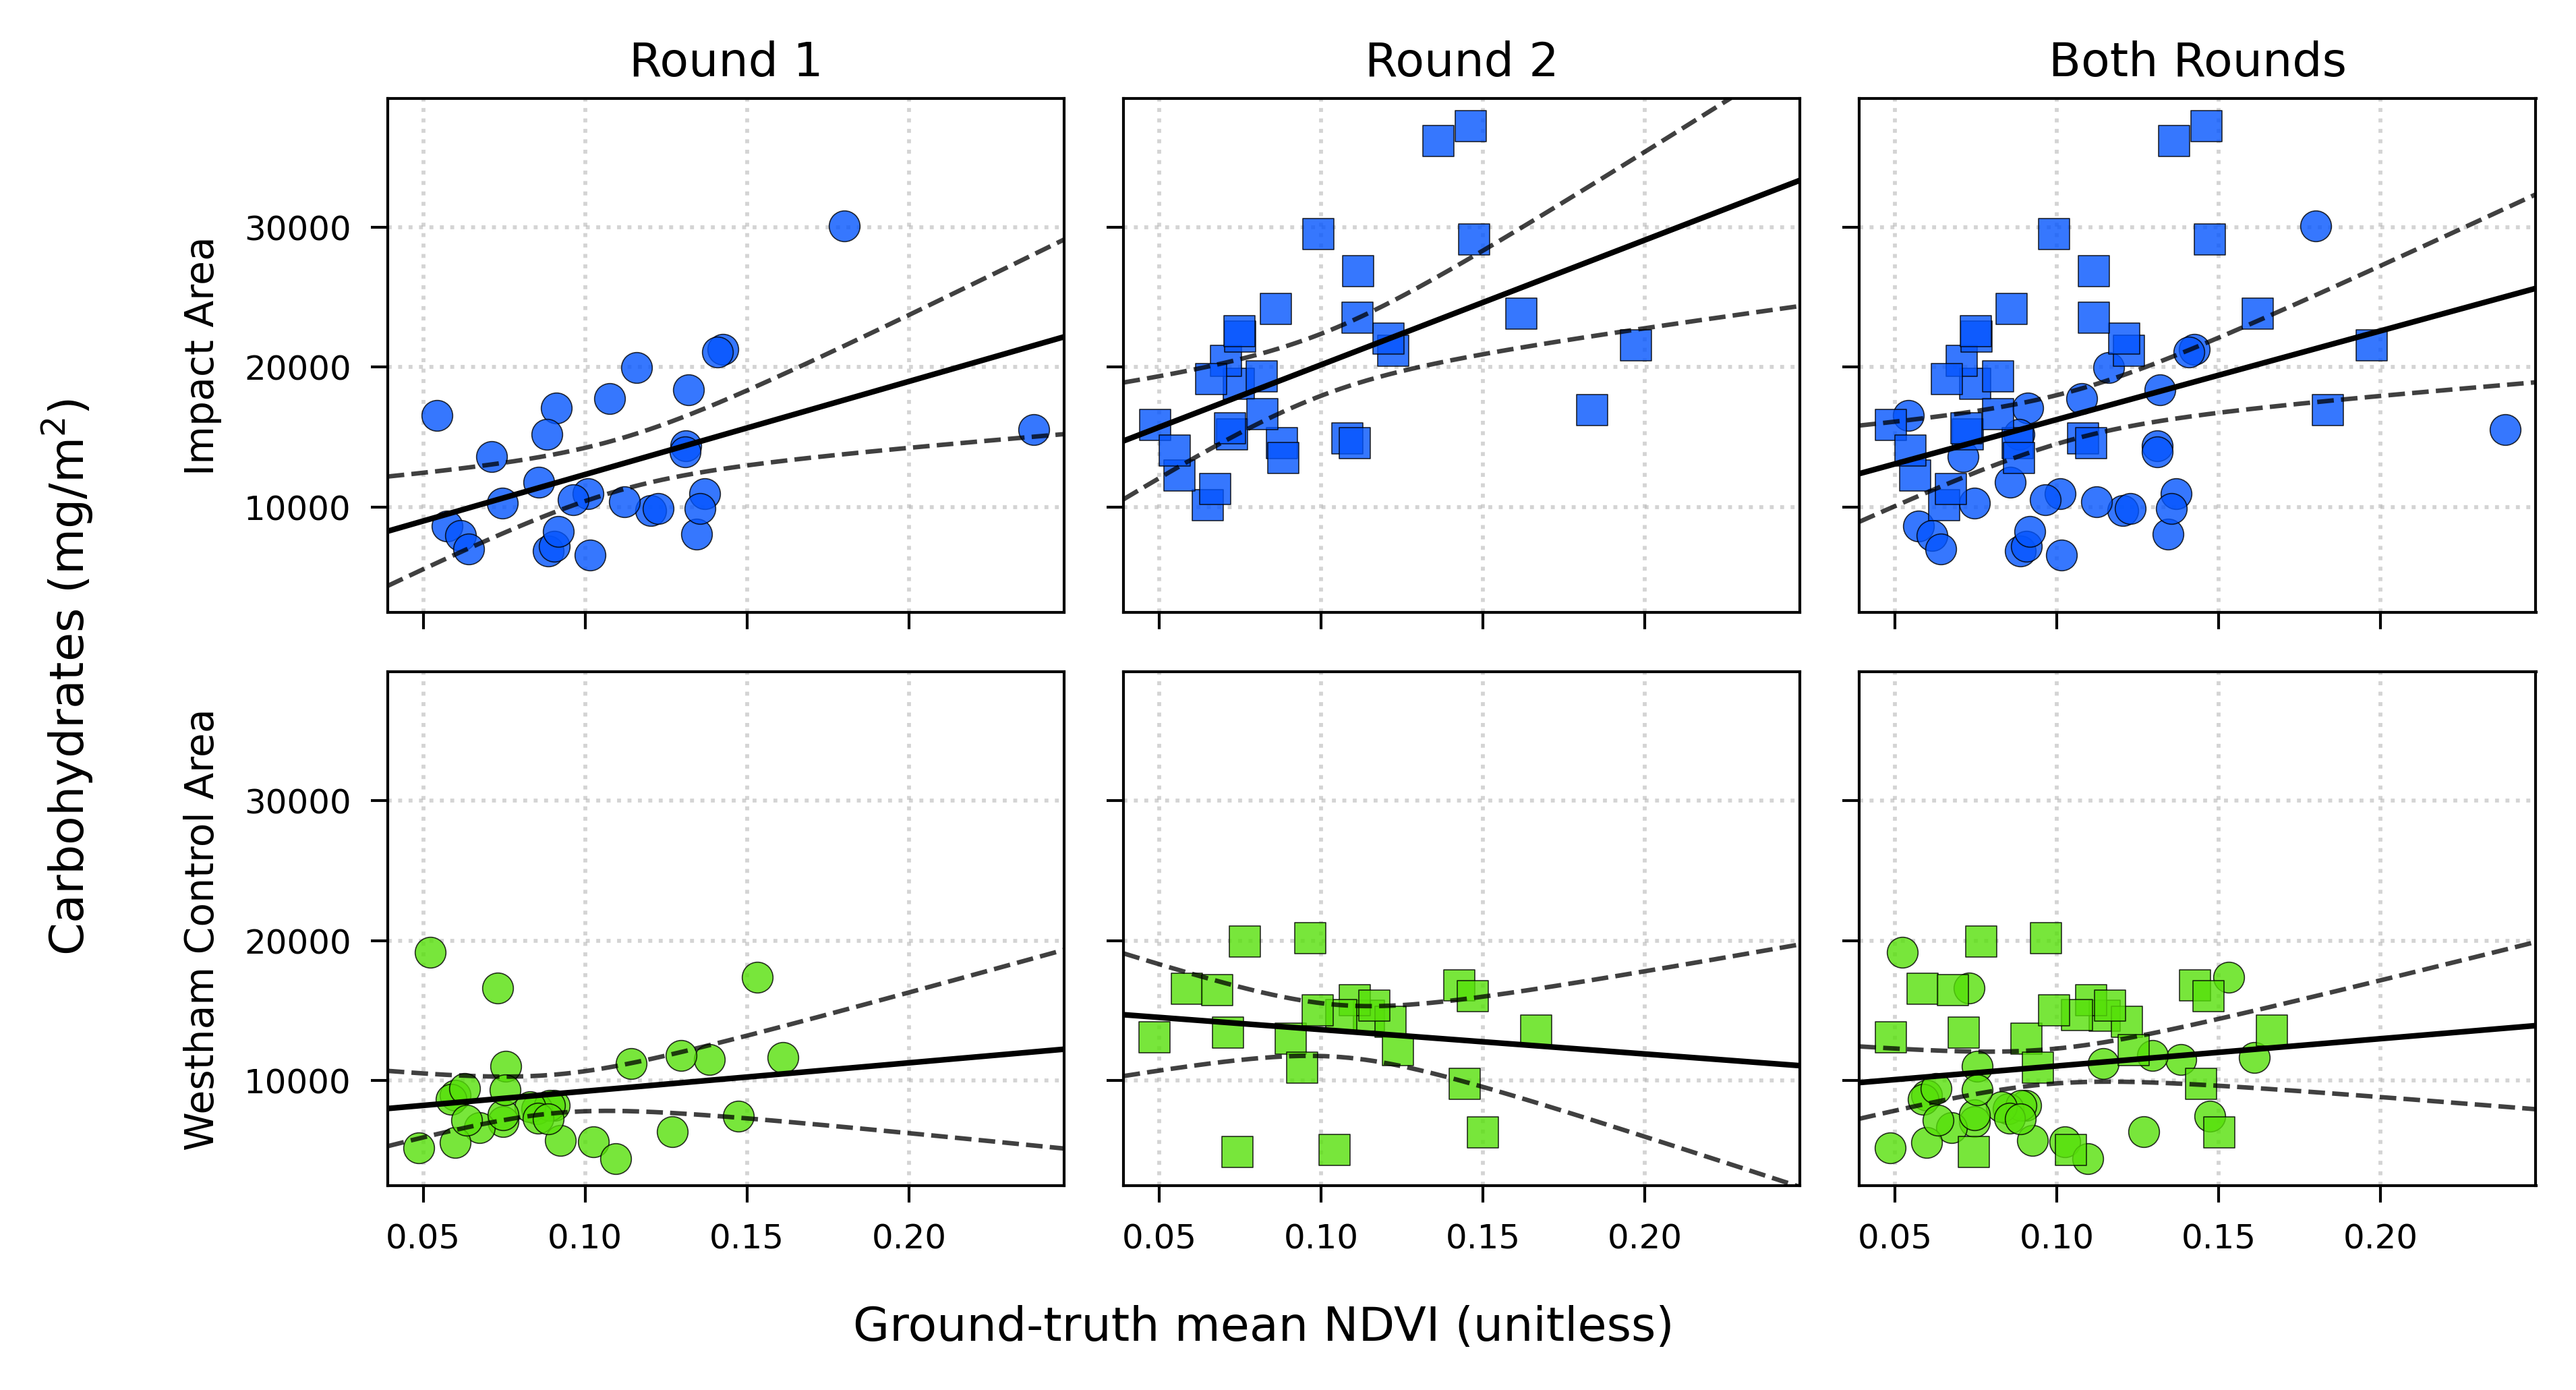

,area,panel_type,round,n,slope,intercept,r,r_squared,p_value,slope_standard_error,rmse,residual_standard_error,confidence_level,observed_x_min,observed_x_max,fit_x_min,fit_x_max
0,brunswick,round,1,30,66422.179129,5693.334430,0.468137,0.219152,0.009083,23694.353183,4752.315611,4919.113995,0.95,0.054207,0.238462,0.03901,0.24796
1,brunswick,round,2,30,89059.518375,11256.326855,0.507312,0.257365,0.004218,28589.995052,5713.481393,5914.015100,0.95,0.048689,0.197274,0.03901,0.24796
2,brunswick,combined,1+2,60,63322.646806,9923.851094,0.345324,0.119249,0.006887,22596.676555,6574.462804,6686.854925,0.95,0.048689,0.238462,0.03901,0.24796
3,westham,round,1,29,20265.761297,7221.949043,0.177553,0.031525,0.356819,21617.117581,3482.994383,3609.689873,0.95,0.048508,0.161012,0.03901,0.24796
4,westham,round,2,22,-17407.668579,15388.624090,-0.135321,0.018312,0.548217,28500.222443,3978.967522,4173.176344,0.95,0.048669,0.166436,0.03901,0.24796
5,westham,combined,1+2,51,19466.805027,9104.278696,0.142603,0.020336,0.318154,19302.148312,4314.632119,4401.805210,0.95,0.048508,0.166436,0.03901,0.24796


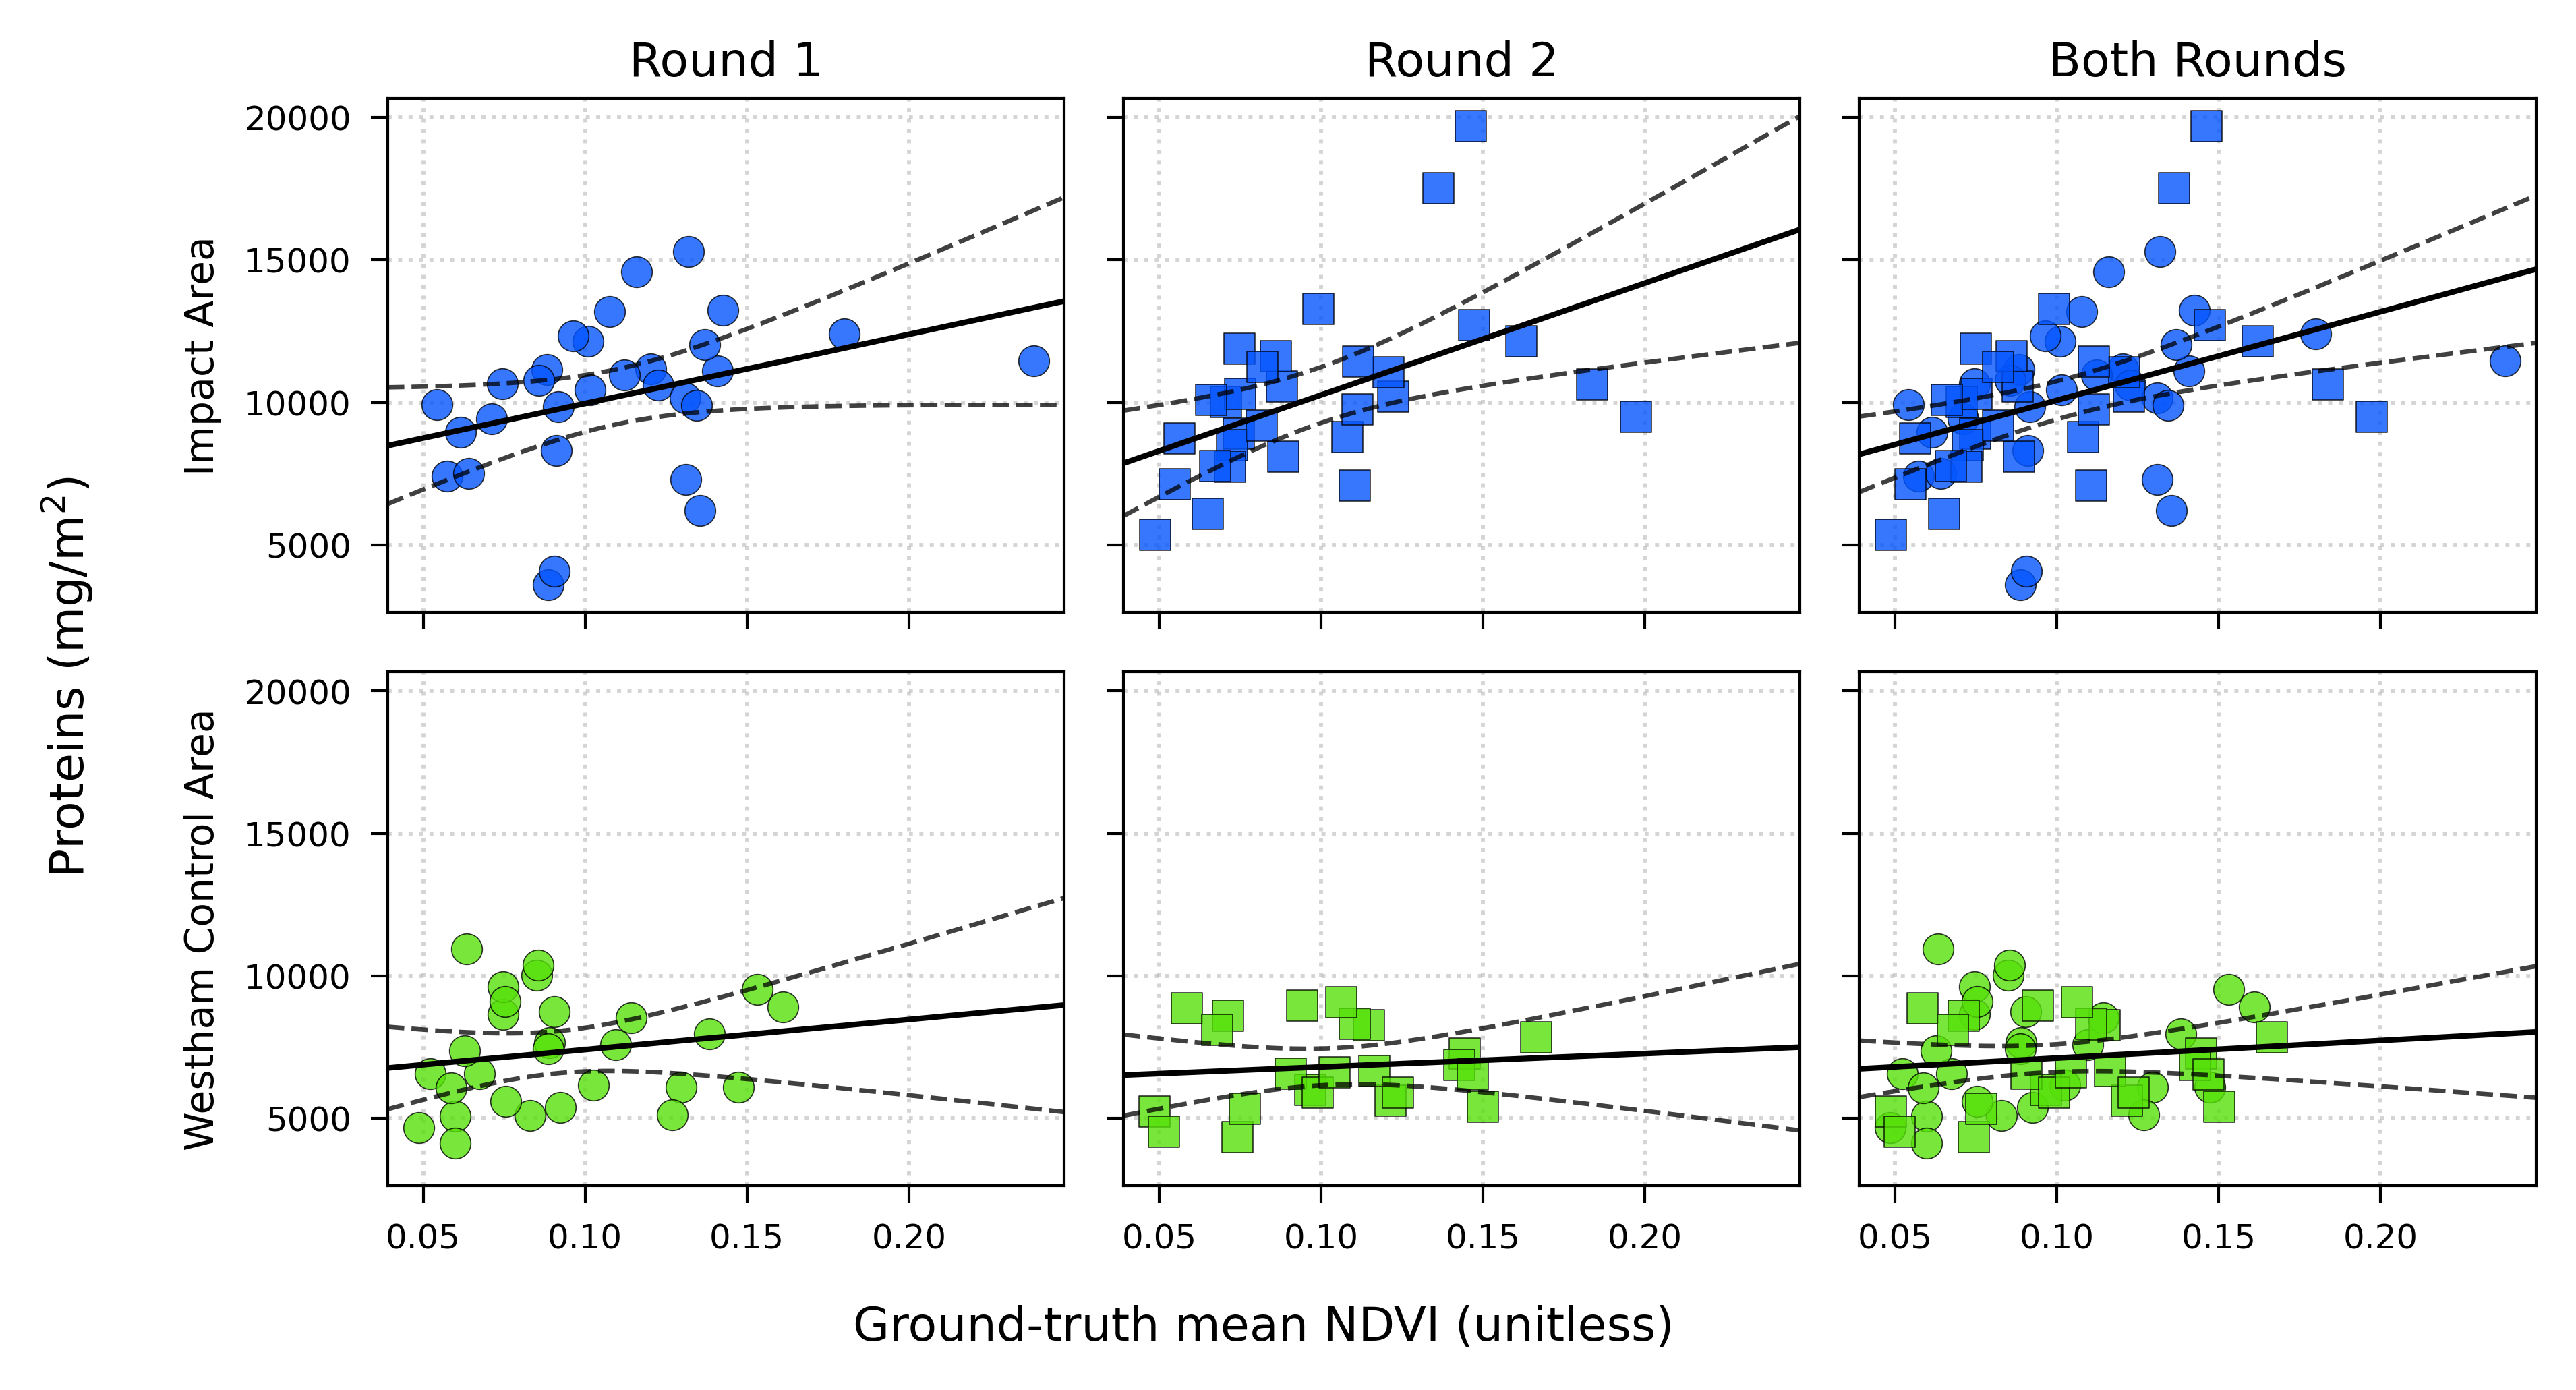

,area,panel_type,round,n,slope,intercept,r,r_squared,p_value,slope_standard_error,rmse,residual_standard_error,confidence_level,observed_x_min,observed_x_max,fit_x_min,fit_x_max
0,brunswick,round,1,30,24274.109713,7535.776262,0.346386,0.119983,0.060774,12423.669407,2491.783490,2579.240952,0.95,0.054207,0.238462,0.03901,0.24796
1,brunswick,round,2,30,39264.954396,6334.379860,0.505450,0.255480,0.004383,12667.356624,2531.469706,2620.320088,0.95,0.048689,0.197274,0.03901,0.24796
2,brunswick,combined,1+2,60,31076.854660,6967.909890,0.424240,0.179979,0.000730,8710.119898,2534.193873,2577.516565,0.95,0.048689,0.238462,0.03901,0.24796
3,westham,round,1,28,10575.862837,6357.648304,0.177946,0.031665,0.364973,11469.765045,1834.218312,1903.458299,0.95,0.048508,0.161012,0.03901,0.24796
4,westham,round,2,23,4688.534585,6338.549829,0.107204,0.011493,0.626352,9488.699533,1412.153198,1477.869494,0.95,0.048669,0.166436,0.03901,0.24796
5,westham,combined,1+2,51,6183.615612,6500.571337,0.118016,0.013928,0.409485,7432.868465,1685.301071,1719.350997,0.95,0.048508,0.166436,0.03901,0.24796


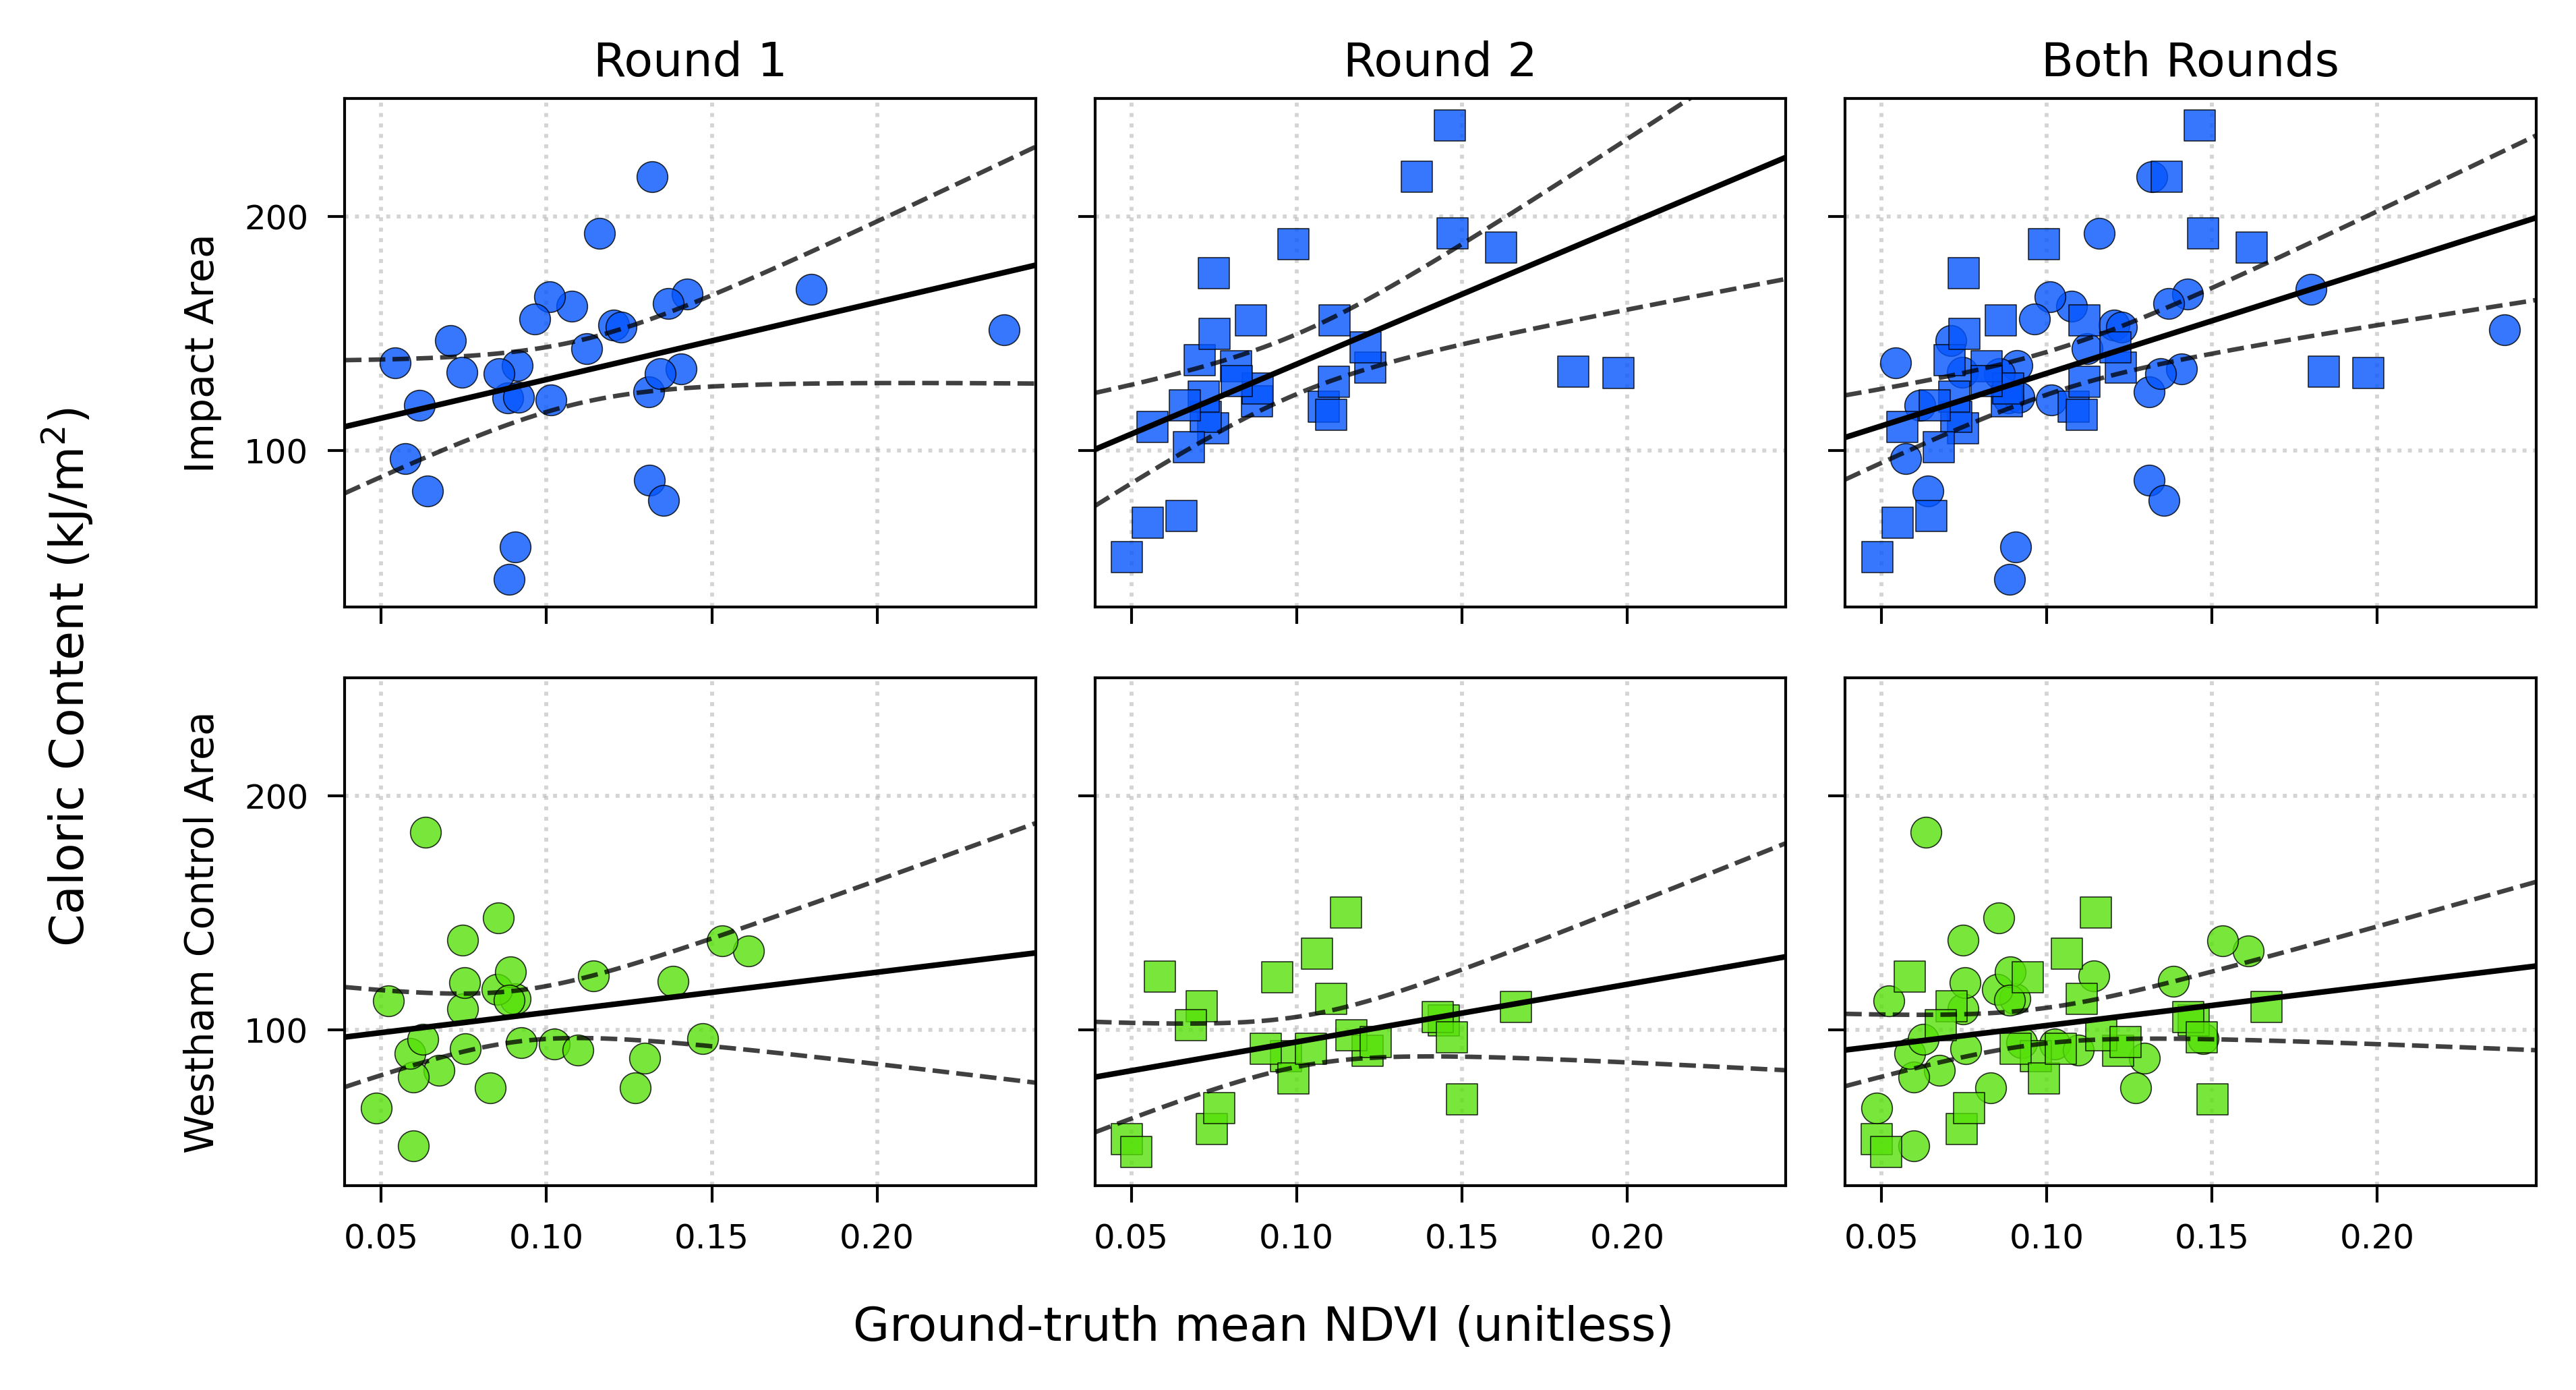

,area,panel_type,round,n,slope,intercept,r,r_squared,p_value,slope_standard_error,rmse,residual_standard_error,confidence_level,observed_x_min,observed_x_max,fit_x_min,fit_x_max
0,brunswick,round,1,30,330.568168,97.300783,0.340168,0.115715,0.065872,172.696756,34.637345,35.853058,0.95,0.054207,0.238462,0.03901,0.24796
1,brunswick,round,2,30,597.695362,77.157921,0.563385,0.317403,0.001188,165.644685,33.102763,34.264615,0.95,0.048689,0.197274,0.03901,0.24796
2,brunswick,combined,1+2,60,449.495261,88.054409,0.445898,0.198825,0.000356,118.478310,34.471053,35.060345,0.95,0.048689,0.238462,0.03901,0.24796
3,westham,round,1,28,172.196830,90.135604,0.195467,0.038207,0.318853,169.435876,27.095794,28.118634,0.95,0.048508,0.161012,0.03901,0.24796
4,westham,round,2,23,246.282151,70.139722,0.322921,0.104278,0.132862,157.512061,23.441691,24.532579,0.95,0.048669,0.166436,0.03901,0.24796
5,westham,combined,1+2,51,171.917271,84.598942,0.207211,0.042936,0.144570,115.952313,26.290598,26.821775,0.95,0.048508,0.166436,0.03901,0.24796


In [22]:
for var, var_label in config.VAR_TO_PREDICT_LABELS.items():
    # if var != 'Total Carbs (mg/m2)':
    #     continue
    unit = re.search(r"\((.*?)\)", var).group(0) if re.search(r"\((.*?)\)", var) else ""
    label_and_unit = f"{var_label} {unit}" if unit else var_label
    label_and_unit = label_and_unit.replace('/m2','/m$^2$')

    fig, axes, fit_statistics = scatterplot_area_round_combined_grid(
        dataframe=df_all_R,
        x="gt_ndvi_mean",
        y=var,
        area_order=[
            "brunswick",
            "westham",
        ],
        round_order=[
            1,
            2,
        ],
        area_colors=config.SITE_COLORS,
        area_labels=config.SITE_LABELS,
        x_label="Ground-truth mean NDVI (unitless)",
        y_label=label_and_unit,
        share_y_across_areas=True,
        # Optional quality-control filter
        keep_column=f"Keep {var}",
        use_common_y_label=True,
        show_area_row_labels=True,
        # Common legend at the top
        show_legend=False,
        legend_ncols=3,
        confidence_level=0.95,
        extend_fits_to_xlim=True,
        fit_color="black",
        ci_color="black",
        fit_line_width=1.0,
        ci_line_width=0.8,
        ci_line_alpha=0.75,
        ci_line_style="--",
        annotate_stations=False,
        width_in=6.5,
        aspect_ratio=0.55,
        dpi=300,
        # output_path=(
        #     "outputs/chla_vs_ndvi_round_grid.svg"
        # ),
        title=None,
        point_size=30,
    )

    plt.show()

    display(fit_statistics)

In [99]:
"""Automatic statistical decision for pooling two independent rounds."""

from collections.abc import Hashable, Mapping, Sequence
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import statsmodels.api as sm


def test_round_pooling_decision(
    dataframe: pd.DataFrame,
    x: Hashable,
    y_variables: Hashable | Sequence[Hashable],
    *,
    site_level: str = "site",
    round_level: str = "round",
    area_order: Sequence[Any] | None = None,
    round_order: Sequence[Any] = (1, 2),
    keep_column: (str | Hashable | Mapping[Hashable, Hashable | None] | None) = "auto",
    alpha: float = 0.05,
    minimum_per_round: int = 10,
    robust_covariance: str = "HC3",
    p_adjust: str = "fdr_bh",
    p_adjust_scope: str = "global",
    output_path: str | Path | None = None,
) -> pd.DataFrame:
    """
    Decide automatically whether two independent rounds should be pooled.

    Policy
    ------
    Rounds are pooled by default. A pooled fit is rejected only when:

    1. the comparison is considered reliable; and
    2. the FDR-adjusted joint test finds a significant round-related
       difference in the regression line.

    Models
    ------
    Pooled model
        y = intercept + slope * x

    Common-slope model
        y = intercept + slope * x + round effect

    Full model
        y = intercept + slope * x + round effect
            + x-by-round interaction

    Primary test
    ------------
    The full model jointly tests whether both the round effect and the
    x-by-round interaction are zero. A significant adjusted result is a
    reason not to pool.

    Reliability requirements
    ------------------------
    * at least ``minimum_per_round`` observations in both rounds;
    * at least two distinct x values in each round;
    * an overlapping observed x-range between rounds;
    * a finite joint-test q-value.

    Keep-column handling
    --------------------
    keep_column="auto"
        Uses ``Keep {y_variable}`` when that column exists.

    keep_column=None
        Does not apply a keep filter.

    keep_column="column name"
        Applies one keep column to every response variable.

    keep_column={y_variable: keep_column}
        Applies variable-specific keep columns.

    Returns
    -------
    pandas.DataFrame
        One row per area and response variable, including ``pool_rounds``
        and ``pooling_decision``.
    """

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------

    def normalize_y_variables() -> list[Hashable]:
        try:
            if y_variables in dataframe.columns:
                return [y_variables]
        except (TypeError, ValueError):
            pass

        if isinstance(y_variables, (str, bytes)):
            return [y_variables]

        return list(y_variables)

    def resolve_keep_column(y_variable: Hashable) -> Hashable | None:
        if keep_column is None:
            return None

        if isinstance(keep_column, Mapping):
            return keep_column.get(y_variable)

        if keep_column == "auto":
            candidate = f"Keep {y_variable}"
            return candidate if candidate in dataframe.columns else None

        return keep_column

    def bh_adjust(p_values: Sequence[float]) -> np.ndarray:
        p = np.asarray(p_values, dtype=float)
        q = np.full(p.shape, np.nan)
        valid = np.isfinite(p)

        if not valid.any():
            return q

        values = p[valid]
        order = np.argsort(values)
        ranked = values[order]
        number_of_tests = len(ranked)

        adjusted = ranked * number_of_tests / np.arange(1, number_of_tests + 1)

        adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]

        adjusted = np.clip(
            adjusted,
            0,
            1,
        )

        restored = np.empty_like(adjusted)
        restored[order] = adjusted
        q[valid] = restored

        return q

    def fit_ols(
        y_values: np.ndarray,
        design: pd.DataFrame,
    ):
        model = sm.OLS(
            y_values,
            design,
            missing="drop",
        )

        if robust_covariance.lower() == "nonrobust":
            return model.fit()

        return model.fit(
            cov_type=robust_covariance,
        )

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError("dataframe must be a pandas DataFrame.")

    if not isinstance(dataframe.index, pd.MultiIndex):
        raise TypeError("dataframe.index must be a pandas MultiIndex.")

    required_levels = {
        site_level,
        round_level,
    }

    missing_levels = required_levels - set(dataframe.index.names)

    if missing_levels:
        raise KeyError(f"Missing index levels: {sorted(missing_levels)}")

    if x not in dataframe.columns:
        raise KeyError(f"x variable {x!r} was not found.")

    y_list = normalize_y_variables()

    if not y_list:
        raise ValueError("At least one response variable must be provided.")

    missing_y_variables = [
        variable for variable in y_list if variable not in dataframe.columns
    ]

    if missing_y_variables:
        raise KeyError(f"Response variables not found: {missing_y_variables}")

    if isinstance(round_order, (str, bytes)):
        round_order = [round_order]
    else:
        round_order = list(round_order)

    if len(round_order) != 2:
        raise ValueError("round_order must contain exactly two rounds.")

    if area_order is None:
        areas = list(pd.unique(dataframe.index.get_level_values(site_level)))

    elif isinstance(area_order, (str, bytes)):
        areas = [area_order]

    else:
        areas = list(area_order)

    if not areas:
        raise ValueError("At least one area must be provided.")

    available_areas = set(dataframe.index.get_level_values(site_level))

    available_rounds = set(dataframe.index.get_level_values(round_level))

    missing_areas = [area for area in areas if area not in available_areas]

    missing_rounds = [
        round_value
        for round_value in round_order
        if round_value not in available_rounds
    ]

    if missing_areas:
        raise KeyError(f"Area(s) not found: {missing_areas}")

    if missing_rounds:
        raise KeyError(f"Round(s) not found: {missing_rounds}")

    if not 0 < alpha < 1:
        raise ValueError("alpha must be between zero and one.")

    if minimum_per_round < 3:
        raise ValueError("minimum_per_round must be at least three.")

    if p_adjust not in {
        "fdr_bh",
        "none",
    }:
        raise ValueError("p_adjust must be 'fdr_bh' or 'none'.")

    if p_adjust_scope not in {
        "global",
        "area",
    }:
        raise ValueError("p_adjust_scope must be 'global' or 'area'.")

    round_1, round_2 = round_order

    # ------------------------------------------------------------------
    # Fit models and collect unadjusted tests
    # ------------------------------------------------------------------

    records = []

    for area in areas:
        area_mask = dataframe.index.get_level_values(site_level) == area

        for y_variable in y_list:
            resolved_keep_column = resolve_keep_column(y_variable)

            selected_columns = [
                x,
                y_variable,
            ]

            if resolved_keep_column is not None:
                if resolved_keep_column not in dataframe.columns:
                    raise KeyError(
                        f"Keep column "
                        f"{resolved_keep_column!r} "
                        f"for {y_variable!r} "
                        "was not found."
                    )

                selected_columns.append(resolved_keep_column)

            working = dataframe.loc[
                area_mask,
                selected_columns,
            ].copy()

            if resolved_keep_column is not None:
                keep_mask = working[resolved_keep_column].fillna(False).astype(bool)

                working = working.loc[keep_mask]

            working = working.loc[
                :,
                [x, y_variable],
            ]

            working.columns = [
                "_x",
                "_y",
            ]

            working["_round"] = working.index.get_level_values(round_level)

            working = working.loc[working["_round"].isin(round_order)]

            working["_x"] = pd.to_numeric(
                working["_x"],
                errors="coerce",
            )

            working["_y"] = pd.to_numeric(
                working["_y"],
                errors="coerce",
            )

            working = working.dropna(
                subset=[
                    "_x",
                    "_y",
                ]
            )

            working["_round_indicator"] = (working["_round"] == round_2).astype(float)

            round_1_data = working.loc[working["_round"] == round_1]

            round_2_data = working.loc[working["_round"] == round_2]

            n_round_1 = len(round_1_data)
            n_round_2 = len(round_2_data)
            n_total = len(working)

            unique_x_round_1 = round_1_data["_x"].nunique()

            unique_x_round_2 = round_2_data["_x"].nunique()

            if n_round_1 > 0 and n_round_2 > 0:
                overlap_x_min = max(
                    float(round_1_data["_x"].min()),
                    float(round_2_data["_x"].min()),
                )

                overlap_x_max = min(
                    float(round_1_data["_x"].max()),
                    float(round_2_data["_x"].max()),
                )

                has_x_overlap = overlap_x_min < overlap_x_max

            else:
                overlap_x_min = np.nan
                overlap_x_max = np.nan
                has_x_overlap = False

            base_record: dict[str, Any] = {
                "area": area,
                "x_variable": x,
                "y_variable": y_variable,
                "keep_column": resolved_keep_column,
                "round_1": round_1,
                "round_2": round_2,
                "n_round_1": n_round_1,
                "n_round_2": n_round_2,
                "n_total": n_total,
                "unique_x_round_1": (unique_x_round_1),
                "unique_x_round_2": (unique_x_round_2),
                "overlap_x_min": overlap_x_min,
                "overlap_x_max": overlap_x_max,
                "has_x_overlap": has_x_overlap,
            }

            enough_data = (
                n_round_1 >= minimum_per_round
                and n_round_2 >= minimum_per_round
                and unique_x_round_1 >= 2
                and unique_x_round_2 >= 2
            )

            if not enough_data:
                base_record.update(
                    {
                        "status": ("insufficient_data"),
                        "slope_round_1": np.nan,
                        "slope_round_2": np.nan,
                        "slope_difference": np.nan,
                        "slope_difference_p": np.nan,
                        "round_effect_common_slope_p": (np.nan),
                        "joint_round_terms_p": np.nan,
                    }
                )

                records.append(base_record)
                continue

            x_center = float(working["_x"].mean())

            working["_x_centered"] = working["_x"] - x_center

            y_values = working["_y"].to_numpy(dtype=float)

            pooled_design = pd.DataFrame(
                {
                    "const": 1.0,
                    "x_centered": (working["_x_centered"]),
                },
                index=working.index,
            )

            common_slope_design = pd.DataFrame(
                {
                    "const": 1.0,
                    "x_centered": (working["_x_centered"]),
                    "round_effect": (working["_round_indicator"]),
                },
                index=working.index,
            )

            full_design = pd.DataFrame(
                {
                    "const": 1.0,
                    "x_centered": (working["_x_centered"]),
                    "round_effect": (working["_round_indicator"]),
                    "interaction": (
                        working["_x_centered"] * working["_round_indicator"]
                    ),
                },
                index=working.index,
            )

            pooled_fit = fit_ols(
                y_values,
                pooled_design,
            )

            common_slope_fit = fit_ols(
                y_values,
                common_slope_design,
            )

            full_fit = fit_ols(
                y_values,
                full_design,
            )

            slope_difference_p = float(full_fit.pvalues["interaction"])

            round_effect_common_slope_p = float(
                common_slope_fit.pvalues["round_effect"]
            )

            restriction = np.asarray(
                [
                    [0, 0, 1, 0],
                    [0, 0, 0, 1],
                ],
                dtype=float,
            )

            joint_test = full_fit.f_test(restriction)

            joint_round_terms_p = float(np.asarray(joint_test.pvalue).squeeze())

            coefficients = full_fit.params

            slope_round_1 = float(coefficients["x_centered"])

            slope_round_2 = float(
                coefficients["x_centered"] + coefficients["interaction"]
            )

            base_record.update(
                {
                    "status": "ok",
                    "robust_covariance": (robust_covariance),
                    "x_center": x_center,
                    "slope_round_1": (slope_round_1),
                    "slope_round_2": (slope_round_2),
                    "slope_difference": (slope_round_2 - slope_round_1),
                    "slope_difference_p": (slope_difference_p),
                    "round_effect_common_slope_p": (round_effect_common_slope_p),
                    "joint_round_terms_p": (joint_round_terms_p),
                    "pooled_r_squared": float(pooled_fit.rsquared),
                    "full_r_squared": float(full_fit.rsquared),
                }
            )

            records.append(base_record)

    results = pd.DataFrame.from_records(records)

    # Guarantee required p-value columns even if every case failed.
    p_columns = [
        "slope_difference_p",
        "round_effect_common_slope_p",
        "joint_round_terms_p",
    ]

    for p_column in p_columns:
        if p_column not in results.columns:
            results[p_column] = np.nan

    # ------------------------------------------------------------------
    # Multiple-testing correction
    # ------------------------------------------------------------------

    for p_column in p_columns:
        q_column = p_column.replace(
            "_p",
            "_q",
        )

        results[q_column] = np.nan

        if p_adjust == "none":
            results[q_column] = results[p_column]

        elif p_adjust_scope == "global":
            results[q_column] = bh_adjust(results[p_column])

        else:
            for _, area_rows in results.groupby(
                "area",
                sort=False,
            ):
                results.loc[
                    area_rows.index,
                    q_column,
                ] = bh_adjust(area_rows[p_column])

    # ------------------------------------------------------------------
    # Reliability and automatic pooling decision
    # ------------------------------------------------------------------

    results["comparison_reliable"] = (
        results["status"].eq("ok")
        & results["n_round_1"].ge(minimum_per_round)
        & results["n_round_2"].ge(minimum_per_round)
        & results["unique_x_round_1"].ge(2)
        & results["unique_x_round_2"].ge(2)
        & results["has_x_overlap"].fillna(False)
        & results["joint_round_terms_q"].notna()
    )

    results["significant_curve_difference"] = results["comparison_reliable"] & results[
        "joint_round_terms_q"
    ].lt(alpha)

    difference_types = []
    decisions = []

    for _, row in results.iterrows():
        if not row["comparison_reliable"]:
            difference_type = "comparison uncertain"

            decision = "Pool by default — comparison uncertain"

        elif not row["significant_curve_difference"]:
            difference_type = "no significant difference detected"

            decision = "Pool — no significant difference detected"

        elif pd.notna(row["slope_difference_q"]) and row["slope_difference_q"] < alpha:
            difference_type = "slopes differ"

            decision = "Do not pool — slopes differ"

        elif (
            pd.notna(row["round_effect_common_slope_q"])
            and row["round_effect_common_slope_q"] < alpha
        ):
            difference_type = "intercepts differ"

            decision = "Do not pool — intercepts differ"

        else:
            difference_type = "overall regression lines differ"

            decision = "Do not pool — overall regression lines differ"

        difference_types.append(difference_type)

        decisions.append(decision)

    results["difference_type"] = difference_types

    results["pool_rounds"] = ~results["significant_curve_difference"]

    results["pooling_decision"] = decisions

    # ------------------------------------------------------------------
    # Convenient column order
    # ------------------------------------------------------------------

    preferred_columns = [
        "area",
        "x_variable",
        "y_variable",
        "keep_column",
        "status",
        "n_round_1",
        "n_round_2",
        "n_total",
        "unique_x_round_1",
        "unique_x_round_2",
        "overlap_x_min",
        "overlap_x_max",
        "has_x_overlap",
        "comparison_reliable",
        "slope_round_1",
        "slope_round_2",
        "slope_difference",
        "slope_difference_p",
        "slope_difference_q",
        "round_effect_common_slope_p",
        "round_effect_common_slope_q",
        "joint_round_terms_p",
        "joint_round_terms_q",
        "pooled_r_squared",
        "full_r_squared",
        "significant_curve_difference",
        "difference_type",
        "pool_rounds",
        "pooling_decision",
    ]

    remaining_columns = [
        column for column in results.columns if column not in preferred_columns
    ]

    results = results[
        [column for column in preferred_columns if column in results.columns]
        + remaining_columns
    ]

    if output_path is not None:
        resolved_output_path = Path(output_path)

        if resolved_output_path.suffix == "":
            resolved_output_path = resolved_output_path.with_suffix(".csv")

        resolved_output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        results.to_csv(
            resolved_output_path,
            index=False,
        )

    return results


In [100]:
results = test_round_pooling_decision(
    dataframe=df_all_R,
    x="gt_ndvi_mean",
    y_variables=config.VAR_TO_PREDICT_LABELS.keys(),
    area_order=[
        "westham",
        "brunswick",
    ],
    round_order=[
        1,
        2,
    ],
    # Automatically use "Keep <response variable>"
    # when that column exists.
    keep_column="auto",
    alpha=0.05,
    minimum_per_round=10,
    robust_covariance="HC3",
    p_adjust="fdr_bh",
    p_adjust_scope="global",
    # output_path=("outputs/automatic_round_pooling_decision.csv"),
)

# display(results)

display(
    results[
        [
            "area",
            "y_variable",
            "comparison_reliable",
            "joint_round_terms_q",
            "difference_type",
            "pool_rounds",
            "pooling_decision",
        ]
    ]
)



,area,y_variable,comparison_reliable,joint_round_terms_q,difference_type,pool_rounds,pooling_decision
0,westham,Chla + allomers (mg/m2),True,0.416656,no significant difference detected,True,Pool — no significant difference detected
1,westham,Total FA (mg/m2),True,0.301749,no significant difference detected,True,Pool — no significant difference detected
2,westham,Total PUFA (mg/m2),True,0.287239,no significant difference detected,True,Pool — no significant difference detected
3,westham,Total Carbs (mg/m2),True,0.013600,intercepts differ,False,Do not pool — intercepts differ
4,westham,Proteins (mg/m2),True,0.519240,no significant difference detected,True,Pool — no significant difference detected
5,westham,Caloric (kJ/m2),True,0.450771,no significant difference detected,True,Pool — no significant difference detected
6,brunswick,Chla + allomers (mg/m2),True,0.519240,no significant difference detected,True,Pool — no significant difference detected
7,brunswick,Total FA (mg/m2),True,0.603340,no significant difference detected,True,Pool — no significant difference detected
8,brunswick,Total PUFA (mg/m2),True,0.287239,no significant difference detected,True,Pool — no significant difference detected
9,brunswick,Total Carbs (mg/m2),True,0.000027,intercepts differ,False,Do not pool — intercepts differ


In [ ]:
# for var, var_label in config.VAR_TO_PREDICT_LABELS.items():
#     unit = re.search(r"\((.*?)\)", var).group(0) if re.search(r"\((.*?)\)", var) else ""
#     label_and_unit = f"{var_label} {unit}" if unit else var_label
#     for site in config.SITES:

#         fig, axes, fit_statistics = scatterplot_area_round_rows(
#             dataframe=df_all_R,
#             x="gt_ndvi_mean",
#             y=var,
#             area_order=[
#                 site
#                 # "brunswick",
#                 # "westham",
#             ],
#             round_order=[
#                 1,
#                 2,
#             ],
#             area_colors=config.SITE_COLORS,
#             area_labels=config.SITE_LABELS,
#             x_label="Ground-truth mean NDVI",
#             y_label=label_and_unit,

#             # For each panel, compare with the other round
#             # from the same area.
#             comparison_scope="site",

#             show_comparison_points=True,
#             show_comparison_fit=True,
#             show_comparison_ci=True,
#             show_local_ci=True,
#             show_statistics=True,

#             annotate_stations=True,

#             # Report dimensions
#             width_in=6.5,
#             height_in=8,
#             dpi=300,

#             # output_path="outputs/chla_vs_ndvi_westham.svg",
#             title=None,
#         )

#         plt.show()

## Intra-correlations contextual data

In [ ]:
contextual_data_labels = {
    'elevation': 'Elevation',
    'exposure_duration_hours': 'Exposure Duration (Full Day)',
    'acquisition_time_hours': 'Acquisition Time',
    'emergence_acquisition_time_difference_hours': 'Exposure Duration\nBefore Acquisition',
    'accumulated_par_since_emergence_molperm2': 'Accumulated PAR\nSince Emergence',
}
contextual_data_short_labels = {
    'elevation': 'Elev.',
    'exposure_duration_hours': 'Total Exp.',
    'acquisition_time_hours': 'Acq. Time',
    'emergence_acquisition_time_difference_hours': 'Exp.',
    'accumulated_par_since_emergence_molperm2': 'PAR',
}


fig, ax, correlation_df = internal_correlation_heatmap(
    dataframe=df_all_R[contextual_data_labels.keys()],
    variable_labels=contextual_data_labels,
    area_order=[
        "brunswick",
        "westham",
    ],
    round_order=[
        1,
        2,
    ],
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    area_short_labels=config.SITE_SHORT_LABELS,
    method="pearson",
    test="analytic",
    pooled_inference="analytic",
    n_permutations=999,
    min_periods=10,
    p_adjust="fdr_bh",
    p_adjust_scope="global",
    triangle="upper",
    annot=True,
    show_case_values=False,
    show_cell_key=False,

    # Report dimensions
    width_in=6.5,
    aspect_ratio=0.90,
    dpi=300,
    # output_path=(
    #     "outputs/internal_pigment_correlation_heatmap.svg"
    # ),

    diagonal_labels=contextual_data_short_labels,
    show_diagonal=True,
    diagonal_fontsize=6,
    diagonal_edge_width=0.01,

    # Usually omitted because the title will be in the Word caption
    title=None,
)

plt.show()

## Correlations targeted variables vs. contextual data

In [ ]:
contextual_data_labels = {
    'elevation': 'Elevation',
    # 'exposure_duration_hours': 'Exposure Duration (Full Day)',
    # 'acquisition_time_hours': 'Acquisition Time',
    'emergence_acquisition_time_difference_hours': 'Exposure Duration\nBefore Acquisition',
    # 'accumulated_par_since_emergence_molperm2': 'Accumulated PAR\nSince Emergence',
    'Sample Total Dry Mass (g)': 'Sample Dry Mass',
    'Percent Silt (%)': 'Silt Proportion',
    'Moisture (%)': 'Moisture',
}
contextual_data_short_labels = {
    'elevation': 'Elev.',
    # 'exposure_duration_hours': 'Total Exp.',
    # 'acquisition_time_hours': 'Acq. Time',
    'emergence_acquisition_time_difference_hours': 'Exp.',
    # 'accumulated_par_since_emergence_molperm2': 'PAR',
    'Sample Total Dry Mass (g)': 'Mass',
    'Percent Silt (%)': 'Silt',
    'Moisture (%)': 'Moist.',
}

In [ ]:

fig, ax, correlation_df = internal_correlation_heatmap(
    dataframe=df_all_R[contextual_data_labels.keys()],
    variable_labels=contextual_data_labels,
    area_order=[
        "brunswick",
        "westham",
    ],
    round_order=[
        1,
        2,
    ],
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    area_short_labels=config.SITE_SHORT_LABELS,
    method="pearson",
    test="analytic",
    pooled_inference="analytic",
    n_permutations=999,
    min_periods=10,
    p_adjust="fdr_bh",
    p_adjust_scope="global",
    triangle="upper",
    annot=True,
    show_case_values=False,
    show_cell_key=False,

    # Report dimensions
    width_in=6.5,
    aspect_ratio=0.90,
    dpi=300,
    # output_path=(
    #     "outputs/internal_pigment_correlation_heatmap.svg"
    # ),

    diagonal_labels=contextual_data_short_labels,
    show_diagonal=True,
    diagonal_fontsize=6,
    diagonal_edge_width=0.01,

    # Usually omitted because the title will be in the Word caption
    title=None,
)

plt.show()

In [ ]:
VAR_TO_PREDICT_LABELS = {
    "Chla + allomers (mg/g)": "Chlorophyll-a (mg/g)\n(incl. allomers)",
    "Chla + allomers (mg/m2)": "Chlorophyll-a (mg/m2)\n(incl. allomers)",
    # "Total FA (mg/g)": "Total FA",
    # "Total PUFA (mg/g)": "PUFA",
    # "Total Carbs (mg/g)": "Carbohydrates",
    # "Proteins (mg/g)": "Proteins",
    # "Caloric (kJ/g)": "Caloric Content",
}

fig, ax, correlation_df = external_correlation_heatmap(
    dataframe=df_all_R,

    # Variables displayed as rows
    columns_1=['gt_ndvi_mean'] + list(VAR_TO_PREDICT_LABELS.keys()),
    # Variables displayed as columns
    columns_2=contextual_data_labels.keys(),

    variable_labels_1={'gt_ndvi_mean': 'Ground-Truth\nNDVI', **VAR_TO_PREDICT_LABELS},

    variable_labels_2=contextual_data_labels,

    area_order=[
        "brunswick",
        "westham",
    ],
    round_order=[
        1,
        2,
    ],
    area_colors=config.SITE_COLORS,
    area_labels=config.SITE_LABELS,
    area_short_labels=config.SITE_SHORT_LABELS,

    method="pearson",
    test="analytic",
    pooled_inference="analytic",
    n_permutations=999,
    min_periods=10,
    p_adjust="fdr_bh",
    p_adjust_scope="global",

    annot=True,
    show_case_values=False,
    show_cell_key=False,
    area_outline_width=1.6,

    x_axis_label="",
    y_axis_label="",

    width_in=6.5,
    aspect_ratio=1,
    dpi=300,
    # output_path="outputs/external_correlation_heatmap.svg",

    title=None,
)

plt.show()

In [ ]:
for site in config.SITES:
    fig, axes, fit_statistics = scatterplot_area_round_rows(
        dataframe=df_all_R,
        x="Moisture (%)",
        y='gt_ndvi_mean',
        area_order=[
            site,
            # "brunswick",
            # "westham",
        ],
        round_order=[
            1,
            2,
        ],
        area_colors=config.SITE_COLORS,
        area_labels=config.SITE_LABELS,
        x_label="Moisture (%)",
        y_label="Ground-truth mean NDVI",

        # For each panel, compare with the other round
        # from the same area.
        comparison_scope="site",

        show_comparison_points=True,
        show_comparison_fit=True,
        show_comparison_ci=True,
        show_local_ci=True,
        show_statistics=True,

        annotate_stations=True,

        # Report dimensions
        width_in=6.5,
        height_in=8,
        dpi=300,

        # output_path="outputs/chla_vs_ndvi_westham.svg",
        title=None,
    )

    plt.show()

## Fit importance

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

from adjustText import adjust_text
from matplotlib.colors import Normalize, TwoSlopeNorm
from scipy.stats import t as student_t

def calibration_diagnostics(
    data,
    x_col,
    y_col,
    round_level="round",
    station_level="station_id",
    cook_threshold=None,
    target_x=0.10,
    target_ci_alpha=0.05,
):
    """
    Fit an ordinary least-squares calibration model and calculate
    observation-level influence diagnostics.

    Model
    -----
    y = intercept + slope*x

    Parameters
    ----------
    data : pandas.DataFrame
        Input data. Round and station identifiers may be dataframe
        columns or index levels.

    x_col, y_col : str
        Predictor and response column names.

    round_level : str, default="round"
        Name of the round column or index level.

    station_level : str, default="station_id"
        Name of the station column or index level.

    cook_threshold : float or None
        Cook's distance review threshold. If None, uses 4/n.

    target_x : float, default=0.10
        X value at which the effect of deleting each observation is
        calculated.

    Returns
    -------
    diagnostics : pandas.DataFrame
        Observation-level results, including leave-one-out influence
        on the fitted value at target_x.

    model : statsmodels RegressionResults
        Fitted OLS model.

    fit_info : dict
        Model coefficients, fit statistics, thresholds, and prediction
        information at target_x.
    """

    def add_identifier(frame, source, name):
        """Copy an identifier from a column or index level."""

        if name in source.columns:
            frame[name] = source[name]

        elif name in source.index.names:
            frame[name] = (
                source.index.get_level_values(name)
            )

        else:
            raise KeyError(
                f"'{name}' was not found as either a dataframe "
                "column or index level."
            )

    # ------------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------------
    diagnostics = data[[x_col, y_col]].copy()

    diagnostics = diagnostics.rename(
        columns={
            x_col: "x",
            y_col: "y",
        }
    )

    add_identifier(
        diagnostics,
        data,
        round_level,
    )

    add_identifier(
        diagnostics,
        data,
        station_level,
    )

    diagnostics = diagnostics.dropna(
        subset=["x", "y"]
    )

    if len(diagnostics) < 3:
        raise ValueError(
            "At least three valid observations are required."
        )

    if diagnostics["x"].nunique() < 2:
        raise ValueError(
            "The predictor must contain at least two unique values."
        )

    if not np.isfinite(target_x):
        raise ValueError(
            "target_x must be a finite numerical value."
        )

    # ------------------------------------------------------------------
    # Fit model
    # ------------------------------------------------------------------
    X = sm.add_constant(
        diagnostics["x"],
        has_constant="add",
    )

    model = sm.OLS(
        diagnostics["y"],
        X,
    ).fit()

    influence = model.get_influence()

    n = int(model.nobs)
    p = int(model.df_model + 1)

    # ------------------------------------------------------------------
    # Basic fitted values and residuals
    # ------------------------------------------------------------------
    diagnostics["fitted"] = model.fittedvalues
    diagnostics["residual"] = model.resid

    diagnostics["standardized_residual"] = (
        influence.resid_studentized_internal
    )

    diagnostics["studentized_residual"] = (
        influence.resid_studentized_external
    )

    diagnostics["absolute_studentized_residual"] = (
        diagnostics["studentized_residual"].abs()
    )

    # ------------------------------------------------------------------
    # Leverage
    # ------------------------------------------------------------------
    diagnostics["leverage"] = (
        influence.hat_matrix_diag
    )

    # ------------------------------------------------------------------
    # Cook's distance
    # ------------------------------------------------------------------
    cooks_distance, cooks_pvalue = (
        influence.cooks_distance
    )

    diagnostics["cooks_distance"] = cooks_distance
    diagnostics["cooks_pvalue"] = cooks_pvalue

    # ------------------------------------------------------------------
    # DFFITS
    # ------------------------------------------------------------------
    dffits, _ = influence.dffits
    dffits_internal, _ = influence.dffits_internal

    diagnostics["dffits"] = dffits

    diagnostics["absolute_dffits"] = np.abs(
        dffits
    )

    diagnostics["dffits_internal"] = (
        dffits_internal
    )

    # ------------------------------------------------------------------
    # DFBETAS
    # ------------------------------------------------------------------
    dfbetas = influence.dfbetas

    diagnostics["dfbeta_intercept"] = (
        dfbetas[:, 0]
    )

    diagnostics["dfbeta_slope"] = (
        dfbetas[:, 1]
    )

    diagnostics["absolute_dfbeta_intercept"] = (
        diagnostics["dfbeta_intercept"].abs()
    )

    diagnostics["absolute_dfbeta_slope"] = (
        diagnostics["dfbeta_slope"].abs()
    )

    # ------------------------------------------------------------------
    # Deleted-model diagnostics
    # ------------------------------------------------------------------
    diagnostics["cov_ratio"] = influence.cov_ratio

    diagnostics["press_residual"] = (
        diagnostics["residual"]
        / (1 - diagnostics["leverage"])
    )

    diagnostics["loo_fitted"] = (
        diagnostics["y"]
        - diagnostics["press_residual"]
    )

    diagnostics["press_contribution"] = (
        diagnostics["press_residual"] ** 2
    )

    # ------------------------------------------------------------------
    # Deleted-model coefficients
    #
    # beta_full - beta_deleted_i
    #   = (X'X)^(-1) x_i e_i / (1 - h_i)
    #
    # This calculates all leave-one-out coefficient changes without
    # fitting the model n separate times.
    # ------------------------------------------------------------------
    X_array = X.to_numpy(dtype=float)

    beta_full = model.params.to_numpy(
        dtype=float
    )

    residuals = model.resid.to_numpy(
        dtype=float
    )

    leverage = influence.hat_matrix_diag

    one_minus_leverage = 1 - leverage

    if np.any(
        one_minus_leverage
        <= np.finfo(float).eps
    ):
        raise ValueError(
            "At least one observation has leverage effectively "
            "equal to one. Leave-one-out effects cannot be "
            "calculated reliably."
        )

    # normalized_cov_params is (X'X)^(-1) for ordinary least squares.
    xtx_inverse = np.asarray(
        model.normalized_cov_params,
        dtype=float,
    )

    # One row per observation and one column per parameter.
    beta_change = (
        (xtx_inverse @ X_array.T).T
        * (
            residuals
            / one_minus_leverage
        )[:, np.newaxis]
    )

    beta_without_point = (
        beta_full[np.newaxis, :]
        - beta_change
    )

    diagnostics["intercept_without_point"] = (
        beta_without_point[:, 0]
    )

    diagnostics["slope_without_point"] = (
        beta_without_point[:, 1]
    )

    diagnostics["intercept_change"] = (
        beta_change[:, 0]
    )

    diagnostics["slope_change"] = (
        beta_change[:, 1]
    )

    # Percentage change relative to the full-model slope.
    if not np.isclose(beta_full[1], 0):
        diagnostics["slope_change_percent"] = (
            100
            * diagnostics["slope_change"]
            / abs(beta_full[1])
        )
    else:
        diagnostics["slope_change_percent"] = np.nan

    # ------------------------------------------------------------------
    # Influence on fitted value at target_x
    # ------------------------------------------------------------------
    target_vector = np.array(
        [1.0, float(target_x)]
    )

    target_fit_full = float(
        target_vector @ beta_full
    )

    # Fitted value at target_x after removing each observation.
    target_fit_without_point = (
        beta_without_point @ target_vector
    )

    # Signed effect of including each observation:
    #
    # positive -> including the point raises the fitted value
    # negative -> including the point lowers the fitted value
    target_fit_impact = (
        target_fit_full
        - target_fit_without_point
    )

    diagnostics["target_x"] = target_x

    diagnostics["fit_at_target_full"] = (
        target_fit_full
    )

    diagnostics["fit_at_target_without_point"] = (
        target_fit_without_point
    )

    diagnostics["fit_impact_at_target"] = (
        target_fit_impact
    )

    diagnostics["absolute_fit_impact_at_target"] = (
        np.abs(target_fit_impact)
    )

    # Signed impact as a percentage of the magnitude of the
    # full-model fitted value.
    if not np.isclose(target_fit_full, 0):
        diagnostics["fit_impact_at_target_percent"] = (
            100
            * target_fit_impact
            / abs(target_fit_full)
        )
    else:
        diagnostics[
            "fit_impact_at_target_percent"
        ] = np.nan

    diagnostics[
        "absolute_fit_impact_at_target_percent"
    ] = diagnostics[
        "fit_impact_at_target_percent"
    ].abs()

    # Standard error of the estimated mean fit at target_x.
    target_fit_standard_error = np.sqrt(
        model.mse_resid
        * (
            target_vector
            @ xtx_inverse
            @ target_vector
        )
    )

    # Impact expressed in units of the target fitted-value
    # standard error.
    if target_fit_standard_error > 0:
        diagnostics[
            "standardized_fit_impact_at_target"
        ] = (
            target_fit_impact
            / target_fit_standard_error
        )
    else:
        diagnostics[
            "standardized_fit_impact_at_target"
        ] = np.nan

    diagnostics[
        "absolute_standardized_fit_impact_at_target"
    ] = diagnostics[
        "standardized_fit_impact_at_target"
    ].abs()

    # Rank 1 represents the point having the largest absolute impact.
    diagnostics["target_fit_impact_rank"] = (
        diagnostics[
            "absolute_fit_impact_at_target"
        ]
        .rank(
            method="min",
            ascending=False,
        )
        .astype("Int64")
    )

    # ------------------------------------------------------------------
    # Prediction interval information at target_x
    # ------------------------------------------------------------------
    target_exog = pd.DataFrame(
        {
            "const": [1.0],
            "x": [float(target_x)],
        }
    )

    target_prediction = (
        model
        .get_prediction(target_exog)
        .summary_frame(alpha=0.05)
        .iloc[0]
    )

    # ------------------------------------------------------------------
    # Thresholds
    # ------------------------------------------------------------------
    if cook_threshold is None:
        cook_threshold = 4 / n

    leverage_threshold = 2 * p / n
    dffits_threshold = 2 * np.sqrt(p / n)
    dfbeta_threshold = 2 / np.sqrt(n)
    studentized_threshold = 2.0

    diagnostics["cook_threshold"] = (
        cook_threshold
    )

    diagnostics["leverage_threshold"] = (
        leverage_threshold
    )

    diagnostics["dffits_threshold"] = (
        dffits_threshold
    )

    diagnostics["dfbeta_threshold"] = (
        dfbeta_threshold
    )

    # ------------------------------------------------------------------
    # Diagnostic flags
    # ------------------------------------------------------------------
    diagnostics["cook_influential"] = (
        diagnostics["cooks_distance"]
        > cook_threshold
    )

    diagnostics["high_leverage"] = (
        diagnostics["leverage"]
        > leverage_threshold
    )

    diagnostics["large_studentized_residual"] = (
        diagnostics[
            "absolute_studentized_residual"
        ]
        > studentized_threshold
    )

    diagnostics["large_dffits"] = (
        diagnostics["absolute_dffits"]
        > dffits_threshold
    )

    diagnostics["large_dfbeta_intercept"] = (
        diagnostics[
            "absolute_dfbeta_intercept"
        ]
        > dfbeta_threshold
    )

    diagnostics["large_dfbeta_slope"] = (
        diagnostics[
            "absolute_dfbeta_slope"
        ]
        > dfbeta_threshold
    )

    diagnostic_flags = [
        "cook_influential",
        "high_leverage",
        "large_studentized_residual",
        "large_dffits",
        "large_dfbeta_intercept",
        "large_dfbeta_slope",
    ]

    diagnostics["any_diagnostic_flag"] = (
        diagnostics[diagnostic_flags].any(
            axis=1
        )
    )

    diagnostics["number_of_flags"] = (
        diagnostics[diagnostic_flags].sum(
            axis=1
        )
    )

    # ------------------------------------------------------------------
    # Overall model information
    # ------------------------------------------------------------------
    rmse = np.sqrt(
        np.mean(model.resid**2)
    )

    residual_standard_error = np.sqrt(
        model.mse_resid
    )

    press = diagnostics[
        "press_contribution"
    ].sum()

    fit_info = {
        "n": n,
        "number_of_parameters": p,
        "intercept": model.params["const"],
        "slope": model.params["x"],
        "intercept_standard_error": (
            model.bse["const"]
        ),
        "slope_standard_error": model.bse["x"],
        "intercept_pvalue": (
            model.pvalues["const"]
        ),
        "slope_pvalue": model.pvalues["x"],
        "r_squared": model.rsquared,
        "adjusted_r_squared": (
            model.rsquared_adj
        ),
        "rmse": rmse,
        "residual_standard_error": (
            residual_standard_error
        ),
        "press": press,
        "aic": model.aic,
        "bic": model.bic,
        "cook_threshold": cook_threshold,
        "leverage_threshold": (
            leverage_threshold
        ),
        "studentized_residual_threshold": (
            studentized_threshold
        ),
        "dffits_threshold": dffits_threshold,
        "dfbeta_threshold": dfbeta_threshold,

        # Target-x information
        "target_x": target_x,
        "fit_at_target": target_fit_full,
        "fit_at_target_standard_error": (
            target_fit_standard_error
        ),
        "fit_at_target_ci_lower": (
            target_prediction["mean_ci_lower"]
        ),
        "fit_at_target_ci_upper": (
            target_prediction["mean_ci_upper"]
        ),
        "prediction_at_target_pi_lower": (
            target_prediction["obs_ci_lower"]
        ),
        "prediction_at_target_pi_upper": (
            target_prediction["obs_ci_upper"]
        ),
    }

    return diagnostics, model, fit_info

In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import t as student_t
from adjustText import adjust_text

from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.patches import Patch

def calibration_diagnostics(
    data,
    x_col,
    y_col,
    round_level="round",
    station_level="station_id",
    cook_threshold=None,
    target_x=0.10,
    target_ci_alpha=0.05,
):
    """
    Fit an OLS calibration model and calculate observation-level
    influence diagnostics.

    Model
    -----
    y = intercept + slope*x

    Important target diagnostics
    ----------------------------
    fit_impact_at_target_percent
        Signed percentage effect of including each point on the fitted
        value at target_x.

    uncertainty_effect_due_to_point_percent
        Signed percentage effect of including each point on the
        mean-fit confidence-interval width at target_x.

        Positive:
            including the point increases uncertainty.

        Negative:
            including the point reduces uncertainty.

    uncertainty_increase_due_to_point_percent
        One-sided version of uncertainty_effect_due_to_point_percent.
        Negative values are replaced by zero, so only points that
        increase uncertainty receive larger marker sizes.

    Parameters
    ----------
    data : pandas.DataFrame
        Input data.

    x_col, y_col : str
        Predictor and response column names.

    round_level : str, default="round"
        Round column or index-level name.

    station_level : str, default="station_id"
        Station column or index-level name.

    cook_threshold : float or None
        Cook's distance threshold. If None, uses 4/n.

    target_x : float, default=0.10
        Predictor value at which influence is evaluated.

    target_ci_alpha : float, default=0.05
        Alpha for confidence and prediction intervals.

    Returns
    -------
    diagnostics : pandas.DataFrame
        Observation-level diagnostics.

    model : statsmodels RegressionResults
        Fitted OLS model.

    fit_info : dict
        Overall model and target-x information.
    """

    def add_identifier(frame, source, name):
        if name in source.columns:
            frame[name] = source[name]

        elif name in source.index.names:
            frame[name] = (
                source.index.get_level_values(name)
            )

        else:
            raise KeyError(
                f"'{name}' was not found as either a dataframe "
                "column or index level."
            )

    # --------------------------------------------------------------
    # Validate options
    # --------------------------------------------------------------
    if not np.isfinite(target_x):
        raise ValueError(
            "target_x must be a finite numerical value."
        )

    if not 0 < target_ci_alpha < 1:
        raise ValueError(
            "target_ci_alpha must be between zero and one."
        )

    # --------------------------------------------------------------
    # Prepare data
    # --------------------------------------------------------------
    diagnostics = data[[x_col, y_col]].copy()

    diagnostics = diagnostics.rename(
        columns={
            x_col: "x",
            y_col: "y",
        }
    )

    add_identifier(
        diagnostics,
        data,
        round_level,
    )

    add_identifier(
        diagnostics,
        data,
        station_level,
    )

    diagnostics = diagnostics.dropna(
        subset=["x", "y"]
    )

    if len(diagnostics) < 4:
        raise ValueError(
            "At least four valid observations are required."
        )

    if diagnostics["x"].nunique() < 2:
        raise ValueError(
            "The predictor must contain at least two unique values."
        )

    # --------------------------------------------------------------
    # Fit model
    # --------------------------------------------------------------
    X = sm.add_constant(
        diagnostics["x"],
        has_constant="add",
    )

    model = sm.OLS(
        diagnostics["y"],
        X,
    ).fit()

    influence = model.get_influence()

    n = int(model.nobs)
    p = int(model.df_model + 1)

    # --------------------------------------------------------------
    # Residual diagnostics
    # --------------------------------------------------------------
    diagnostics["fitted"] = model.fittedvalues
    diagnostics["residual"] = model.resid

    diagnostics["standardized_residual"] = (
        influence.resid_studentized_internal
    )

    diagnostics["studentized_residual"] = (
        influence.resid_studentized_external
    )

    diagnostics["absolute_studentized_residual"] = (
        diagnostics["studentized_residual"].abs()
    )

    diagnostics["potential_outlier_3sd"] = (
        diagnostics["absolute_studentized_residual"] >= 3
    )

    # --------------------------------------------------------------
    # Leverage
    # --------------------------------------------------------------
    diagnostics["leverage"] = (
        influence.hat_matrix_diag
    )

    # --------------------------------------------------------------
    # Cook's distance
    # --------------------------------------------------------------
    cooks_distance, cooks_pvalue = (
        influence.cooks_distance
    )

    diagnostics["cooks_distance"] = cooks_distance
    diagnostics["cooks_pvalue"] = cooks_pvalue

    # --------------------------------------------------------------
    # DFFITS
    # --------------------------------------------------------------
    dffits, _ = influence.dffits
    dffits_internal, _ = influence.dffits_internal

    diagnostics["dffits"] = dffits
    diagnostics["absolute_dffits"] = np.abs(dffits)
    diagnostics["dffits_internal"] = dffits_internal

    # --------------------------------------------------------------
    # DFBETAS
    # --------------------------------------------------------------
    dfbetas = influence.dfbetas

    diagnostics["dfbeta_intercept"] = (
        dfbetas[:, 0]
    )

    diagnostics["dfbeta_slope"] = (
        dfbetas[:, 1]
    )

    diagnostics["absolute_dfbeta_intercept"] = (
        diagnostics["dfbeta_intercept"].abs()
    )

    diagnostics["absolute_dfbeta_slope"] = (
        diagnostics["dfbeta_slope"].abs()
    )

    # --------------------------------------------------------------
    # PRESS diagnostics
    # --------------------------------------------------------------
    diagnostics["cov_ratio"] = influence.cov_ratio

    diagnostics["press_residual"] = (
        diagnostics["residual"]
        / (1 - diagnostics["leverage"])
    )

    diagnostics["loo_fitted"] = (
        diagnostics["y"]
        - diagnostics["press_residual"]
    )

    diagnostics["press_contribution"] = (
        diagnostics["press_residual"] ** 2
    )

    # --------------------------------------------------------------
    # Leave-one-out coefficient calculation
    # --------------------------------------------------------------
    X_array = X.to_numpy(dtype=float)

    beta_full = model.params.to_numpy(
        dtype=float
    )

    residuals = model.resid.to_numpy(
        dtype=float
    )

    residual_sd = np.sqrt(model.mse_resid)

    diagnostics["outside_3sigma_band"] = (
        diagnostics["residual"].abs()
        > 3 * residual_sd
    )

    diagnostics["residual_sigma"] = (
        diagnostics["residual"]
        / residual_sd
    )

    diagnostics["absolute_residual_sigma"] = (
        diagnostics["residual_sigma"].abs()
    )

    leverage = np.asarray(
        influence.hat_matrix_diag,
        dtype=float,
    )

    one_minus_leverage = 1 - leverage

    if np.any(
        one_minus_leverage
        <= np.finfo(float).eps
    ):
        raise ValueError(
            "At least one observation has leverage effectively "
            "equal to one."
        )

    # For OLS, normalized_cov_params = (X'X)^-1.
    xtx_inverse = np.asarray(
        model.normalized_cov_params,
        dtype=float,
    )

    # beta_full - beta_without_i
    beta_change = (
        (xtx_inverse @ X_array.T).T
        * (
            residuals
            / one_minus_leverage
        )[:, np.newaxis]
    )

    beta_without_point = (
        beta_full[np.newaxis, :]
        - beta_change
    )

    diagnostics["intercept_without_point"] = (
        beta_without_point[:, 0]
    )

    diagnostics["slope_without_point"] = (
        beta_without_point[:, 1]
    )

    diagnostics["intercept_change"] = (
        beta_change[:, 0]
    )

    diagnostics["slope_change"] = (
        beta_change[:, 1]
    )

    if not np.isclose(beta_full[1], 0):
        diagnostics["slope_change_percent"] = (
            100
            * diagnostics["slope_change"]
            / abs(beta_full[1])
        )
    else:
        diagnostics["slope_change_percent"] = np.nan

    # --------------------------------------------------------------
    # Influence on fitted value at target_x
    # --------------------------------------------------------------
    target_vector = np.array(
        [1.0, float(target_x)]
    )

    target_fit_full = float(
        target_vector @ beta_full
    )

    target_fit_without_point = (
        beta_without_point @ target_vector
    )

    # Positive:
    # including the point raises the fitted value.
    #
    # Negative:
    # including the point lowers the fitted value.
    target_fit_impact = (
        target_fit_full
        - target_fit_without_point
    )

    diagnostics["target_x"] = target_x

    diagnostics["fit_at_target_full"] = (
        target_fit_full
    )

    diagnostics["fit_at_target_without_point"] = (
        target_fit_without_point
    )

    diagnostics["fit_impact_at_target"] = (
        target_fit_impact
    )

    diagnostics["absolute_fit_impact_at_target"] = (
        np.abs(target_fit_impact)
    )

    # Signed relative effect compared with the full fitted value.
    if not np.isclose(target_fit_full, 0):
        diagnostics["fit_impact_at_target_percent"] = (
            100
            * target_fit_impact
            / abs(target_fit_full)
        )
    else:
        diagnostics[
            "fit_impact_at_target_percent"
        ] = np.nan

    diagnostics[
        "absolute_fit_impact_at_target_percent"
    ] = diagnostics[
        "fit_impact_at_target_percent"
    ].abs()

    diagnostics["target_fit_impact_rank"] = (
        diagnostics[
            "absolute_fit_impact_at_target_percent"
        ]
        .rank(
            method="min",
            ascending=False,
        )
        .astype("Int64")
    )

    # --------------------------------------------------------------
    # Full fitted-mean variance at target_x
    # --------------------------------------------------------------
    target_variance_factor_full = float(
        target_vector
        @ xtx_inverse
        @ target_vector
    )

    target_fit_standard_error = np.sqrt(
        model.mse_resid
        * target_variance_factor_full
    )

    if target_fit_standard_error > 0:
        diagnostics[
            "standardized_fit_impact_at_target"
        ] = (
            target_fit_impact
            / target_fit_standard_error
        )
    else:
        diagnostics[
            "standardized_fit_impact_at_target"
        ] = np.nan

    diagnostics[
        "absolute_standardized_fit_impact_at_target"
    ] = diagnostics[
        "standardized_fit_impact_at_target"
    ].abs()

    # --------------------------------------------------------------
    # Leave-one-out residual variance
    # --------------------------------------------------------------
    full_df_resid = int(model.df_resid)
    deleted_df_resid = full_df_resid - 1

    if deleted_df_resid <= 0:
        raise ValueError(
            "Not enough residual degrees of freedom to calculate "
            "leave-one-out uncertainty intervals."
        )

    target_cross_factor = (
        X_array
        @ xtx_inverse
        @ target_vector
    )

    target_variance_factor_without_point = (
        target_variance_factor_full
        + (
            target_cross_factor**2
            / one_minus_leverage
        )
    )

    sse_full = float(
        np.sum(residuals**2)
    )

    sse_without_point = (
        sse_full
        - residuals**2 / one_minus_leverage
    )

    residual_variance_without_point = (
        sse_without_point
        / deleted_df_resid
    )

    residual_variance_without_point = np.maximum(
        residual_variance_without_point,
        0,
    )

    diagnostics[
        "residual_variance_without_point"
    ] = residual_variance_without_point

    diagnostics[
        "residual_sd_without_point"
    ] = np.sqrt(
        residual_variance_without_point
    )

    # --------------------------------------------------------------
    # Mean-fit confidence interval at target_x
    # --------------------------------------------------------------
    mean_fit_se_without_point = np.sqrt(
        residual_variance_without_point
        * target_variance_factor_without_point
    )

    diagnostics[
        "mean_fit_se_at_target_without_point"
    ] = mean_fit_se_without_point

    t_critical_full = student_t.ppf(
        1 - target_ci_alpha / 2,
        full_df_resid,
    )

    t_critical_deleted = student_t.ppf(
        1 - target_ci_alpha / 2,
        deleted_df_resid,
    )

    mean_fit_ci_width_full = (
        2
        * t_critical_full
        * target_fit_standard_error
    )

    mean_fit_ci_width_without_point = (
        2
        * t_critical_deleted
        * mean_fit_se_without_point
    )

    diagnostics[
        "mean_fit_ci_width_at_target_full"
    ] = mean_fit_ci_width_full

    diagnostics[
        "mean_fit_ci_width_at_target_without_point"
    ] = mean_fit_ci_width_without_point

    # Change observed when the point is removed.
    #
    # Positive:
    # removal widens the CI, so the point supports precision.
    #
    # Negative:
    # removal narrows the CI, so the point increases uncertainty.
    if mean_fit_ci_width_full > 0:
        diagnostics[
            "mean_fit_ci_width_change_if_removed_percent"
        ] = (
            100
            * (
                mean_fit_ci_width_without_point
                - mean_fit_ci_width_full
            )
            / mean_fit_ci_width_full
        )
    else:
        diagnostics[
            "mean_fit_ci_width_change_if_removed_percent"
        ] = np.nan

    diagnostics[
        "absolute_mean_fit_ci_width_change_if_removed_percent"
    ] = diagnostics[
        "mean_fit_ci_width_change_if_removed_percent"
    ].abs()

    # --------------------------------------------------------------
    # Signed uncertainty effect caused by each point
    #
    # Positive:
    # the full-model CI is wider than the leave-one-out CI, so the
    # point increases uncertainty.
    #
    # Negative:
    # the full-model CI is narrower, so the point supports precision.
    # --------------------------------------------------------------
    if mean_fit_ci_width_full > 0:
        diagnostics[
            "uncertainty_effect_due_to_point_percent"
        ] = (
            100
            * (
                mean_fit_ci_width_full
                - mean_fit_ci_width_without_point
            )
            / mean_fit_ci_width_full
        )
    else:
        diagnostics[
            "uncertainty_effect_due_to_point_percent"
        ] = np.nan

    # --------------------------------------------------------------
    # One-sided uncertainty increase
    #
    # Helpful or neutral points are assigned zero.
    # Only uncertainty-increasing points receive positive values.
    # --------------------------------------------------------------
    diagnostics[
        "uncertainty_increase_due_to_point_percent"
    ] = diagnostics[
        "uncertainty_effect_due_to_point_percent"
    ].clip(lower=0)

    diagnostics[
        "uncertainty_increase_rank"
    ] = (
        diagnostics[
            "uncertainty_increase_due_to_point_percent"
        ]
        .rank(
            method="min",
            ascending=False,
        )
        .astype("Int64")
    )

    # --------------------------------------------------------------
    # Prediction interval at target_x
    # --------------------------------------------------------------
    prediction_se_full = np.sqrt(
        model.mse_resid
        * (
            1
            + target_variance_factor_full
        )
    )

    prediction_se_without_point = np.sqrt(
        residual_variance_without_point
        * (
            1
            + target_variance_factor_without_point
        )
    )

    prediction_interval_width_full = (
        2
        * t_critical_full
        * prediction_se_full
    )

    prediction_interval_width_without_point = (
        2
        * t_critical_deleted
        * prediction_se_without_point
    )

    diagnostics[
        "prediction_interval_width_at_target_full"
    ] = prediction_interval_width_full

    diagnostics[
        "prediction_interval_width_at_target_without_point"
    ] = prediction_interval_width_without_point

    # --------------------------------------------------------------
    # Full target prediction information
    # --------------------------------------------------------------
    target_exog = pd.DataFrame(
        {
            "const": [1.0],
            "x": [float(target_x)],
        }
    )

    target_prediction = (
        model
        .get_prediction(target_exog)
        .summary_frame(alpha=target_ci_alpha)
        .iloc[0]
    )

    # --------------------------------------------------------------
    # Thresholds
    # --------------------------------------------------------------
    if cook_threshold is None:
        cook_threshold = 4 / n

    leverage_threshold = 2 * p / n
    dffits_threshold = 2 * np.sqrt(p / n)
    dfbeta_threshold = 2 / np.sqrt(n)
    studentized_threshold = 2.0

    diagnostics["cook_threshold"] = (
        cook_threshold
    )

    diagnostics["leverage_threshold"] = (
        leverage_threshold
    )

    diagnostics["dffits_threshold"] = (
        dffits_threshold
    )

    diagnostics["dfbeta_threshold"] = (
        dfbeta_threshold
    )

    # --------------------------------------------------------------
    # Flags
    # --------------------------------------------------------------
    diagnostics["cook_influential"] = (
        diagnostics["cooks_distance"]
        > cook_threshold
    )

    diagnostics["high_leverage"] = (
        diagnostics["leverage"]
        > leverage_threshold
    )

    diagnostics["large_studentized_residual"] = (
        diagnostics[
            "absolute_studentized_residual"
        ]
        > studentized_threshold
    )

    diagnostics["large_dffits"] = (
        diagnostics["absolute_dffits"]
        > dffits_threshold
    )

    diagnostics["large_dfbeta_intercept"] = (
        diagnostics[
            "absolute_dfbeta_intercept"
        ]
        > dfbeta_threshold
    )

    diagnostics["large_dfbeta_slope"] = (
        diagnostics[
            "absolute_dfbeta_slope"
        ]
        > dfbeta_threshold
    )

    diagnostic_flags = [
        "cook_influential",
        "high_leverage",
        "large_studentized_residual",
        "large_dffits",
        "large_dfbeta_intercept",
        "large_dfbeta_slope",
    ]

    diagnostics["any_diagnostic_flag"] = (
        diagnostics[diagnostic_flags].any(
            axis=1
        )
    )

    diagnostics["number_of_flags"] = (
        diagnostics[diagnostic_flags].sum(
            axis=1
        )
    )

    # --------------------------------------------------------------
    # Overall model information
    # --------------------------------------------------------------
    rmse = np.sqrt(
        np.mean(model.resid**2)
    )

    residual_standard_error = np.sqrt(
        model.mse_resid
    )

    press = diagnostics[
        "press_contribution"
    ].sum()

    fit_info = {
        "n": n,
        "number_of_parameters": p,
        "intercept": model.params["const"],
        "slope": model.params["x"],
        "intercept_standard_error": (
            model.bse["const"]
        ),
        "slope_standard_error": (
            model.bse["x"]
        ),
        "intercept_pvalue": (
            model.pvalues["const"]
        ),
        "slope_pvalue": (
            model.pvalues["x"]
        ),
        "r_squared": model.rsquared,
        "adjusted_r_squared": (
            model.rsquared_adj
        ),
        "rmse": rmse,
        "residual_standard_error": (
            residual_standard_error
        ),
        "press": press,
        "aic": model.aic,
        "bic": model.bic,

        # Thresholds
        "cook_threshold": cook_threshold,
        "leverage_threshold": leverage_threshold,
        "studentized_residual_threshold": (
            studentized_threshold
        ),
        "dffits_threshold": dffits_threshold,
        "dfbeta_threshold": dfbeta_threshold,

        # Target settings
        "target_x": target_x,
        "target_ci_alpha": target_ci_alpha,
        "target_confidence_level": (
            1 - target_ci_alpha
        ),

        # Target fitted value
        "fit_at_target": target_fit_full,
        "fit_at_target_standard_error": (
            target_fit_standard_error
        ),
        "fit_at_target_ci_lower": (
            target_prediction["mean_ci_lower"]
        ),
        "fit_at_target_ci_upper": (
            target_prediction["mean_ci_upper"]
        ),
        "mean_fit_ci_width_at_target": (
            mean_fit_ci_width_full
        ),

        # Prediction interval
        "prediction_at_target_pi_lower": (
            target_prediction["obs_ci_lower"]
        ),
        "prediction_at_target_pi_upper": (
            target_prediction["obs_ci_upper"]
        ),
        "prediction_interval_width_at_target": (
            prediction_interval_width_full
        ),
    }

    return diagnostics, model, fit_info

def add_residual_sigma_bands(
    ax,
    x_grid,
    y_grid,
    model,
    sigma_levels=(1, 2, 3),
    band_alpha=0.50,
    band_colors=None,
    show_boundary_lines=True,
):
    """Add residual-standard-deviation zones around a fitted line."""

    sigma_levels = sorted(
        {
            float(level)
            for level in sigma_levels
            if level > 0
        }
    )

    if not sigma_levels:
        return []

    if band_colors is None:
        band_colors = [
            "#D9F0E3",
            "#FFF2BF",
            "#FADBD8",
        ]

    if len(band_colors) < len(sigma_levels):
        band_colors = list(band_colors) + [
            band_colors[-1]
        ] * (
            len(sigma_levels)
            - len(band_colors)
        )

    residual_sd = np.sqrt(model.mse_resid)

    legend_handles = []
    previous_level = 0.0

    for index, level in enumerate(sigma_levels):
        color = band_colors[index]

        inner_upper = (
            y_grid
            + previous_level * residual_sd
        )

        outer_upper = (
            y_grid
            + level * residual_sd
        )

        inner_lower = (
            y_grid
            - previous_level * residual_sd
        )

        outer_lower = (
            y_grid
            - level * residual_sd
        )

        if previous_level == 0:
            ax.fill_between(
                x_grid,
                outer_lower,
                outer_upper,
                color=color,
                alpha=band_alpha,
                linewidth=0,
                zorder=0,
            )

            legend_label = (
                f"Within ±{level:g} residual SD"
            )

        else:
            ax.fill_between(
                x_grid,
                inner_upper,
                outer_upper,
                color=color,
                alpha=band_alpha,
                linewidth=0,
                zorder=0,
            )

            ax.fill_between(
                x_grid,
                outer_lower,
                inner_lower,
                color=color,
                alpha=band_alpha,
                linewidth=0,
                zorder=0,
            )

            legend_label = (
                f"Between {previous_level:g}–"
                f"{level:g} residual SD"
            )

        if show_boundary_lines:
            ax.plot(
                x_grid,
                outer_upper,
                color=color,
                linestyle="--",
                linewidth=1,
                alpha=0.9,
                zorder=1,
            )

            ax.plot(
                x_grid,
                outer_lower,
                color=color,
                linestyle="--",
                linewidth=1,
                alpha=0.9,
                zorder=1,
            )

        legend_handles.append(
            Patch(
                facecolor=color,
                edgecolor=color,
                alpha=band_alpha,
                label=legend_label,
            )
        )

        previous_level = level

    return legend_handles

def plot_calibration_influence(
    diagnostics,
    model=None,
    color_by="fit_impact_at_target_percent",
    size_by="uncertainty_increase_due_to_point_percent",
    annotate="all",
    station_col="station_id",
    round_col="round",
    highlight_influential=False,
    encircle_points=None,
    encircle_color="black",
    encircle_linewidth=2.0,
    encircle_size_factor=1.4,
    encircle_label="Selected observations",
    min_point_size=35,
    max_point_size=500,
    x_label="Mean NDVI",
    y_label="Chla + allomers (mg/m²)",
    title="Calibration influence diagnostics",
    ax=None,
    show_residual_bands=True,
    sigma_levels=(1, 2, 3),
    sigma_band_alpha=0.50,
    sigma_band_colors=None,
    legend_decimals=2,
):
    """
    Plot calibration influence diagnostics.

    Default visual encoding
    -----------------------
    Color
        Signed relative effect on the fitted value at target_x.

    Size
        One-sided percentage increase in uncertainty caused by the
        observation. Helpful or neutral observations receive the
        minimum marker size.

    Legend
    ------
    For continuous color and size variables, the exact observed
    minimum and maximum are included in the legend section headings.

    Parameters
    ----------
    diagnostics : pandas.DataFrame
        Output from calibration_diagnostics().

    model : statsmodels RegressionResults or None
        Fitted OLS model.

    color_by : str
        Column controlling point color.

    size_by : str
        Non-negative column controlling point size.

    annotate : {"all", "cook", "any", None}
        Which observations to annotate.

    station_col, round_col : str
        Station and round column names.

    highlight_influential : bool
        Add black outlines around Cook's-distance flags.

    encircle_points : sequence of (station_id, round) tuples or None
        Specific station-round observations to encircle.

    encircle_color : str
        Color of the selected-observation circles.

    encircle_linewidth : float
        Width of selected-observation circles.

    encircle_size_factor : float
        Circle size relative to the original marker.

    encircle_label : str
        Legend label for selected observations.

    min_point_size, max_point_size : float
        Minimum and maximum marker areas.

    x_label, y_label : str
        Axis labels.

    title : str or None
        Figure title.

    ax : matplotlib.axes.Axes or None
        Existing axes.

    show_residual_bands : bool
        Show residual standard-deviation zones.

    sigma_levels : sequence
        Sigma-zone boundaries.

    sigma_band_alpha : float
        Transparency of sigma zones.

    sigma_band_colors : sequence or None
        Colors for sigma zones.

    legend_decimals : int, default=2
        Number of decimal places used for exact ranges in the legend.

    Returns
    -------
    matplotlib.axes.Axes
    """

    plot_data = diagnostics.copy()

    # --------------------------------------------------------------
    # Validate required columns
    # --------------------------------------------------------------
    required_columns = {
        "x",
        "y",
        station_col,
        round_col,
        color_by,
        size_by,
    }

    missing_columns = required_columns.difference(
        plot_data.columns
    )

    if missing_columns:
        raise KeyError(
            "The following columns are missing: "
            f"{sorted(missing_columns)}"
        )

    if ax is None:
        _, ax = plt.subplots(
            figsize=(10, 7)
        )

    # --------------------------------------------------------------
    # Identifier formatting
    # --------------------------------------------------------------
    def format_identifier(value):
        if pd.isna(value):
            return "NA"

        if isinstance(
            value,
            (int, np.integer),
        ):
            return str(int(value))

        if isinstance(
            value,
            (float, np.floating),
        ):
            if (
                np.isfinite(value)
                and value.is_integer()
            ):
                return str(int(value))

        return str(value)

    # --------------------------------------------------------------
    # Extract target x for readable legend names
    # --------------------------------------------------------------
    if "target_x" in plot_data.columns:
        target_value = (
            plot_data["target_x"].iloc[0]
        )

        target_text = f"{target_value:g}"

    else:
        target_text = "target x"

    # --------------------------------------------------------------
    # Readable parameter names
    # --------------------------------------------------------------
    parameter_labels = {
        "round": "Calibration round",
        "cooks_distance": "Cook's distance",
        "cooks_pvalue": "Cook's distance p-value",
        "studentized_residual": (
            "Studentized residual"
        ),
        "standardized_residual": (
            "Standardized residual"
        ),
        "absolute_studentized_residual": (
            "Absolute studentized residual"
        ),
        "leverage": "Leverage",
        "dfbeta_slope": "Slope DFBETA",
        "absolute_dfbeta_slope": (
            "Absolute slope DFBETA"
        ),
        "dfbeta_intercept": "Intercept DFBETA",
        "absolute_dfbeta_intercept": (
            "Absolute intercept DFBETA"
        ),
        "dffits": "DFFITS",
        "absolute_dffits": "Absolute DFFITS",
        "residual": "Residual",
        "press_residual": "PRESS residual",
        "number_of_flags": (
            "Number of diagnostic flags"
        ),
        "fit_impact_at_target": (
            f"Fit effect at x = {target_text}"
        ),
        "absolute_fit_impact_at_target": (
            f"Absolute fit effect at x = {target_text}"
        ),
        "fit_impact_at_target_percent": (
            f"Relative fit effect at x = {target_text} (%)"
        ),
        "absolute_fit_impact_at_target_percent": (
            f"Absolute relative fit effect "
            f"at x = {target_text} (%)"
        ),
        "standardized_fit_impact_at_target": (
            f"Standardized fit effect at x = {target_text}"
        ),
        "mean_fit_ci_width_change_if_removed_percent": (
            f"CI width change if removed "
            f"at x = {target_text} (%)"
        ),
        "uncertainty_effect_due_to_point_percent": (
            f"Uncertainty effect at x = {target_text} (%)"
        ),
        "uncertainty_increase_due_to_point_percent": (
            f"Uncertainty increase at x = {target_text} (%)"
        ),
    }

    color_label = parameter_labels.get(
        color_by,
        color_by.replace("_", " ").title(),
    )

    size_label = parameter_labels.get(
        size_by,
        size_by.replace("_", " ").title(),
    )

    # --------------------------------------------------------------
    # Determine whether the color variable is categorical
    # --------------------------------------------------------------
    color_values = plot_data[color_by]

    categorical_color = (
        color_by in {round_col, station_col}
        or pd.api.types.is_object_dtype(
            color_values
        )
        or isinstance(
            color_values.dtype,
            pd.CategoricalDtype,
        )
        or pd.api.types.is_bool_dtype(
            color_values
        )
    )

    # --------------------------------------------------------------
    # Validate size and obtain exact size range
    # --------------------------------------------------------------
    numeric_size_values = pd.to_numeric(
        plot_data[size_by],
        errors="coerce",
    )

    finite_size_values = numeric_size_values[
        np.isfinite(numeric_size_values)
    ]

    if finite_size_values.empty:
        raise ValueError(
            f"'{size_by}' does not contain finite values."
        )

    if (finite_size_values < 0).any():
        raise ValueError(
            f"'{size_by}' contains negative values and cannot "
            "be used directly as marker size."
        )

    observed_size_min = finite_size_values.min()
    observed_size_max = finite_size_values.max()

    number_format = (
        f".{legend_decimals}f"
    )

    size_min_text = format(
        observed_size_min,
        number_format,
    )

    size_max_text = format(
        observed_size_max,
        number_format,
    )

    size_label = (
        f"{size_label}\n"
        f"observed range: "
        f"{size_min_text} to {size_max_text}"
    )

    # --------------------------------------------------------------
    # Obtain exact observed color range for continuous colors
    # --------------------------------------------------------------
    if not categorical_color:
        numeric_color_values = pd.to_numeric(
            plot_data[color_by],
            errors="coerce",
        )

        finite_color_values = numeric_color_values[
            np.isfinite(numeric_color_values)
        ]

        if finite_color_values.empty:
            raise ValueError(
                f"'{color_by}' does not contain finite values."
            )

        observed_color_min = (
            finite_color_values.min()
        )

        observed_color_max = (
            finite_color_values.max()
        )

        color_min_text = format(
            observed_color_min,
            number_format,
        )

        color_max_text = format(
            observed_color_max,
            number_format,
        )

        color_label = (
            f"{color_label}\n"
            f"observed range: "
            f"{color_min_text} to {color_max_text}"
        )

    # --------------------------------------------------------------
    # Temporary columns with readable names
    # --------------------------------------------------------------
    color_plot_col = (
        f"Point color: {color_label}"
    )

    size_plot_col = (
        f"Point size: {size_label}"
    )

    plot_data[color_plot_col] = (
        plot_data[color_by]
    )

    plot_data[size_plot_col] = (
        numeric_size_values
    )

    # --------------------------------------------------------------
    # Define color normalization and palette
    # --------------------------------------------------------------
    hue_norm = None

    if categorical_color:
        plot_data[color_plot_col] = (
            plot_data[color_plot_col].astype(str)
        )

        palette = "Set1"

    else:
        signed_diagnostics = {
            "residual",
            "standardized_residual",
            "studentized_residual",
            "press_residual",
            "dffits",
            "dffits_internal",
            "dfbeta_intercept",
            "dfbeta_slope",
            "fit_impact_at_target",
            "fit_impact_at_target_percent",
            "standardized_fit_impact_at_target",
            "mean_fit_ci_width_change_if_removed_percent",
            "uncertainty_effect_due_to_point_percent",
        }

        color_min = observed_color_min
        color_max = observed_color_max

        if (
            color_by in signed_diagnostics
            and color_min < 0
            and color_max > 0
        ):
            # Use a symmetric color scale around zero.
            color_limit = max(
                abs(color_min),
                abs(color_max),
            )

            hue_norm = TwoSlopeNorm(
                vmin=-color_limit,
                vcenter=0,
                vmax=color_limit,
            )

            palette = "coolwarm"

        else:
            if color_min == color_max:
                color_min -= 0.5
                color_max += 0.5

            hue_norm = Normalize(
                vmin=color_min,
                vmax=color_max,
            )

            palette = "viridis"

    # --------------------------------------------------------------
    # Main scatter plot
    # --------------------------------------------------------------
    sns.scatterplot(
        data=plot_data,
        x="x",
        y="y",
        hue=color_plot_col,
        hue_norm=hue_norm,
        size=size_plot_col,
        sizes=(
            min_point_size,
            max_point_size,
        ),
        palette=palette,
        alpha=0.82,
        edgecolor="white",
        linewidth=0.9,
        legend="brief",
        ax=ax,
        zorder=3,
    )

    # --------------------------------------------------------------
    # Encircle selected station-round observations
    # --------------------------------------------------------------
    if encircle_points is not None:
        selected_pairs = {
            (
                format_identifier(station),
                format_identifier(round_value),
            )
            for station, round_value
            in encircle_points
        }

        observation_pairs = [
            (
                format_identifier(station),
                format_identifier(round_value),
            )
            for station, round_value in zip(
                plot_data[station_col],
                plot_data[round_col],
            )
        ]

        encircle_mask = pd.Series(
            [
                pair in selected_pairs
                for pair in observation_pairs
            ],
            index=plot_data.index,
        )

        selected_data = plot_data.loc[
            encircle_mask
        ]

        if not selected_data.empty:
            if observed_size_min == observed_size_max:
                base_sizes = pd.Series(
                    min_point_size,
                    index=plot_data.index,
                )

            else:
                base_sizes = (
                    min_point_size
                    + (
                        (
                            numeric_size_values
                            - observed_size_min
                        )
                        / (
                            observed_size_max
                            - observed_size_min
                        )
                    )
                    * (
                        max_point_size
                        - min_point_size
                    )
                ).fillna(min_point_size)

            selected_circle_sizes = (
                base_sizes.loc[encircle_mask]
                * encircle_size_factor
            )

            ax.scatter(
                selected_data["x"],
                selected_data["y"],
                s=selected_circle_sizes,
                facecolors="none",
                edgecolors=encircle_color,
                linewidths=encircle_linewidth,
                label=encircle_label,
                zorder=4,
            )

        found_pairs = {
            pair
            for pair, selected in zip(
                observation_pairs,
                encircle_mask,
            )
            if selected
        }

        missing_pairs = (
            selected_pairs.difference(
                found_pairs
            )
        )

        if missing_pairs:
            missing_text = ", ".join(
                f"{station}—{round_value}"
                for station, round_value
                in sorted(missing_pairs)
            )

            warnings.warn(
                "The following requested observations "
                f"were not found: {missing_text}",
                stacklevel=2,
            )

    # --------------------------------------------------------------
    # Regression line and sigma zones
    # --------------------------------------------------------------
    sigma_legend_handles = []

    if model is not None:
        x_grid = np.linspace(
            plot_data["x"].min(),
            plot_data["x"].max(),
            300,
        )

        y_grid = (
            model.params["const"]
            + model.params["x"] * x_grid
        )

        if show_residual_bands:
            sigma_legend_handles = (
                add_residual_sigma_bands(
                    ax=ax,
                    x_grid=x_grid,
                    y_grid=y_grid,
                    model=model,
                    sigma_levels=sigma_levels,
                    band_alpha=(
                        sigma_band_alpha
                    ),
                    band_colors=(
                        sigma_band_colors
                    ),
                    show_boundary_lines=True,
                )
            )

        ax.plot(
            x_grid,
            y_grid,
            color="black",
            linewidth=1.7,
            linestyle="-",
            label="OLS calibration fit",
            zorder=2,
        )

    # --------------------------------------------------------------
    # Optional Cook's-distance highlighting
    # --------------------------------------------------------------
    if highlight_influential:
        if (
            "cook_influential"
            not in plot_data.columns
        ):
            raise KeyError(
                "'cook_influential' is required when "
                "highlight_influential=True."
            )

        influential = (
            plot_data["cook_influential"]
            .fillna(False)
        )

        ax.scatter(
            plot_data.loc[influential, "x"],
            plot_data.loc[influential, "y"],
            s=max_point_size * 1.08,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            label="Cook's distance flag",
            zorder=4,
        )

    # --------------------------------------------------------------
    # Select observations to annotate
    # --------------------------------------------------------------
    if annotate is None:
        annotation_mask = pd.Series(
            False,
            index=plot_data.index,
        )

    elif annotate == "all":
        annotation_mask = pd.Series(
            True,
            index=plot_data.index,
        )

    elif annotate == "cook":
        if (
            "cook_influential"
            not in plot_data.columns
        ):
            raise KeyError(
                "'cook_influential' is required when "
                "annotate='cook'."
            )

        annotation_mask = (
            plot_data["cook_influential"]
            .fillna(False)
        )

    elif annotate == "any":
        if (
            "any_diagnostic_flag"
            not in plot_data.columns
        ):
            raise KeyError(
                "'any_diagnostic_flag' is required when "
                "annotate='any'."
            )

        annotation_mask = (
            plot_data["any_diagnostic_flag"]
            .fillna(False)
        )

    else:
        raise ValueError(
            "annotate must be 'all', 'cook', 'any', or None."
        )

    # --------------------------------------------------------------
    # Add station—round annotations
    # --------------------------------------------------------------
    texts = []

    annotation_data = plot_data.loc[
        annotation_mask
    ]

    for _, row in annotation_data.iterrows():
        station = format_identifier(
            row[station_col]
        )

        round_value = format_identifier(
            row[round_col]
        )

        label = f"{station}—{round_value}"

        texts.append(
            ax.text(
                row["x"],
                row["y"],
                label,
                fontsize=8.5,
                color="black",
                ha="center",
                va="center",
                zorder=5,
            )
        )

    if texts:
        adjust_text(
            texts,
            ax=ax,
            expand=(1.15, 1.25),
            force_text=(0.4, 0.6),
            arrowprops={
                "arrowstyle": "-",
                "color": "0.4",
                "linewidth": 0.6,
                "alpha": 0.8,
            },
        )

    # --------------------------------------------------------------
    # Axis formatting
    # --------------------------------------------------------------
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    if title is not None:
        ax.set_title(title)

    ax.grid(
        visible=True,
        alpha=0.2,
        linewidth=0.7,
    )

    # --------------------------------------------------------------
    # Combined legend
    # --------------------------------------------------------------
    handles, labels = (
        ax.get_legend_handles_labels()
    )

    if sigma_legend_handles:
        handles.extend(
            sigma_legend_handles
        )

        labels.extend(
            [
                handle.get_label()
                for handle
                in sigma_legend_handles
            ]
        )

    # Explain what zero means for the one-sided uncertainty metric.
    formatted_labels = []
    in_size_section = False

    for label in labels:
        if label == color_plot_col:
            in_size_section = False
            formatted_labels.append(label)
            continue

        if label == size_plot_col:
            in_size_section = True
            formatted_labels.append(label)
            continue

        if (
            in_size_section
            and size_by
            == "uncertainty_increase_due_to_point_percent"
        ):
            try:
                numeric_label = float(label)

                if np.isclose(numeric_label, 0):
                    label = (
                        "0 (helpful, neutral, or ≤0 "
                        "before clipping)"
                    )

            except ValueError:
                pass

        formatted_labels.append(label)

    # Remove duplicate legend entries while preserving order.
    unique_entries = {}

    for handle, label in zip(
        handles,
        formatted_labels,
    ):
        if label not in unique_entries:
            unique_entries[label] = handle

    if unique_entries:
        legend = ax.legend(
            handles=list(
                unique_entries.values()
            ),
            labels=list(
                unique_entries.keys()
            ),
            title="Plot encodings",
            title_fontsize=10,
            fontsize=9,
            markerscale=0.85,
            scatterpoints=1,
            labelspacing=0.7,
            handletextpad=0.7,
            borderpad=0.8,
            frameon=True,
            fancybox=True,
            framealpha=0.95,
            edgecolor="0.8",
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            borderaxespad=0,
        )

        legend.get_title().set_fontweight(
            "bold"
        )

    ax.figure.tight_layout()

    return ax

In [ ]:
# y_col = "Chla + allomers (mg/m2)"
# x_col = "gt_ndvi_mean"

# for site in config.SITES:
#     df_site = df_all_R.xs(site, level="site")

#     diagnostics, model, fit_info = calibration_diagnostics(
#         data=df_site,
#         x_col=x_col,
#         y_col=y_col,
#         round_level="round",
#         station_level="station_id",
#     )

#     diagnostic_columns = [
#         "station_id",
#         "round",
#         "x",
#         "y",
#         "fitted",
#         "residual",
#         "studentized_residual",
#         "leverage",
#         "cooks_distance",
#         "dffits",
#         "dfbeta_slope",
#         "number_of_flags",
#     ]

#     # display(diagnostics[diagnostic_columns].sort_values(
#     #     "cooks_distance",
#     #     ascending=False,
#     # ))

#     unit = (
#         re.search(r"\((.*?)\)", y_col).group(0) if re.search(r"\((.*?)\)", y_col) else ""
#     )

#     ax = plot_calibration_influence(
#         diagnostics,
#         model=model,
#         color_by="dfbeta_slope",
#         size_by="cooks_distance",
#         annotate="all",
#         highlight_influential=False,
#         show_residual_bands=True,
#         sigma_levels=(1, 2, 3),
#         sigma_band_colors=[
#             "#D9F0E3",
#             "#FFF2BF",
#             "#FADBD8",
#         ],
#         sigma_band_alpha=0.5,
#         y_label=config.VAR_TO_PREDICT_LABELS.get(y_col, "") + f" {unit}",
#     )

#     plt.show()

In [ ]:
x_col = "gt_ndvi_mean"

remove_may_19 = True

points_to_encircle = [
    ('B11', 2), ('B10',1), ('B19',2),
    ('B9', 1), ('B26',2), ('B11',1),
    ('B21', 1),
    ('B28', 1),
    ('B25', 2), ('B30', 2),
    ('W19', 1), ('W29', 1),
    ('W10', 1),
    ('W22', 1),
    ('W23', 1),
    ('W24', 2),
    ('W24', 2), ('W25', 2), ('W26', 2), ('W27', 2), ('W28', 2), ('W29', 2), ('W30', 2),
]

for y_col in config.VAR_TO_PREDICT_LABELS.keys():
    unit = (
        re.search(r"\((.*?)\)", y_col).group(0) if re.search(r"\((.*?)\)", y_col) else ""
    )
    for site in config.SITES:
        df_site = df_all_R.xs(site, level="site")

        if remove_may_19 and site == "westham":
            df_site = df_site.query("`date` != '2026-05-19'")
            # # Remove W28, 1 too
            # df_site = df_site.query("not (station_id == 'W28' and round == 1)")
            # df_site = df_site.query("not (station_id == 'W3' and round == 2)")
            # df_site = df_site.query("not (station_id == 'W4' and round == 1)")
            # df_site = df_site.query("not (station_id == 'W22' and round == 1)")

        diagnostics, model, fit_info = calibration_diagnostics(
            data=df_site,
            x_col=x_col,
            y_col=y_col,
            round_level="round",
            station_level="station_id",
            target_x=0.10,
        )

        diagnostic_columns = [
            "station_id",
            "round",
            "x",
            "y",
            "fitted",
            "residual",
            "studentized_residual",
            "leverage",
            "cooks_distance",
            "dffits",
            "dfbeta_slope",
            "number_of_flags",
        ]

        # display(diagnostics[diagnostic_columns].sort_values(
        #     "cooks_distance",
        #     ascending=False,
        # ))

        display(abs(diagnostics['residual_sigma']).sort_values(ascending=False).head(10))

        ax = plot_calibration_influence(
            diagnostics,
            model=model,

            # color_by="fit_impact_at_target_percent", #"dfbeta_slope",
            # size_by="cooks_distance",
            color_by="fit_impact_at_target_percent",
            size_by="uncertainty_increase_due_to_point_percent",

            annotate="all",
            highlight_influential=False,
            show_residual_bands=True,
            sigma_levels=(1, 2, 3),
            sigma_band_colors=[
                "#D9F0E3",
                "#FFF2BF",
                "#FADBD8",
            ],
            sigma_band_alpha=0.5,
            encircle_points=points_to_encircle,
            encircle_color="black",
            encircle_linewidth=2.2,
            encircle_size_factor=1.5,
            encircle_label="Points selected for review",
            y_label=config.VAR_TO_PREDICT_LABELS.get(y_col, "") + f" {unit}",
            title="Calibration influence at x = 0.10",
        )

        plt.show()


In [ ]:
# import copy

# x_col = "gt_ndvi_mean"

# remove_may_19 = False

# points_to_encircle = [
#     ("B10", 1),
#     ("B26", 2),
#     ("B28", 1),
#     ("W10", 1),
#     ("W22", 1),
#     ("W3", 2),
#     ("W4", 1),
#     ("W28", 1),
# ]

# points_to_encircle = [
#     ("W3", 2),
#     ("W5", 2),
# ]

# for y_col in config.VAR_TO_PREDICT_LABELS.keys():
#     unit = (
#         re.search(r"\((.*?)\)", y_col).group(0) if re.search(r"\((.*?)\)", y_col) else ""
#     )
#     unit_new = unit.replace('/m2','/g')
#     y_col_orig = copy.deepcopy(y_col)
#     y_col = y_col.replace(unit, unit_new)
#     unit = unit_new
#     for site in ['westham']: #config.SITES:
#         df_site = df_all_R.xs(site, level="site")

#         if remove_may_19:
#             df_site = df_site.query("`date` != '2026-05-19'")
#             # # Remove W28, 1 too
#             # df_site = df_site.query("not (station_id == 'W28' and round == 1)")
#             # df_site = df_site.query("not (station_id == 'W3' and round == 2)")
#             # df_site = df_site.query("not (station_id == 'W4' and round == 1)")
#             # df_site = df_site.query("not (station_id == 'W22' and round == 1)")

#         diagnostics, model, fit_info = calibration_diagnostics(
#             data=df_site,
#             x_col=x_col,
#             y_col=y_col,
#             round_level="round",
#             station_level="station_id",
#             target_x=0.10,
#         )

#         diagnostic_columns = [
#             "station_id",
#             "round",
#             "x",
#             "y",
#             "fitted",
#             "residual",
#             "studentized_residual",
#             "leverage",
#             "cooks_distance",
#             "dffits",
#             "dfbeta_slope",
#             "number_of_flags",
#         ]

#         # display(diagnostics[diagnostic_columns].sort_values(
#         #     "cooks_distance",
#         #     ascending=False,
#         # ))

#         ax = plot_calibration_influence(
#             diagnostics,
#             model=model,

#             # color_by="fit_impact_at_target_percent", #"dfbeta_slope",
#             # size_by="cooks_distance",
#             color_by="fit_impact_at_target_percent",
#             size_by="uncertainty_increase_due_to_point_percent",

#             annotate="all",
#             highlight_influential=False,
#             show_residual_bands=True,
#             sigma_levels=(1, 2, 3),
#             sigma_band_colors=[
#                 "#D9F0E3",
#                 "#FFF2BF",
#                 "#FADBD8",
#             ],
#             sigma_band_alpha=0.5,
#             encircle_points=points_to_encircle,
#             encircle_color="black",
#             encircle_linewidth=2.2,
#             encircle_size_factor=1.5,
#             encircle_label="Points selected for review",
#             y_label=config.VAR_TO_PREDICT_LABELS.get(y_col_orig, "") + f" {unit}",
#             title="Calibration influence at x = 0.10",
#         )

#         plt.show()


# DEV

# END